In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/abinavprabhuv/dasonet-project/PHASE5B_SLIM_BUNDLE_MANIFEST.json
/kaggle/input/datasets/abinavprabhuv/dasonet-project/DASO-Net-Phase1A/configs/renderer_v3_1.json
/kaggle/input/datasets/abinavprabhuv/dasonet-project/DASO-Net-Phase1A/src/dasonet/synth/renderer.py
/kaggle/input/datasets/abinavprabhuv/dasonet-project/DASO-Net-Phase1A/data/mp_morph/v1/morphology_manifest_v1.csv
/kaggle/input/datasets/abinavprabhuv/dasonet-project/DASO-Net-Phase1A/data/mp_morph/raw_instances/masks/clam_018_c0025.png
/kaggle/input/datasets/abinavprabhuv/dasonet-project/DASO-Net-Phase1A/data/mp_morph/raw_instances/masks/clam_008_c0140.png
/kaggle/input/datasets/abinavprabhuv/dasonet-project/DASO-Net-Phase1A/data/mp_morph/raw_instances/masks/clam_011_c0187.png
/kaggle/input/datasets/abinavprabhuv/dasonet-project/DASO-Net-Phase1A/data/mp_morph/raw_instances/masks/spiked_rr1_c0044.png
/kaggle/input/datasets/abinavprabhuv/dasonet-project/DASO-Net-Phase1A/data/mp_morph/raw_instances/masks/clam

In [3]:

# =====================================================================
# DASO-Net — NEW-NOTEBOOK EXTRACTED-EVIDENCE RESTART v2
# Standalone, read-only Kaggle cell. No model load or inference.
# Kaggle has unpacked three original ZIPs into dataset folders.
# Verify individual extracted files against each archived manifest.
# =====================================================================
from pathlib import Path, PurePosixPath
from datetime import datetime, timezone
import hashlib
import json
import os
import traceback

BASE = Path(
    '/kaggle/input/datasets/abinavprabhuv/dasonet-eod-evidence-2026-10-15'
)
AUDITED = BASE / 'DASO_Net_Tioman_Audited_Results_Evidence_v1'
NATIVE = BASE / 'TIOMAN_NATIVE_RESOLUTION_REVIEW_EVIDENCE_v1'
FAILURES = BASE / 'DASONET_TODAY_FAILED_RUNS_AND_AUDIT_TRAIL_v1'
OUTPUT_BASE = Path('/kaggle/working/dasonet_new_notebook_extracted_restart_v2')

PIN = {
    'protocol': '75b81b88550d7f76f6e7cecf27c4e805a281e350a99159ebba8c4447daaae563',
    'run_state': 'd6ffb0c2ecdd418872ea4f5e44fe0c65856a10e74c0b348b7d5c1a5ac5315a05',
    'results_audit': '580c41a77312a616ec94b5b7e32a61e284a47c925e30a16595e7f882a685247f',
    'visual_prep': 'c1435b5bfd9fdf34fa7632e8bf6e770d0b023df80102a244f716c124095bb8ff',
    'native_prep': '381369dd6ef36f6a3a927c79ddaddf592cb3c39d29a6e12aa60ad7d892edadf8',
}
ORIGINAL_ZIP_SHA_REFERENCE_ONLY = {
    'audited': '2cad35c34469d5d59863b7f8456535003ba8062c426c7cdeecd8ffd5ca25cfc2',
    'native': 'a0eba31d89542c59a757b03245a1638294d3f2a00dc9ffeaf95edeb2ec19ccde',
    'failed_trail': '6d3a5ada13b765b087bbe1504c37eb413d1f014ea4557313c9698a2ac4582c66',
}
SIX = (
    'JB_S01_B_F_1', 'JB_S02_A_M_1',
    'SLB_S01_A_M_1', 'SLB_S02_A_F_1',
    'TB_S01_A_F_1', 'TB_S01_A_F_2',
)
SEEDS = ((1, 1782656963, 0.30, 499),
         (2, 901395089, 0.35, 58),
         (3, 252916394, 0.35, 135))


def need(ok, why):
    if not ok:
        raise RuntimeError(why)


def sha256(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(4 * 1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()


def checked(path, expected, label):
    path = Path(path)
    need(path.is_file() and not path.is_symlink(), 'Missing/unsafe ' + label + ': ' + str(path))
    got = sha256(path)
    need(got == expected, label + ' SHA differs: ' + got + ' != ' + expected)
    return path


def load_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))


def safe_relative(name):
    need(isinstance(name, str) and name and '\\' not in name,
         'Invalid manifest member: ' + repr(name))
    p = PurePosixPath(name)
    need(not p.is_absolute() and p.as_posix() == name
         and all(part not in ('', '.', '..') for part in name.split('/')),
         'Unsafe/noncanonical archive path: ' + name)
    return name


def inventory(root, expected_count):
    need(root.is_dir(), 'Missing expanded evidence directory: ' + str(root))
    need(root.resolve().is_relative_to(BASE.resolve()), 'Evidence folder escaped dataset mount')
    entries = list(root.rglob('*'))
    need(not any(p.is_symlink() for p in entries), 'Unexpected symlink in expanded evidence: ' + str(root))
    files = {p.relative_to(root).as_posix(): p for p in entries if p.is_file()}
    need(len(files) == expected_count,
         f'Expanded inventory changed under {root.name}: {len(files)} != {expected_count}')
    for name in files:
        safe_relative(name)
    return files


def verify_manifested_directory(root, manifest_name, files_count,
                                filename_field, size_field):
    files = inventory(root, files_count)
    need(manifest_name in files, 'Embedded SHA manifest missing: ' + manifest_name)
    manifest = load_json(files[manifest_name])
    rows = manifest['files']
    need(isinstance(rows, list) and len(rows) == files_count - 1,
         'Unexpected embedded manifest record count under ' + str(root))
    names = [safe_relative(r[filename_field]) for r in rows]
    need(len(set(names)) == len(names), 'Duplicate names in embedded manifest')
    need(set(names) == set(files) - {manifest_name},
         'Manifest does not cover exactly the extracted evidence files')
    total = 0
    for item in rows:
        name = item[filename_field]
        p = files[name]
        want_size = int(item[size_field])
        need(p.stat().st_size == want_size, 'Extracted file size mismatch: ' + name)
        checked(p, item['sha256'], name)
        total += want_size
    return files, manifest, total


def fresh_output():
    for i in range(100):
        p = OUTPUT_BASE if i == 0 else Path(str(OUTPUT_BASE) + f'_resume{i:02d}')
        if not p.exists():
            p.mkdir(parents=True, exist_ok=False)
            return p
    raise RuntimeError('No unused restart audit directory')


def write_report(path, value):
    data = json.dumps(value, indent=2, sort_keys=True, allow_nan=False) + '\n'
    Path(path).write_text(data, encoding='utf-8')


print('=' * 76)
print('DASO-Net — NEW-NOTEBOOK EXTRACTED-EVIDENCE RESTART v2')
print('Kaggle unpacked ZIP uploads into directories — verify extracted bytes')
print('NO model loading, inference, training, calibration or GT evaluation')
print('=' * 76)

OUT = fresh_output()
try:
    need(BASE.is_dir(), 'Evidence dataset not mounted: ' + str(BASE))

    # Original ZIP bytes are absent. We cannot independently
    # recompute their whole-archive SHA256 from extracted folders.
    raw_zip_paths = {
        'audited': BASE / (AUDITED.name + '.zip'),
        'native': BASE / (NATIVE.name + '.zip'),
        'failed_trail': BASE / (FAILURES.name + '.zip'),
    }
    need(not any(p.is_file() for p in raw_zip_paths.values()),
         'Raw ZIPs are present; use ZIP-verifying restart v1 for those archives')
    for label, digest in ORIGINAL_ZIP_SHA_REFERENCE_ONLY.items():
        sidecar = raw_zip_paths[label].with_name(raw_zip_paths[label].name + '.sha256.txt')
        need(sidecar.is_file(), 'Expected original ZIP hash sidecar: ' + str(sidecar))
        claimed = sidecar.read_text(encoding='utf-8').strip().split()[0]
        need(claimed == digest, 'Historical original ZIP sidecar mismatch: ' + label)

    # AUDITED RESULTS — 139 files, including one internal manifest.
    audited_files, audited_manifest, audited_bytes = verify_manifested_directory(
        AUDITED, 'TIOMAN_AUDITED_RESULTS_PACKAGE_CONTENT_MANIFEST_v1.json',
        139, 'archive_path', 'size_bytes'
    )
    for name, digest in (
        ('protocol/TIOMAN_QUALITATIVE_TILING_PROTOCOL_FREEZE_v1.json', PIN['protocol']),
        ('run/TIOMAN_THREE_SEED_RUN_STATE_v1.json', PIN['run_state']),
        ('audit/TIOMAN_THREE_SEED_RESULTS_INTEGRITY_AUDIT_v1.json', PIN['results_audit']),
    ):
        checked(audited_files[name], digest, name)

    run_state = load_json(audited_files['run/TIOMAN_THREE_SEED_RUN_STATE_v1.json'])
    need(run_state['status'] == 'COMPLETE_1260_TILE_FORWARDS_ALL_THREE_FROZEN_SEEDS',
         'Frozen inference status not COMPLETE')
    need(run_state['completed_tile_forwards'] == 1260 and run_state['completed_images'] == 105,
         'Frozen inference forward/image totals differ')

    for idx, seed, threshold, expected_count in SEEDS:
        key = f'seed{idx:02d}_s{seed}'
        need(run_state['seed_results'][key]['owned_operating_box_count'] == expected_count,
             'Frozen operating detection count differs for ' + key)

        filename = f'run/{key}/image_operating_predictions.jsonl'
        rows = [
            json.loads(line)
            for line in audited_files[filename].read_text(encoding='utf-8').splitlines()
            if line.strip()
        ]
        need(len(rows) == 35 and sum(len(row['boxes']) for row in rows) == expected_count,
             'Operating JSONL totals differ for ' + key)

        tile_filename = f'run/{key}/tile_decoder_floor_predictions.jsonl'
        with audited_files[tile_filename].open('r', encoding='utf-8') as handle:
            need(sum(bool(line.strip()) for line in handle) == 420,
                 'Frozen 420-tile floor record count differs for ' + key)

        for code in SIX:
            name = f'run/{key}/overlays_all35/{code}__seed{idx:02d}_qualitative.jpg'
            need(name in audited_files, 'Predeclared frozen overlay missing: ' + name)

    print('PASS audited results: 139 files SHA-verified; 1260 tiles; 692 seed-specific boxes')

    # NATIVE REVIEW — 22 files, including one internal manifest.
    native_files, native_manifest, native_bytes = verify_manifested_directory(
        NATIVE, 'TIOMAN_NATIVE_REVIEW_SOURCE_FILE_MANIFEST_v1.json',
        22, 'path', 'bytes'
    )
    crop_index_name = 'TIOMAN_NATIVE_PREDICTION_CROP_INDEX_v1.json'
    index = load_json(native_files[crop_index_name])

    need(index['status'] == 'ALL_74_PREDECLARED_OPERATING_BOXES_INCLUDED'
         and len(index['index']) == 74 and len(index['pages']) == 12,
         'Native crop/atlas population differs')

    pages = {
        p for p in native_files
        if p.startswith('native_crop_atlas_pages/') and p.endswith('.png')
    }
    figures = {
        p for p in native_files
        if p.startswith('verified_four_panel_previews/') and p.endswith('.jpg')
    }
    need(len(pages) == 12 and len(figures) == 6,
         'Native atlas/figure population differs')

    for code in SIX:
        name = f'verified_four_panel_previews/{code}__original_and_three_frozen_seeds_review.jpg'
        need(name in native_files, 'Predeclared original/seed montage missing: ' + name)

    print('PASS native review: 22 files SHA-verified; 74 crop entries; 12 atlases; 6 figures')

    # FAILED-RUN TRAIL — 13 files including one internal manifest.
    failure_files, failure_manifest, failure_bytes = verify_manifested_directory(
        FAILURES, 'MANIFEST_SHA256_v1.json', 13, 'zip_path', 'size_bytes'
    )
    failed_shas = {
        'initial': 'c90f241e722540ecbad566739daeaf7a2a636da3ebe651ea59c9783eaaaa144e',
        'resume01': 'b833af6d52f5c5f07298256fc07e55e3d2c432010895fa13e99a994d133a06fa',
        'resume02': 'e799985eae609614bcbba1150594a9ecdcaa57e6c3de1dae1bc948372d212e0d',
    }
    for attempt, digest in failed_shas.items():
        checked(
            failure_files[f'failures/{attempt}/failure.json'],
            digest,
            attempt + ' preserved failure'
        )
        need(f'failures/{attempt}/run_state.json' in failure_files,
             'Missing unsuccessful attempt state: ' + attempt)

    prep_path = (
        'session_provenance/dasonet_tioman_native_resolution_visual_audit_v1/'
        'TIOMAN_NATIVE_RESOLUTION_REVIEW_PREPARATION_v1.json'
    )
    checked(failure_files[prep_path], PIN['native_prep'],
            'Native review preparation status')

    fig_path = (
        'session_provenance/dasonet_tioman_predeclared_visual_review_v1/'
        'TIOMAN_PREDECLARED_VISUAL_REVIEW_PREPARATION_v1.json'
    )
    checked(failure_files[fig_path], PIN['visual_prep'],
            'Four-panel preparation status')

    print('PASS failed-run trail: 13 files SHA-verified; all three failed attempts retained')

    report = {
        'status': 'PASS_NEW_NOTEBOOK_EXTRACTED_EVIDENCE_RESTART_READ_ONLY',
        'created_utc': datetime.now(timezone.utc).isoformat(),
        'evidence_dataset_root': str(BASE),
        'ingestion_mode': 'KAGGLE_AUTO_EXTRACTED_DIRECTORIES',
        'original_zip_shas': ORIGINAL_ZIP_SHA_REFERENCE_ONLY,
        'original_zip_sha_currently_recomputed': False,
        'original_zip_sha_note': (
            'Original ZIP bytes are not mounted; historical sidecars matched. '
            'Each extracted file was independently hashed against its embedded manifest.'
        ),
        'verified_extracted_files': {
            'audited': 139,
            'native': 22,
            'failed_trail': 13
        },
        'verified_manifest_payload_bytes': {
            'audited': audited_bytes,
            'native': native_bytes,
            'failed_trail': failure_bytes
        },
        'frozen_run_state_sha256': PIN['run_state'],
        'frozen_protocol_sha256': PIN['protocol'],
        'independent_results_audit_sha256': PIN['results_audit'],
        'native_crop_count': 74,
        'native_atlas_count': 12,
        'native_atlas_folder': str(NATIVE / 'native_crop_atlas_pages'),
        'native_review_worksheet': str(
            NATIVE / 'TIOMAN_NATIVE_PREDICTION_REVIEW_BLANK_WORKSHEET_v1.csv'
        ),
        'model_loaded': False,
        'inference_training_tuning_or_gt_evaluation': False,
        'historical_derived_json_hash_discrepancies_preserved': True,
    }

    report_path = OUT / 'DASONET_NEW_NOTEBOOK_EXTRACTED_EVIDENCE_RESTART_v2.json'
    write_report(report_path, report)

    print('=' * 76)
    print('RESTART STATUS:', report['status'])
    print('EXTRACTED FILES VERIFIED: 139 + 22 + 13')
    print('ORIGINAL ZIP SHA: historical reference only; ZIP bytes not mounted')
    print('NATIVE ATLAS FOLDER:', report['native_atlas_folder'])
    print('REVIEW WORKSHEET:', report['native_review_worksheet'])
    print('RESTART AUDIT JSON:', report_path)
    print('RESTART AUDIT SHA256:', sha256(report_path))
    print('NO inference, model loading, training or tuning.')
    print('=' * 76)

except BaseException as error:
    failure = OUT / 'DASONET_NEW_NOTEBOOK_EXTRACTED_RESTART_FAILURE_v2.json'
    write_report(failure, {
        'status': 'FAILED_READ_ONLY_RESTART_PRESERVED',
        'error_type': type(error).__name__,
        'error': str(error),
        'traceback': traceback.format_exc()[-12000:],
        'source_inputs_modified': False
    })
    print('RESTART STOPPED; preserved failure:', failure)
    raise


DASO-Net — NEW-NOTEBOOK EXTRACTED-EVIDENCE RESTART v2
Kaggle unpacked ZIP uploads into directories — verify extracted bytes
NO model loading, inference, training, calibration or GT evaluation
PASS audited results: 139 files SHA-verified; 1260 tiles; 692 seed-specific boxes
PASS native review: 22 files SHA-verified; 74 crop entries; 12 atlases; 6 figures
PASS failed-run trail: 13 files SHA-verified; all three failed attempts retained
RESTART STATUS: PASS_NEW_NOTEBOOK_EXTRACTED_EVIDENCE_RESTART_READ_ONLY
EXTRACTED FILES VERIFIED: 139 + 22 + 13
ORIGINAL ZIP SHA: historical reference only; ZIP bytes not mounted
NATIVE ATLAS FOLDER: /kaggle/input/datasets/abinavprabhuv/dasonet-eod-evidence-2026-10-15/TIOMAN_NATIVE_RESOLUTION_REVIEW_EVIDENCE_v1/native_crop_atlas_pages
REVIEW WORKSHEET: /kaggle/input/datasets/abinavprabhuv/dasonet-eod-evidence-2026-10-15/TIOMAN_NATIVE_RESOLUTION_REVIEW_EVIDENCE_v1/TIOMAN_NATIVE_PREDICTION_REVIEW_BLANK_WORKSHEET_v1.csv
RESTART AUDIT JSON: /kaggle/working/dason

In [4]:
# ============================================================================
# DASO-Net — TIOMAN SIX-SAMPLE QUALITATIVE REVIEW SCIENTIFIC FREEZE v1
# Complete, standalone Kaggle notebook cell.
# Read-only verification of 2026-10-18 ChatGPT-assisted review, the original
# frozen Tioman inference and the native crop index; preserve a NEW evidence ZIP.
# No model loading, inference, training, seed selection, tuning, or GT labeling.
# ============================================================================
from pathlib import Path, PurePosixPath
from datetime import datetime, timezone
from collections import Counter
from io import BytesIO, StringIO
import base64
import csv
import hashlib
import json
import os
import traceback
import zipfile

# Already verified in new notebook via extracted-evidence restart v2.
EOD = Path('/kaggle/input/datasets/abinavprabhuv/dasonet-eod-evidence-2026-10-15')
AUDITED = EOD/'DASO_Net_Tioman_Audited_Results_Evidence_v1'
NATIVE = EOD/'TIOMAN_NATIVE_RESOLUTION_REVIEW_EVIDENCE_v1'
FAILURES = EOD/'DASONET_TODAY_FAILED_RUNS_AND_AUDIT_TRAIL_v1'
RESTART = (Path('/kaggle/working/dasonet_new_notebook_extracted_restart_v2') /
           'DASONET_NEW_NOTEBOOK_EXTRACTED_EVIDENCE_RESTART_v2.json')
# The original ChatGPT-assisted review ZIP is embedded byte-for-byte below,
# so this notebook cell requires NO additional Kaggle dataset attachment.
OUT_BASE = Path('/kaggle/working/dasonet_tioman_qualitative_review_scientific_freeze_v1')

REVIEW_ZIP_NAME = 'DASONET_TIOMAN_QUALITATIVE_REVIEW_2026-10-18_v1.zip'
REVIEW_ZIP_SHA = 'c3b6991ecfd933e1634a1472d6a3fe504eb1a71bd15514176f0d29c39f018162'
REPORT_HASHES = {
 'DASONET_TIOMAN_NATIVE_VISUAL_QUALITATIVE_REVIEW_v1.md': '82e12cc0082b39fc940203a124a27195f1c34b637adb9e4a897d3e0185a6a6d4',
 'TIOMAN_PREDECLARED_NATIVE_VISUAL_REVIEW_74_ROWS_v1.csv': '453df3c0127a46c0fa632d4c1f9d4cc64fabcd90a7e8bb651ed007cf84b034c0',
 'TIOMAN_PREDECLARED_NATIVE_VISUAL_REVIEW_SIX_SAMPLE_SUMMARY_v1.csv': '44172ebf5de9f2eaa97272710d58e98a98e7bf7287e1f8babbbbed06fba5ec70',
 'UPLOADED_ATLAS_COPY_SHA256_MANIFEST_v1.json': '7cfb1643b475cf7601b9eea6669ec650c483a8d49bd3cfef7a5430b5490036b2',
}

# Exact immutable bytes of the earlier 4-member ChatGPT review ZIP, base85-coded.
# SHA256 is independently checked before any review records are read.
REVIEW_ZIP_B85 = (
    'P)h>@6aWAK2mpLCQeE(138h;T004+9001=r002ZmQ%_DsR9{p{PfbBiUrs?(NmfN)R!LJ;K}=s!RY6QiR6$fpRz+V@MOH~gS6_B9E^TC$THA8lNRoZmS5!nlti&NH5I2%`'
    '#74;1@vO(zT55OfzR1NwfkYbwI4D3eJNz*JFcY!gvA?kUC-WtHGOG#zW%b5xbX%gpLLn<JCr@VLC-Lg)=Hu*xZpA<T`gd_#)O%Tp>qci<l@h<i2iX?)diF`1y6oDbuEf7~'
    'vMgG@EI#S`LO+Q6#o5_p;{M2L)$MgfE3i6~t$sF{h%gA#*&>)NR^q(Thq`ISR#&>g*O~bF_T^~7ZIC`&te+*z`7#dDboqxMcoqZ~b0P4M8|>Q|+VPb(swoaE$9-'
    'WSm1wL4buO0i<uVqBMjPGS;|cYF9#vG^S-Zo<U0r5kQ-8x9s%|nPAn9acif^KBifvKJvOLn=y&8(W+-'
    'ftKOa<MqMc&lE=}M@bR$mWwQMG1{4L;PZs5ifA)y_(NuS>CQ>aNN}+jQ;jxv20p?${TK_g8h57tNk_&!Dd&$92+~T_{C`qvUn7$H5>yf2x!g`d*eDFPu*%XJ<eCBo=dV-'
    '8F~WXd&@5C;|H^eRg)cD@<<>dLE2ekVOo(f4P(G+w0qzG^Q|Q1*gQKG6$T1j0Z(dCW}y1)(M)y31nMJBd$NZHKIF|wajq;<_P6z(Lv=f&$-'
    'v6Fm=}`Jv$WNppj@5|M!33hfqy@Fyc^3MYn1LnIYk!fNXo&e8t6wqTLBC)y`{sUuW0>W`i%hYoVL6tRKu&Y`PY5W;Jdl&B48BSD2FSDDtB<n--'
    '>1N*j}Rq<z__T|urvDl4i?A9O`#z*qOWficJ~RjwOSrD(cpE^e_0EHSfABOdDJtJ!JYPQ{nocOU<J_2KUN)9Y8SU%tP>ue%Rdx9>i`zWe;{=I5*Tcb{H=e)sy9yJdX$>Ek'
    'aqclV3AGWTDmc!VmuOp^!VDfI(AfIZXu1pZ{Bemj(fDo8x<vvj0-Lk@03&FYy~caXVhCH(Se#eRA7SrlY-'
    '=n1EzbN^)&$1ZT}&M+SBvF}U^AG{}dG+bD7sKV+SXk<q=I&p7Occa^;w%&tH;pN4qv7UN%_S$(RA^>uU^RHF?P_eVjEFNI<f05g5sh$39FkC!4JDZ6&)&U$owMB_YMts(7'
    't?E+T{PAiQCaL(cOg5{<X0=L^AY10kG*9(XX_bdd73)=y$Z)mLQ4+}YdXcR4W+PWBj^kw}rPN6peVOA~FYEoG)FjSg8m7Svf%hO`Zn%Ij(3c*bm!)~W2~?<6mc@(JY8h%7'
    '=ZTKvTn8#mR!J%sfnLTc*hKMav&<5;kcm`Dv`A!-'
    '@blgcz9$wTo>!D)5Yv^dfqS%i+Y~MQwabcjcyzJ~RJ@SOWwZ!ox=6KJ$D3rc)Diuu!&NNfrCNuHjsm$zlXaq(`D%qPS4kKzbAI$kAELau9-'
    'u?~`@8GmS)r0yl&C0<({+|)$$FJW8|)S*X##Bq5%d_Op^C#)EmfwWj#ZxHtTIeguEH<koT0C-$R#<h;Jk20mk170eFeN;kVqd+9P(*-'
    'WS}=PT4bwr5{D{T%Vo0M1W_0#IBB#B*Kro*p$vjdt@B*V9EZ>J24-'
    '5U73BMW$pa~zTjCzQsq3$Z#kP?O`kM9f!CtMzt&gk}CD2_G>nsT~oyJL!1bL9EbfaW0^JE#tP*@V>>mUh(fCSFc^@h?OmIG72JQs^-'
    'E&d?F5I+{tpb+vB(<9YLbA+pux(?EY-bk3$B7y<4ROb;wLq>9qz*ypn%(6ULhiVh4Xq|;?nQC~IOaqxMq2*9xMZSW|oDr5N1c<C?>n}fFzyEmk3Sf72`~K?Y?&Zhpf4jr;'
    '@VGm`;k!4lZ*B?del>OVMeHQd(!$nc0{v04;rQ<}2=a-`0fa&KvMA*SiudLLatu~$fSBd+Ic-+}p^k`43z;pY5F~9pgsoi4f^uwIBd@e-'
    'hn*QXz3V&U!omK@hFfE^KY*slVbvLnow<y+*ZYlbknC^tXb)hv%b|mP0EdSLw4phU<eGE74(H-'
    '!Nom)E+yG?+yh`2!YYiat8?*#b+J_qA9~`G31pk5gV7FQoycrItXm@Dg0oluey3U@7$+^6s8;T7!t>HVRL<*)8Wu*OWBM-YmK?dl}ZY9n)Wv6j!X}U%;ivaX$q}<1sTLi^'
    'aJnR4?!T|ZT*vRH$$_JX9Z!SbxQ$G03b18wiY;m)wyOwi5lJo8<5jcMxg+23zHV6NzX7(7Gx21JcXKt{df)sOE>8%Y21VUS=Qrk2&!G^!=NH4fgZ(%~py;c|GXp#fS@&&M'
    'h0`?^RP9~0&AT>k58S+E3hbF8$yRBTVb=Z{^nUx9aDR;=OMfTzx+MjMl+T`7oJ%m%KV6x;4&Q59U3Um3c{uvp#eSi{#(K-'
    'YFaqLj+IymhNOaZxHfF%;u<6Rx46K`(ceG>e!k?f(CtYQm%R><WoDM?@EvILj(s)V;YY_TyQ4+jl!AupFD(H6xAvS4(C4`}G5VZ{)IE(j?FNN-cmywMTN#v&Aa$s8-'
    'Jg^l1=MUAR}J{48nY$bmr*#_3k8-d^%+<<VpAr%meWS%AV1m8gY!8{6xjM6f(xUlX>R}+8Lh>)*F7tcp@o-Ylhf<_vFp8QG44W0NIpg<B~Kvv-'
    '2F6#QqVWXjFJy6N#mQ&%xSPM0v=CH-Z2(y6RRJl}+o$0FXwmU*F-UU7i!%Cxlm7$x4$QPs`@4g!R2?oPrA5_-MkIVz{6`~>szRX6@F{YExnSUcX#oJqfoK{$JjXU-'
    'JP&8x>!G1FHelo@b3v>~rDN8=%xR~;qIy?LBm8U@M#dl%NBrai-OA+D1i&2gCUA(m?=|#rk@8TnS+X<*(?b-L)Y)1c{J^q1*e)-djyPIHf_u}r&-Qo-Ohypy%{^LK~k3bB'
    'o!@H}yKikzQ7Fr>{i#7lKorI;OH}CDv{aSkvtf&1J3H_jd@pw6H?F0$j)(gIsC7|E5_SWz0mL_iJ)a_?Cj(%7idNKUIvD@43JDJ=9j7o$9eU53@HJvSRSC+B=%3q223RV1'
    '1*kj~DMx4iix84Pn>`x{W+A*LK?a7>iZxj0RQD(81=g#=QlUs}vmSNdwi*SYtAF8a5Odu>Bv5>7BPym-ueRlXw`bwA<E@MC*DxvHM04Oyh8x?C@%tA_v5Q}>?F-'
    'do)<2pVOQN`MqP>-ON(N1zK<2Dpi#uYt~EJ_?waB%%3#!k%bo573E&M5Biw+kr9sQuBn^MJCGlCCYWJpmZ&-hqaBCc-'
    '6kN9a^+psbMFnn(}Z?i@P@!Qvl({TqD<qp9HEiNBD#3oCzN4NgFO23zuWRkuglP}bJGTNt~0mX1D9ig6M=_5!{kqTUd<ItrVP4XV%zdTO0FYT{JTGMS=Jy&xP$X^^N5s!3'
    'ladsO$igw<#B1AmN0DdKWS4?xL7N9n<GQ}LT_YOC}42`y)3MUbB|LNHI$<qB%#;-'
    '3Y792(C@z}quRI)ymwj)o!FJJr}H98|GS^jL*d2^fCl2%h*nZTZ1@f*`yMg1BE#!dk{>kAyE1{7d-@%MeF8vm5j`%}+L7Oud%<pO5ccaAq80oPvtO-'
    't2J*u>lL;QO?{F<~-W`sm++aSgvP^J!*``-'
    'E2EawxEECVBJGqS*4>05H|BuAIfTrJ6@^=x}gYYwWVft^Qf8Bcln%!PBH|WXh;#3&h#oDIJ*4N^RvQ$1s$=xcc*9(UU&++haXat1et-fht)0UbH@-'
    '(Egdkx%9NcVi|cGl$deOinu;CNS&~Z4)b++}O~kgtvFBc&`r8h{1GnGP^UVQ{&Q1j(Tinu<KC4HnN6r@%syFq1;O(AH_NI_~#I9$y&K}g*Y`6e-'
    'jMbKM6gX66)d&gt|DI^_cIZ8Cw31+kxNo@4d_~3c4ca&{hs(fhjy?rDYk0>L=U&nADp_AV;aS6iG)^yuD6^@84%*b;3aSBI-Z2uIXp8EIFfK`jbij%!8~m&=JE*p8OR{m-'
    'fUF^`7_o7nCn6S`pr(ZK08ExJ5@uTz^6*IX&9X1Xkptj^b^zf-'
    '%H(4E)7uw)ZRTR`w7~M}KGfxLPt40!w?~_~IBvLVwJemoD}5Q|(F!@)s((ysSo=MzIgN#6h=nKe0Ch<mCRl*0mFm1J<&>uyotLgHX~^}-'
    'x$=TadF$jEa`CLKXYBYkIEvQd$(2`<li)xqc4*@sM5UCK_A<PTPH_#FTsV)A&7CT~9D7)FId-'
    'S?`N;DfDY5>;x*pRk;xR}xlu7H(I9O!cIdx>Ujh(LLq)i$`ENh(co;pbzzK#5{DY%!wDHnR`lnwX~^*C{k>M^PfOm`rzV_eBY+Q}O^3PUOxJ?WyZ`bmuDvMA{pKe$8KW1|'
    'bk7clT6aPI>yih`AmNQa!mHz9rVL&AHCOjMi}aF9~x0L3cfG(Q)=g92%|4lZ15(+REGIfjv25EN$6t%J_zzY7@QIvwwo6*-'
    'rSEdxU{?Qy{JTkCxm>WNHMbu}9qXaHP~nx`qrj}|!Idsa$gC(2g$#0_CYRqqi$Jy3f(%E(MmLLJXdS#Wa<bZKvUblf7a)n7apFX@(<v4F#g1a+Wyi_xeG3h64uU_nJ8oeG'
    '7+_Q&GFwG-IsT|~QioC}b>Ryzsc+=IO!2~n4p9)-$zGEsF|Q&OV%rzp3*7grQh!|@zMl2C5UONr-'
    'd%4X0AElGS!Yht~p=}M|Us1szrc2H|H1IRsh?m59xa}o4xN*TxQar>gLgnc11KA_7Q`=UbDW@_0;1ID#2Y1}v+scdRl$7z~2F40<hxg-lkK>uA+Ibh&^>Yh07xR>S<Z^ay'
    'TMyy6+V-QZmJcv0E<jFdMcZMm?m#w8|16Rw7Ef-=AfqI`g1p!GYDiuKNGY(|0;bDNgs-'
    '{s^HpQI>tt`Jdse53wOZ?~3@d>v&2Nqv0`r@GXH6Cnjm=meaQ0Iu+SX=Hw+UE2Dq|P7d)6GjasrH$W49#9QBi%BRvf`-_yt+;T#4~D=#WEEC^`HECxlF0-'
    ';r7W$4m+o$P%B#3TBo=~$f8WGJ4J!zCSEq|jc#E8a=vsOvSDYem7JP8PYk#RZ}L_6&<YdrdfhYcWHt53w1|?a9l9zC4U(>}J1=O)eQV2LJH91+Ar}43$GGW`n5g5)1v5>g'
    'e-zdCbI4*4w1cFssm6m9@Cpug_^Lhq?13yp+O;D~s?~f=i~>Kogn)<%>dx8*rxnExb9j<KD5wkDCmP5I?RYZ5thfv6hw_j34R!CuA3+>z3kz<HI{VYj#}71PVRxdj3(!*='
    '$G}H#Aoy+?b>?~4NfTXJ`SB?5GMS4{8a|J>az&|C5%#lh2k`i@Gj6U=<0wDV9h#|!+O)G_Zap6Ip5iZ!3H(eqZ>g(@>}A1p^j5=kaI8^dbxI@HQ#_vXMC$Rp(y=S=9E@n>'
    'j@%-(0mh?zLhUX0YpR-@r+;-'
    '|batL@PyOo;HIm{W=X4~>)MNT|keCq?{G^7}Y}#DLGn%&3T)ZbRlrOY&swa{=CRv1tg>fWUic)TL$pat%HimD?x_*;bggmesrdzgq?%r`=4RFoh(=P530pBPo&{)zUs~^q'
    '!A*6p5gJ%rxB?jkhuKV#=XLJ9WPR3m&*u&ku*Ko;<!^01Wrmpd=h3i23nWziYjUHZ1;Fke@c#CB0aa8fh!qA&J(#-'
    '_80HFcJ%nc}dQZo>kxqX|62ncbO%*g;Be8#gEHwkh#AO?K_blTG4qgWd3a^g5G<D`n-'
    'K`5#Eg{Jm;D2J4#Erf_eD(hL*wATs1t|eMa{lcgELVyHGr5smjBn>AP$|zi6<izYoFLv0s3tF0TRv!G2QP{avVc56v2~IK<Z%|*nDkvasuP@(R+ur8MtYjE`oxWZ~LkzMb'
    'C4TM)4CKxF#az7U8a5Zh=_zbXMUf*vW%PQ<S4|Tu%BBwOAh-?nOFScE>(2Nckme|ORAG}Ku?jo6=w)@VJ3_;h_zS-{1g2-'
    'vEbCv3AhctnbLmBO620iu0LaeH{#jgcMq;m;o(vwwzG*X+Z|pi{`&>TDYI`6WqZ&5fgY^30P<DZ62X$ifW>m)|IJf&a;1TPPok*4~&Ix9bKmTv}+S_LI%31%y-'
    'pRXXZ{Ux|6Z*&i)7L#C68)&>OD!6dA&29WO+f#Gk}U`<fqvYj#G(;fCS3He?@KGx7Ex>^dMrr&zc=uCDlE-O{f-LDR`27|%97xrtEG-3g6szXk9zyAKpKzJNo-'
    '#<S#B`1++h3$o;@R~8~cuxtNg~LnJ3(q#<)tPZ*h&y<f^KZluN0Gav1IEW)?k^`GLee9V~ON%9Tf_a6&Q5?0t(r^Btqg5-'
    '?b;H!e~y6Zv1kv29wWr4Ib>3uqUf<J_)Cu7U3MGYl7%Qwt)*uoS;zSW>UTrB8Z?!(kroJk~DD^s`_3)^;py=*`6o*S&M0>3ZwLduX2Bk|j>wvUG+T(uma>74#0r*nqycaE'
    'uY=F>Y=<&Qar@)tKaX8aW!Vy4r==;}1PChqX`C%9`5)Tpi8N{s&M?0|XQR000O8d@@p98%Jlrm<0d;H$eaZHUIzsR7p=wK~7&#Qbj~XLrg(ZMMPgtK~zarMPF7)Q&mAsUs'
    '6R@Nkvy*H#A>TPghf4b}=qvb9UvMU2oeq6o&8jD~MigfSg*Coy5phvM$4ht{dv?TA-z4i;G06Bo*8F^*gjB*-'
    '8^zaRF5+kz7Qd<fB8r=RK67S(c{|MluFZ1H>U0F|0hJ7#CbDLc7nKEBOc_lsPD7>|T>7(1}cAZzfkEkG%)3`3&#Fw3ZRalcWfv6t_Gkgf!b7)j_=Dmx86-'
    '?tXv}kAt^RvJi1-RACbAjZzR90eF3sK*l4MVk;mFH)~J91BYceW18!q{=5mNLqEI;Z$sb1pNmU+K0cqE2j1{3u)P}&eQ%Z)5N5!1p&-M%gee!`-'
    'Khe+8@VD8?ovRI0eh9MNhG<5usKbZ+$6+aO=8X#Qm~Zl-G<oPoOz%Az6-CX)8Fv-Lv!QTgqh#}xhwBX6tEbd9+7iWXi$S9PbG^XCSvm-2KY>6TG&TLA|-'
    'Re3_d|<#Yi1s3>;t_Ilwq}fbrY`#tR1+FCAc<{P>Li&;dpVe2(vc&+#4bIlcov$9KTz_zw6S-'
    'vOWFJK%GC2Ye27z~@j0d=7QM=THZH4t>Vw7+9GdV+|)CK&33#TP#szpzN||gUen@eh$uPK(g$Yeh@m~a;O6?hhF^fBh>+qLmluq!O&YK+(4*t&_Ot3>d+Y7oJta@_@fjCJ'
    'GQxs;8k70(C|9^>%hw?X%bK&&)5ROIWU6{+`DC|2JhW8Ll`nse32NUb7=^+uuuSk>jZZ|#4$D=VN13qb0xDz#1@L>36J#IyIzpe69vXUn_QrXd?hdah~H5Y^8(d(pJRuyP'
    'W3JQ4%Shx@-'
    '~BY)SmPmi+YoxA56x>%Za5Lw~)q<5_OzEVnd}omdA+zrbx`x{bt<Zo|rJ~B#Pt=>AyzpS{wt9j_Jfd4<@6QtT%i5&+;5;guz&DK&ODs`(%3$lHx<L&0i5%vB+M6n>N18L<'
    'uQG2_JVI-{+a%U_zLF+}e{<Gx~1SVhgzxx*V?x<|#zBX<`%;IxVbEBM>jTn2T+w=$kQJO`6wBOT%>8u-xx71r&+6ii#AsGu-'
    'Y84n2VLc{jA|aJs4`#5SY#z<%IGawS(h<7SN_@ugtG@Hy{9Cfd*ittM0%FfI%zo6{<HTqTCiVO}rvrQdH#!@eHO?H6}dUh{}-'
    '2*=ERK*!X&i;UKWlsZEiI72!*Zd103x#v?f3X9cCE^2>5jNCdGS~{1WOwMsDrJ18`B<MWmEP^U<b%1+9a^5~8ybvn|i~UGd9`pTv+-Of|FWOZK%}H1-'
    's~GIry;sgdsdgEp3~gWL-lYqW69*vu;g11ntGnB8x7fKv1gkjp!e%CoNwF8D#$N4}x<S_oqk??Bo4d|)?6$TFs=*2_!Bd;icwTkTI@ooY6sz+65BYDmMf+Vfc5hFrZY!%('
    'r<Vj-(+w}Sv`L$DK2x&Lb{I3!6D0a=1$&=Rf)@U)TqnZ`w~-'
    'FB#JI$DU^0gLI7|D%Giou~_QPUp^nsCs?Vzg{0BalF3#jqSODQq8|M%3JrIZHD>t%k=XjY@{;QD1hhz`lYEzXs}cEYzp>cSwmKsqD~cTXqDL7-'
    '9BK(EicpPx!|Rmxy{kj+xtr7hC?s{Aa^=m#4;s(Fo99h<aT%0+Iwgh~!d_k*R~(%qBAk!nDe(fh9uk?Boz4rQcIOewkC_Xbs@?6(zM)Jax=S;|gUk6RG6TlA=7#4?Hfhyn'
    'jbfyh~OUx%tEgYMAU$A^YNs3q^{y2q%o?h$kgN?-KiFB*v_{-'
    'HJv+bPD4CMnDf0TFL1k$&*J@Q!H;krXyR?O|z_!Sigk$oj5qr<TL@3@gQAGsSjlSZT+0d}2*(D@RP!=+|);D#Igu3ZM<c45yQ>%SC!ZqJDyn$T>z*)#d+AM+d2t_qK=jO@'
    '1%X{|8V@0|XQR000O8d@@p9Yj!}ko&W#<^#A|>K>z>%R7p=wK~7&#Qbj~XLrg(ZMMPgtK~zarMPF7)Q&mAsUs6R@Nkvy*Q%P7~Q$bBoOhsQ)RZUGnQdwViF)m|sc1?`I3c'
    '@f9hVOlr9GZ3$Ji3Di(bK$#xJ4bzRn`hVzR9K_DGAN@f64rKjzV4P1+qwwOAkwrP*UNMF6k{9c$)NAhBOi9oVtOF^pMJ3W*Q!R6S@kQ*DTo`8fraKLwiDq9<1W>{K^9D=%'
    'j1|2m!V_qic_=wUPi4&;!<*!0HQ4vy<MI8u1X^`DYoZ)zX`l@%WE|rp>8z2KNC_O9KQH000080DLl1U1_brM!5q30CEce04o3h098;-'
    'PeDXQL|;KvOhHp$Lr+jyUsFgyGBq||O+ijcMnzLpUv@DrYIARHwU%9PTQ>}b@B1qPUl)TYN|dxa_Y3QgHU;8d48tH$B9$G?u?@$`&=&pgqth-'
    'J3V5jj_vQfS1Jrp)zAyRd$=TU#OiR6){e1Sj-JG3$y1&}vn?Kn{s>^lfW$o+D2m55!s0gK)VGIhn^iBbtr<huEjS>tWB?(LM-'
    '~yI}sUTz~9YV@Nv!@T?r;l3Ohu!_ro=QlB4=-;w%QcHi<=v8R9!~%DS-o^npVe0tYF+Vey3@MZs!V-'
    '1tyi^g*PENV;VX6U(`I!wyN~zz>34vU8wSv{(NJztoQsVhtCm0<ks)PBpe+RNKw4r+y=xO{BaDXpe_#+#2<DFjE3Js=$fKo^b7n!wzQ>${0R<RDjbda+r8F#k@E|EA#W;L'
    '#0PPT1LJTRK5Dbq5%RWfh17(B~0}BZC;k^d~kfP#;Xk#x1lanMaJxV7pJbK729RhPHSuRcp7LEjiVSR>ibOuea4VOClh=s^wYLST~m)3g(EK0$**qqB~<;o7Cl!L99z{B@'
    'd%-'
    '4B+b8?MY3u15@Qr^ocka+|riR4NSF_ettvYCcpXG|J=js_L22?sK^aS+Tr#={A@j+Gb|kdcX;LJ{xL5dz`JC}tGhK&%ail)%ju>4i&xoJ~Lxu~W~7CFUStehlpL{7WnTh>'
    'AHk%;{Uqmj6B8@J;s<!0vOyAxti`J{-lKC`qAi9cp?L8vrerafl4Fw-lU`?AV%l?V$~b8c|tY1e<ASY|gockhG^zIHC745=ZZxG>MX}c~Nj+I9Rhx;Jy!R-'
    ';6(CkhPR^;@*>Yn7H-Oo0qO+6-'
    '?^Li4{lK+(aW}iDsb$Hm5^Q%0_osWI*9jl`a0Q*be|p$!Sbxb={d2Ho%x<m{G9U16x9*$8NTWtlBbKs}7AEJV9%Wd~o#uDBjZv!H#W37qaI8K-'
    'nhpu;H{fh2q(!FqH)6iGTvkW+<LQ>LNhhcL-umsnidEW$%1?bo2NRmp`IlcKu@?dN!?Ox|`(Ic)mHoSnG6CSL<C}Z>OtiWuN@TS654|*LvM_yZ^#|VYj{2`%o*s*8MNNm|'
    'tGJeYvQM*B5W*Z|n14=8O9N-'
    'TB4*#mg6UzBr#>*5?=ReyjHK^{bbci+Tt5DVRMRbJHhX?WQsH`f=LSFInG*W@lE6VDmEu8!e`A+gu&`5ZN3%`w~pto=xq&3|j<8iE2xPnFZLcEBehj`{1`LzT;`h&A6u3*'
    'V1nFZqmOk$*UbtE8Tv@eDe9pKTt~n0u%!j000080DLl1UGQKDrCSpK0EjC905t#r00000000000HlEc0000)K~qmoMO0r@Nl#5dPG3$zR7qAvUsg#|RY6Q&QB^@qNmM~pN'
    'mfN)QbkrtMOR;TF)nRnP)h*<6ay3h000O8d@@p98%Jlrm<0d;H$eaZHUIzs0000000000q=Bvz002};PfbBiUr<s-'
    'L`6ePK~hCTUrs?(NmfN)R!LJ;K}=s#MOH~gS6??YUs6w3Q(ty5E@N|cP)h*<6ay3h000O8d@@p9Yj!}ko&W#<^#A|>K>z>%0000000000q=A|l002};PfbBiUr<s-'
    'L`6ePK~hCTUrs?(NmfN)R!LJ;K}=s#MOH~gS6@>}SYJ~?O;AilUsF|0O+ivwUv@DrV{>*;O928D0~7!N00;nlGE!Y>t-waP0{{SW3jhEs00000000000001_ftMNp098;-'
    'PeDXQL|;KvOhHp$Lr+jyUsFgyGBq||O+ijcMnzLpUv@DrYIARHP)h{{000001ONm8j{yJxnH~TD000'
)

PRIMARY_PINS = {
 'protocol': '75b81b88550d7f76f6e7cecf27c4e805a281e350a99159ebba8c4447daaae563',
 'run_state': 'd6ffb0c2ecdd418872ea4f5e44fe0c65856a10e74c0b348b7d5c1a5ac5315a05',
 'integrity_audit': '580c41a77312a616ec94b5b7e32a61e284a47c925e30a16595e7f882a685247f',
 'restart_audit': '352ca54ed52de645050f06c6bcafaf5734c7c53f90520000dcd69b7406de6ded',
}
ARCHIVED_ZIP_REFERENCE_ONLY = {
 'audited_inference_zip': '2cad35c34469d5d59863b7f8456535003ba8062c426c7cdeecd8ffd5ca25cfc2',
 'native_review_zip': 'a0eba31d89542c59a757b03245a1638294d3f2a00dc9ffeaf95edeb2ec19ccde',
 'failed_run_trail_zip': '6d3a5ada13b765b087bbe1504c37eb413d1f014ea4557313c9698a2ac4582c66',
}
SIX = ('JB_S01_B_F_1', 'JB_S02_A_M_1', 'SLB_S01_A_M_1',
       'SLB_S02_A_F_1', 'TB_S01_A_F_1', 'TB_S01_A_F_2')
SEEDS = {1:(1782656963,0.30), 2:(901395089,0.35), 3:(252916394,0.35)}
EXPECTED_COUNTS = {
 'JB_S01_B_F_1':(30,0,0,30,0),
 'JB_S02_A_M_1':(6,1,2,6,3),
 'SLB_S01_A_M_1':(2,3,10,1,14),
 'SLB_S02_A_F_1':(0,1,1,0,2),
 'TB_S01_A_F_1':(5,3,6,1,13),
 'TB_S01_A_F_2':(2,1,1,2,2),
}
CATEGORY_COUNTS = {
 'blue_measurement_line':30,
 'blue_measurement_text':5,
 'white_scale_bar':5,
 'other_image_feature':34,
}


def need(test, why):
    if not test:
        raise RuntimeError(why)


def sha_bytes(data):
    return hashlib.sha256(data).hexdigest()


def sha(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as source:
        for part in iter(lambda: source.read(4*1024*1024), b''):
            h.update(part)
    return h.hexdigest()


def verified(path, expected, label):
    path = Path(path)
    need(path.is_file() and not path.is_symlink(), 'Missing/unsafe '+label+': '+str(path))
    actual = sha(path)
    need(actual == expected, 'SHA mismatch '+label+': '+actual+' != '+expected)
    return path


def getj(source):
    return json.loads(source if isinstance(source, bytes) else Path(source).read_bytes())


def json_bytes(obj):
    return (json.dumps(obj, sort_keys=True, indent=2, ensure_ascii=False,
                       allow_nan=False)+'\n').encode('utf-8')


def safe(name):
    need(isinstance(name,str) and name and '\\' not in name, 'Unsafe member name')
    p = PurePosixPath(name)
    need(not p.is_absolute() and p.as_posix() == name and
         all(part not in ('', '.', '..') for part in name.split('/')),
         'Unsafe member: '+name)
    return name


def verify_expanded(root, manifest_name, expected_files, key, size_key):
    need(root.is_dir(), 'Missing extracted evidence root: '+str(root))
    entries = list(root.rglob('*'))
    need(not any(p.is_symlink() for p in entries), 'Unexpected symlink in '+str(root))
    found = {p.relative_to(root).as_posix():p for p in entries if p.is_file()}
    need(len(found)==expected_files, f'{root.name}: expected {expected_files}, found {len(found)}')
    need(manifest_name in found, 'Embedded native/source manifest missing')
    manifest = getj(found[manifest_name])
    records = manifest['files']
    need(len(records)==expected_files-1, 'Manifest record count wrong: '+str(root))
    names = [safe(item[key]) for item in records]
    need(len(set(names))==len(names) and set(names)==set(found)-{manifest_name},
         'Manifest/inventory disagrees under '+str(root))
    for item in records:
        name = item[key]
        path = found[name]
        need(path.stat().st_size==int(item[size_key]), 'Size mismatch: '+name)
        verified(path,item['sha256'],name)
    return found


def read_review_package():
    # Decode and verify the *exact source ZIP* already issued in this chat.
    original_bytes = base64.b85decode(REVIEW_ZIP_B85)
    need(sha_bytes(original_bytes) == REVIEW_ZIP_SHA,
         'Embedded original qualitative-review ZIP SHA-256 mismatch')
    with zipfile.ZipFile(BytesIO(original_bytes)) as z:
        need(z.testzip() is None, 'Embedded ChatGPT review ZIP CRC mismatch')
        need(len(z.namelist()) == 4 and set(z.namelist()) == set(REPORT_HASHES),
             'Embedded review ZIP member inventory mismatch')
        contents = {name:z.read(name) for name in REPORT_HASHES}
    for name, digest in REPORT_HASHES.items():
        need(sha_bytes(contents[name]) == digest,
             'Embedded original report member SHA mismatch: '+name)
    return contents, True, original_bytes


def fresh(base):
    for n in range(100):
        candidate = base if n==0 else Path(str(base)+f'_resume{n:02d}')
        if not candidate.exists():
            candidate.mkdir(parents=True,exist_ok=False)
            return candidate
    raise RuntimeError('No unused freeze directory; previous attempts preserved')


print('='*78)
print('DASO-Net — PREDECLARED TIOMAN QUALITATIVE-REVIEW SCIENTIFIC FREEZE v1')
print('READ-ONLY frozen inputs | ChatGPT-assisted visual review, NOT ground truth')
print('='*78)
OUT=fresh(OUT_BASE)
try:
    # 1. Recheck original, newly mounted evidence and notebook restart state.
    audited=verify_expanded(AUDITED,
        'TIOMAN_AUDITED_RESULTS_PACKAGE_CONTENT_MANIFEST_v1.json',
        139,'archive_path','size_bytes')
    native=verify_expanded(NATIVE,
        'TIOMAN_NATIVE_REVIEW_SOURCE_FILE_MANIFEST_v1.json',
        22,'path','bytes')
    failures=verify_expanded(FAILURES, 'MANIFEST_SHA256_v1.json',
        13,'zip_path','size_bytes')
    pinned_paths = {
        'protocol':audited['protocol/TIOMAN_QUALITATIVE_TILING_PROTOCOL_FREEZE_v1.json'],
        'run_state':audited['run/TIOMAN_THREE_SEED_RUN_STATE_v1.json'],
        'integrity_audit':audited['audit/TIOMAN_THREE_SEED_RESULTS_INTEGRITY_AUDIT_v1.json'],
        'restart_audit':RESTART,
    }
    for key, path in pinned_paths.items():
        verified(path,PRIMARY_PINS[key],key)
    need(getj(RESTART)['status']=='PASS_NEW_NOTEBOOK_EXTRACTED_EVIDENCE_RESTART_READ_ONLY',
         'Restart state not PASS')
    protocol=getj(pinned_paths['protocol'])
    run=getj(pinned_paths['run_state'])
    audited_status=getj(pinned_paths['integrity_audit'])
    need(tuple(protocol['reported_outputs']['predeclared_example_codes'])==SIX,
         'Six examples no longer match pre-inference protocol')
    need(run['completed_tile_forwards']==1260 and run['completed_images']==105 and
         run['status']=='COMPLETE_1260_TILE_FORWARDS_ALL_THREE_FROZEN_SEEDS',
         'Frozen run state differs')
    need(audited_status['status']=='PASS_ALL_THREE_SEED_OUTPUTS_INDEPENDENTLY_RECONCILED',
         'Independent inference audit not PASS')
    print('PASS mounted frozen evidence 139+22+13 and pinned source identities')

    # 2. Verify ChatGPT review by stable content hashes (not any uploaded atlas hash).
    review, raw_review_zip_checked, embedded_source_zip_bytes = read_review_package()
    uploaded_copy_manifest=getj(review['UPLOADED_ATLAS_COPY_SHA256_MANIFEST_v1.json'])
    need(uploaded_copy_manifest['individual_uploaded_atlas_sha_is_not_original_kaggle_member_sha'] is True,
         'Chat-uploaded atlas copy distinction missing')
    need(len(uploaded_copy_manifest['files'])==12,'12 uploaded-atlas copy records missing')
    print('PASS four original review report members SHA-256 pinned')

    # 3. Independently reconcile every review row to native crop prediction IDs.
    crop_index = getj(native['TIOMAN_NATIVE_PREDICTION_CROP_INDEX_v1.json'])
    need(crop_index['status']=='ALL_74_PREDECLARED_OPERATING_BOXES_INCLUDED',
         'Native crop index changed')
    native_rows=crop_index['index']
    need(len(native_rows)==74 and len(crop_index['pages'])==12,
         'Native index 74/12 population changed')
    native_by_id={}
    for obj in native_rows:
        key=(obj['sample_code'],int(obj['seed_index']),
             f"box{int(obj['box_index_in_image_seed']):03d}")
        need(key not in native_by_id, 'Duplicate native key '+str(key))
        native_by_id[key]=obj
    need(len(native_by_id)==74, 'Native keys incomplete')

    csv_text=review['TIOMAN_PREDECLARED_NATIVE_VISUAL_REVIEW_74_ROWS_v1.csv'].decode('utf-8-sig')
    reviewed=list(csv.DictReader(StringIO(csv_text)))
    need(len(reviewed)==74, 'Review CSV has not exactly 74 rows')
    review_ids=set()
    kind_counts=Counter()
    seed_counts=Counter()
    sample_graphics=Counter()
    for row in reviewed:
        idx=int(row['seed_index'])
        need(idx in SEEDS, 'Unknown seed')
        need(row['sample_code'] in SIX, 'Unpredeclared sample')
        key=(row['sample_code'],idx,row['box_id'])
        need(key in native_by_id and key not in review_ids,
             'Review has unmatched or duplicated original box ID: '+str(key))
        review_ids.add(key)
        expected_seed, expected_threshold = SEEDS[idx]
        need(int(row['training_seed'])==expected_seed and
             abs(float(row['frozen_operating_threshold'])-expected_threshold)<1e-10,
             'Frozen checkpoint/threshold modified in review: '+str(key))
        kind=row['visible_association_class']
        need(kind in CATEGORY_COUNTS,'Unapproved review category: '+kind)
        is_graphic=kind!='other_image_feature'
        need(row['annotation_associated']==str(is_graphic),
             'Boolean/category contradiction: '+str(key))
        need(row['ground_truth_correctness']=='NOT_ASSESSED' and
             row['chemical_identity']=='NOT_ASSESSED',
             'Reviewer incorrectly asserted GT or polymer identity: '+str(key))
        need(row['qualitative_note'].strip() and
             'ChatGPT visual reading' in row['review_basis'],
             'Review provenance or observation missing: '+str(key))
        kind_counts[kind]+=1
        seed_counts[(row['sample_code'],idx)]+=1
        sample_graphics[(row['sample_code'],is_graphic)]+=1
    need(review_ids==set(native_by_id),
         'Review does not cover exactly 74 native index prediction records')
    need(dict(kind_counts)==CATEGORY_COUNTS,
         'Annotation versus feature category counts changed: '+str(kind_counts))

    summary=list(csv.DictReader(StringIO(review[
        'TIOMAN_PREDECLARED_NATIVE_VISUAL_REVIEW_SIX_SAMPLE_SUMMARY_v1.csv'
    ].decode('utf-8-sig'))))
    need(len(summary)==6, 'Expected exactly six predeclared summary rows')
    need(tuple(item['sample_code'] for item in summary)==SIX,
         'Predeclared summary sequence changed')
    for item in summary:
        code=item['sample_code']
        count=EXPECTED_COUNTS[code]
        observed=(int(item['seed1']),int(item['seed2']),int(item['seed3']),
                  int(item['annotation_associated']),int(item['other_image_features']))
        need(observed==count, 'Six-sample published summary differs: '+code)
        need(int(item['total_boxes'])==sum(count[:3]), 'Published total differs: '+code)
        need(tuple(seed_counts[(code,i)] for i in (1,2,3))==count[:3],
             'Native-index-linked review counts differ: '+code)
        need(sample_graphics[(code,True)]==count[3] and
             sample_graphics[(code,False)]==count[4],
             'Per-sample visual category counts differ: '+code)
    print('PASS 74/74 visual-review IDs cross-linked to frozen native index')
    print('PASS 40 graphics (30 line, 5 text, 5 scale bar) + 34 other features')

    # 4. Verify that all twelve primary Kaggle PNG atlas pages and six previews
    # are those retained in the NATIVE scientific archive, not chat-upload copies.
    originals={}
    for page in crop_index['pages']:
        member='native_crop_atlas_pages/'+safe(page['filename'])
        need(member in native,'Missing primary atlas: '+member)
        verified(native[member],page['sha256'],member)
        originals[member]=native[member]
    need(len(originals)==12, 'Original atlas pages not all distinct')
    for code in SIX:
        name=(f'verified_four_panel_previews/'
              f'{code}__original_and_three_frozen_seeds_review.jpg')
        need(name in native, 'Missing frozen preview: '+name)
        originals[name]=native[name]
    need(len(originals)==18, '18 primary original visual artifacts incomplete')
    print('PASS 12 primary atlas pages and 6 frozen montage images')

    # 5. Build an independent, new REVIEW freeze archive. Do not repack the
    # original 207MB inference archive, change it, or overwrite older freezes.
    payload={}
    def add_file(member,path):
        safe(member)
        need(member not in payload,'Duplicate payload: '+member)
        payload[member]=('file',Path(path))
    def add_memory(member,data):
        safe(member)
        need(member not in payload,'Duplicate payload: '+member)
        payload[member]=('bytes',bytes(data))

    for name, data in review.items():
        add_memory('review/'+name,data)
    add_memory('review_source_zip/'+REVIEW_ZIP_NAME, embedded_source_zip_bytes)
    for name, path in originals.items():
        add_file('primary_native_evidence/'+name,path)
    add_file('provenance/TIOMAN_NATIVE_PREDICTION_CROP_INDEX_v1.json',
             native['TIOMAN_NATIVE_PREDICTION_CROP_INDEX_v1.json'])
    add_file('provenance/TIOMAN_NATIVE_REVIEW_SOURCE_FILE_MANIFEST_v1.json',
             native['TIOMAN_NATIVE_REVIEW_SOURCE_FILE_MANIFEST_v1.json'])
    add_file('provenance/TIOMAN_QUALITATIVE_TILING_PROTOCOL_FREEZE_v1.json',
             pinned_paths['protocol'])
    add_file('provenance/TIOMAN_THREE_SEED_RUN_STATE_v1.json',
             pinned_paths['run_state'])
    add_file('provenance/TIOMAN_THREE_SEED_RESULTS_INTEGRITY_AUDIT_v1.json',
             pinned_paths['integrity_audit'])
    add_file('provenance/DASONET_NEW_NOTEBOOK_EXTRACTED_EVIDENCE_RESTART_v2.json',
             RESTART)

    disclaimer=(
        'DASO-Net | Tioman six-sample ChatGPT-assisted qualitative review freeze\n'
        'Status: evidence-only, post-inference human-readable observational interpretation.\n'
        'SIX examples were fixed before running the model. All 74 saved boxes are included.\n'
        '40 visually overlap embedded graphic annotations; 34 are located on other visual features.\n'
        'These observations ARE NOT object-level ground-truth false positives or true positives.\n'
        'No per-particle chemical identities, detection AP, F1, precision or recall on Tioman.\n'
        'Checkpoints, thresholds, decoder, evaluation datasets and inference artifacts frozen.\n'
        'Chat-uploaded atlas copies were consulted during visual interpretation, but these\n'
        'packaged atlas pages are the original SHA-manifest-verified Kaggle evidence images.\n'
        'The review was NOT independently validated by microscopy/FTIR experts.\n'
        'Retain the previous RSC poor box AP50 (~0.030172 three-seed mean) and historical\n'
        'derived JSON SHA discrepancies; no scientific results are overwritten.\n'
        'Original inference/other full archives are external dependencies (SHA listed in freeze).\n'
    )
    add_memory('README_SCIENTIFIC_STATUS.txt',disclaimer.encode('utf-8'))

    freeze_meta={
        'status':'VERIFIED_74_ROW_POSTHOC_QUALITATIVE_REVIEW_READY_TO_ARCHIVE',
        'created_utc':datetime.now(timezone.utc).isoformat(),
        'review_method':'ChatGPT-assisted visual reading of 12 uploaded atlas-page copies',
        'review_expert_validated':False,
        'six_predeclared_codes':list(SIX),
        'reviewed_seed_specific_prediction_records':74,
        'visual_annotation_associations':dict(kind_counts),
        'frozen_operating_threshold_by_seed':{str(i):t for i,(s,t) in SEEDS.items()},
        'ground_truth_correctness_not_assessed':True,
        'particle_chemical_identity_not_assessed':True,
        'review_original_zip_reference_sha256':REVIEW_ZIP_SHA,
        'review_original_zip_bytes_reverified_in_current_notebook':raw_review_zip_checked,
        'review_zip_embedded_as_exact_source_bytes':True,
        'scientific_parent_identities':PRIMARY_PINS,
        'historical_large_zip_hashes_reference_only':ARCHIVED_ZIP_REFERENCE_ONLY,
        'historical_large_zip_bytes_mounted':False,
        'previous_evidence_manifest_members_reverified':{'audited':139,'native':22,'failure':13},
        'original_source_inputs_modified':False,
        'inference_or_training_performed':False,
        'threshold_or_decoder_changed':False,
        'evaluation_metrics_computed':False,
    }
    add_memory('TIOMAN_QUALITATIVE_VISUAL_REVIEW_FREEZE_RECORD_v1.json',
               json_bytes(freeze_meta))

    manifest_records=[]
    for name,(kind,obj) in sorted(payload.items()):
        if kind=='file':
            digest=sha(obj); size=obj.stat().st_size
        else:
            digest=sha_bytes(obj); size=len(obj)
        manifest_records.append({'archive_path':name,'sha256':digest,'size_bytes':size})
    manifest_name='TIOMAN_QUALITATIVE_VISUAL_REVIEW_CONTENT_SHA256_MANIFEST_v1.json'
    manifest_data=json_bytes({'status':'ALL_ARCHIVE_PAYLOADS_HASH_MANIFESTED',
                              'self_hash_excluded_to_avoid_circular_digest':True,
                              'payload_file_count':len(manifest_records),
                              'files':manifest_records})
    add_memory(manifest_name,manifest_data)

    archive_path=OUT/'DASONET_TIOMAN_QUALITATIVE_SCIENTIFIC_REVIEW_FREEZE_v1.zip'
    temp=OUT/(archive_path.name+'.incomplete')
    with zipfile.ZipFile(temp,'w',compression=zipfile.ZIP_DEFLATED,
                         compresslevel=6,allowZip64=True) as z:
        for name,(kind,obj) in sorted(payload.items()):
            if kind=='file':
                z.write(obj,arcname=name)
            else:
                z.writestr(name,obj)
    with zipfile.ZipFile(temp,'r') as z:
        need(z.testzip() is None,'Completed ZIP CRC check failed')
        need(len(z.namelist())==len(payload) and set(z.namelist())==set(payload),
             'Completed ZIP member inventory differs')
        need(z.read(manifest_name)==manifest_data,'Internal content manifest differs')
        for record in manifest_records:
            with z.open(record['archive_path']) as stream:
                digest=hashlib.sha256();total=0
                for chunk in iter(lambda:stream.read(1024*1024),b''):
                    digest.update(chunk);total+=len(chunk)
            need(digest.hexdigest()==record['sha256'] and
                 total==record['size_bytes'],
                 'ZIP SHA read-back mismatch: '+record['archive_path'])
    os.replace(temp,archive_path)
    archive_digest=sha(archive_path)
    sidecar=OUT/(archive_path.name+'.sha256.txt')
    sidecar.write_text(f'{archive_digest}  {archive_path.name}\n',encoding='utf-8')

    completed={
        'status':'PASS_QUALITATIVE_REVIEW_FROZEN_74_ROWS_FULL_READBACK_VERIFIED',
        'review_zip_sha256':archive_digest,
        'payload_members_including_manifest':len(payload),
        'reviewed_records':74,
        'graphics_associated':40,
        'other_image_features':34,
        'native_atlas_pages_included':12,
        'native_four_panel_previews_included':6,
        'original_scientific_inputs_unchanged':True,
        'review_is_not_ground_truth':True,
        'chatgpt_source_review_zip_original_bytes_rechecked':raw_review_zip_checked,
        'review_source_zip_embedded_and_archived':True,
        'original_model_inference_executed':False,
    }
    status_file=OUT/'TIOMAN_QUALITATIVE_SCIENTIFIC_REVIEW_FREEZE_VERIFICATION_v1.json'
    status_file.write_bytes(json_bytes(completed))
    print('='*78)
    print('QUALITATIVE REVIEW FREEZE STATUS:',completed['status'])
    print('REVIEWED BOX RECORDS:',completed['reviewed_records'])
    print('GRAPHIC ASSOCIATIONS / OTHER FEATURES: 40 / 34')
    print('SOURCE ATLAS PAGES VERIFIED AND INCLUDED: 12')
    print('FREEZE ZIP MEMBERS:',len(payload))
    print('FREEZE ZIP:',archive_path)
    print('FREEZE ZIP SHA256:',archive_digest)
    print('FREEZE HASH SIDECAR:',sidecar)
    print('FREEZE VERIFICATION JSON:',status_file)
    print('FREEZE VERIFICATION SHA256:',sha(status_file))
    print('NO training, inference, threshold changes or GT labels.')
    print('SAVE this new ZIP + .sha256.txt to persistent storage.')
    print('='*78)
except BaseException as exc:
    error_file=OUT/'TIOMAN_QUALITATIVE_REVIEW_FREEZE_FAILED_ATTEMPT_v1.json'
    error_file.write_bytes(json_bytes({
        'status':'FAILURE_PRESERVED_DO_NOT_OVERWRITE_PRIOR_ARTIFACTS',
        'error_type':type(exc).__name__, 'error':str(exc),
        'traceback':traceback.format_exc()[-18000:],
        'scientific_inputs_unchanged':True,
    }))
    print('READ-ONLY FREEZE STOPPED:',str(exc))
    print('Preserved failed attempt:',error_file)
    raise


DASO-Net — PREDECLARED TIOMAN QUALITATIVE-REVIEW SCIENTIFIC FREEZE v1
READ-ONLY frozen inputs | ChatGPT-assisted visual review, NOT ground truth
PASS mounted frozen evidence 139+22+13 and pinned source identities
PASS four original review report members SHA-256 pinned
PASS 74/74 visual-review IDs cross-linked to frozen native index
PASS 40 graphics (30 line, 5 text, 5 scale bar) + 34 other features
PASS 12 primary atlas pages and 6 frozen montage images
QUALITATIVE REVIEW FREEZE STATUS: PASS_QUALITATIVE_REVIEW_FROZEN_74_ROWS_FULL_READBACK_VERIFIED
REVIEWED BOX RECORDS: 74
GRAPHIC ASSOCIATIONS / OTHER FEATURES: 40 / 34
SOURCE ATLAS PAGES VERIFIED AND INCLUDED: 12
FREEZE ZIP MEMBERS: 32
FREEZE ZIP: /kaggle/working/dasonet_tioman_qualitative_review_scientific_freeze_v1/DASONET_TIOMAN_QUALITATIVE_SCIENTIFIC_REVIEW_FREEZE_v1.zip
FREEZE ZIP SHA256: 82bf2136dc5c72f7aa78c432edfbdb3590c308700df680fd9dc4f0bcc57047b3
FREEZE HASH SIDECAR: /kaggle/working/dasonet_tioman_qualitative_review_scientifi

Environment ready. No model libraries or weights have been loaded.
PASS: 139 audited inference + 22 native review + 13 failed-trial files SHA-verified
PASS: model source/decoder/evaluator identities, complete run, independent audit
PASS: 32-member qualitative scientific review freeze: ORIGINAL_KAGGLE_ZIP_SHA_RECOMPUTED_AND_ALL_MEMBERS_VERIFIED
PASS: 74/74 native crop IDs linked; graphic classes = {'blue_measurement_line': 30, 'blue_measurement_text': 5, 'white_scale_bar': 5, 'other_image_feature': 34}


,images,seed_specific_boxes,images_with_predictions
seed_index,,,
1,35,499,34
2,35,58,17
3,35,135,25


PASS 105 original-image/seed records, 692 frozen operating detection records


,component,verified_source,sha256
0,DASO-Net architecture,/kaggle/input/datasets/abinavprabhuv/dasonet-e...,1ac6f92e1683c6939ff5783ac0cae065dab20e366dd49a...
1,Frozen decoder,/kaggle/input/datasets/abinavprabhuv/dasonet-e...,9799eb1be568e3d6e0ce82b7c99df7a0ed05d271cd44ff...
2,Phase5C evaluator / model builder,/kaggle/input/datasets/abinavprabhuv/dasonet-e...,9c6221b081121f34c0008c1ff49205758d5e551c01641b...
3,Pre-inference Tioman protocol,/kaggle/input/datasets/abinavprabhuv/dasonet-e...,75b81b88550d7f76f6e7cecf27c4e805a281e350a99159...


Original checkpoint identities:
  Seed 1: train seed 1782656963, operating threshold 0.30, 499 archived boxes, checkpoint SHA-256 e4c4b79ad4b8c6e18ba2b1e3d6cbe796c9cc301bd6fcc7c596fc290ad3a7e81d
  Seed 2: train seed 901395089, operating threshold 0.35, 58 archived boxes, checkpoint SHA-256 19cdb834a46240916b2c8023e8c3afe5738d9c7cd5d8f818c62ad1e289df1ad2
  Seed 3: train seed 252916394, operating threshold 0.35, 135 archived boxes, checkpoint SHA-256 be7b7941f2f62179e15074aa973bf6da0eb9018ec9133486512bd1f87153f447


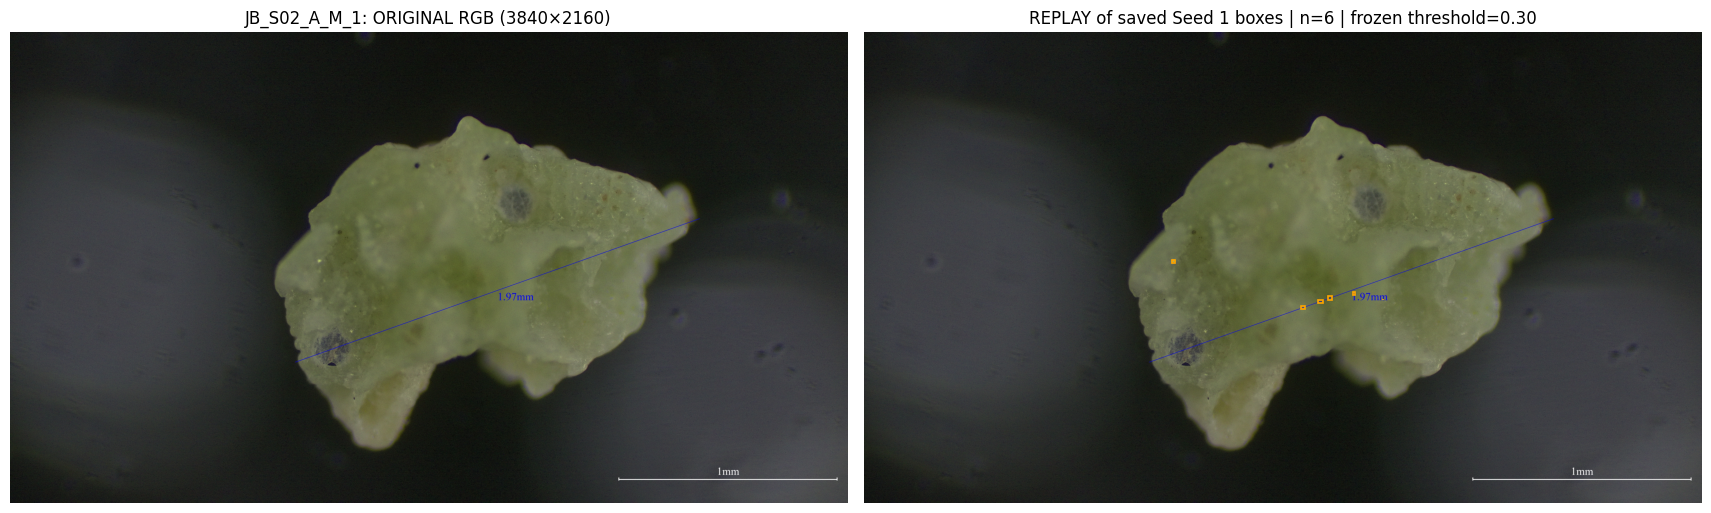

SAVED PREDICTION REPLAY ONLY — not new inference, GT or chemical ID.
Original saved overlay: JB_S02_A_M_1 / Seed 1 / n=6


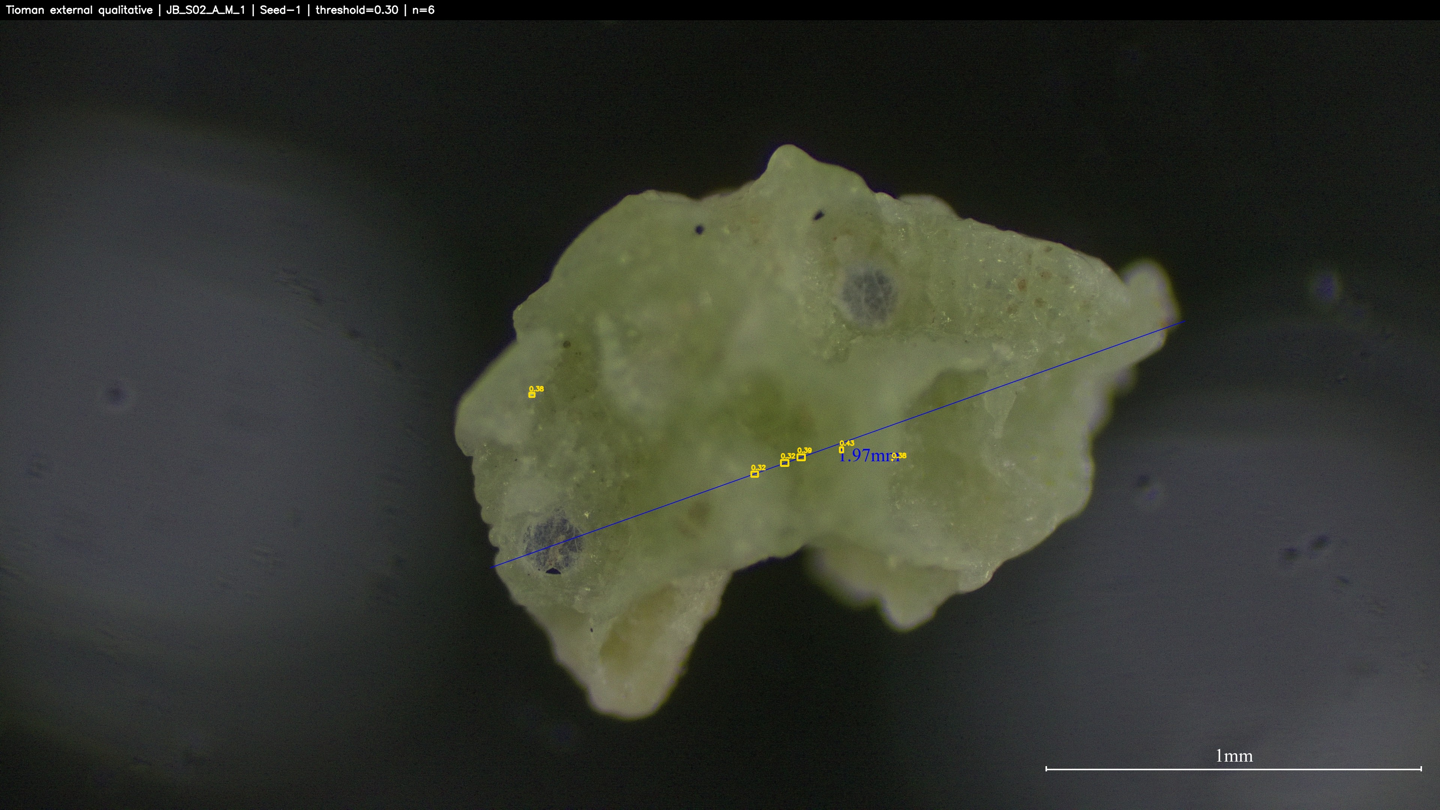

seed_index,Seed 1 (.30),Seed 2 (.35),Seed 3 (.35)
sample_code,,,
JB_S01_B_F_1,30,0,0
JB_S02_A_M_1,6,1,2
JB_S05_A_F_1,43,0,5
JB_S05_A_M_1,4,0,1
JB_S05_B_M_1,1,0,0
JB_S06_B_M_1,32,9,1
SLB_S01_A_M_1,2,3,10
SLB_S02_A_F_1,0,1,1
SLB_S03_A_L_1,1,2,9


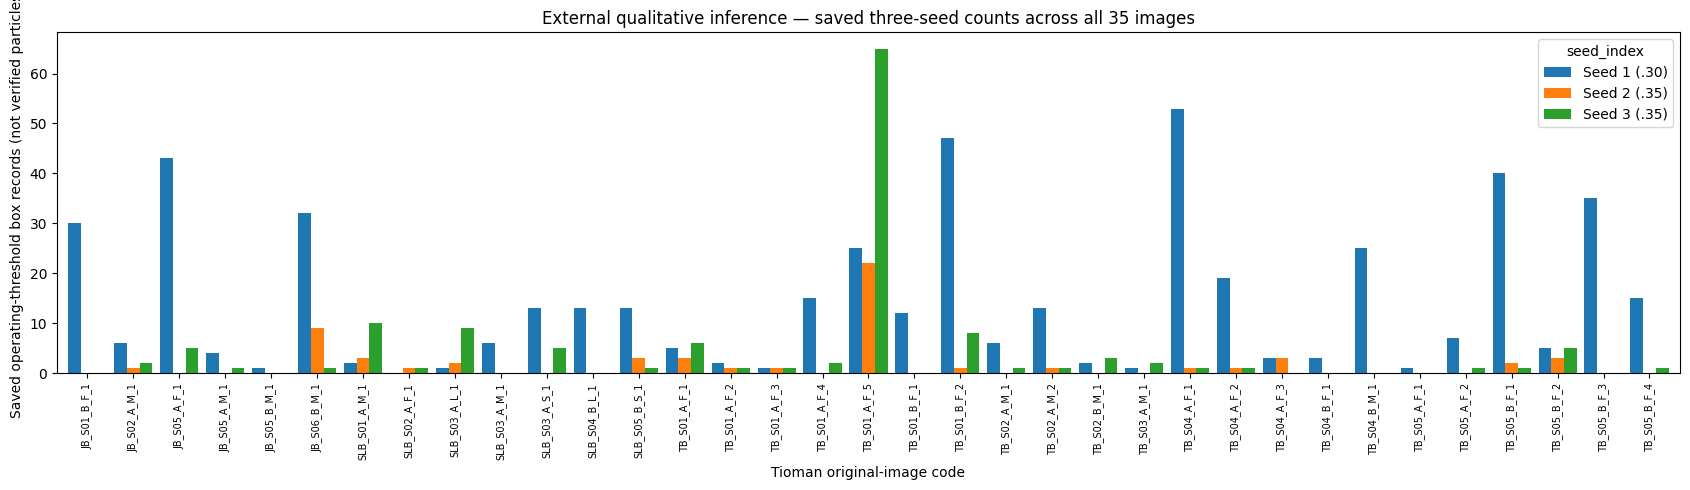

,Evaluation,Images,Metric,mean,sd
0,Synthetic untouched test,5000,Mask AP50,0.261600,0.021900
1,Synthetic untouched test,5000,Mask AP50:95,0.086700,0.005100
2,Synthetic untouched test,5000,Conditional Dice,0.805900,0.003400
3,Synthetic untouched test,5000,Count MAE,1.128500,0.071600
4,RSC original external test,250,Box AP50,0.030172,0.037769
5,RSC original external test,250,Box AP50:95,0.005761,0.007662
6,RSC original external test,250,Precision,0.081214,0.123416
7,RSC original external test,250,Recall,0.061224,0.104441
8,RSC original external test,250,F1,0.067937,0.114737
9,RSC original external test,250,Count MAE,1.629333,0.745218


CAUTION: Synthetic MASK AP vs external RSC BOX AP; unequal metrics/domains.
Tioman qualitative microscopy: NO object-level GT, NO valid AP, precision, recall, F1 or Dice.
PREDECLARED: JB_S01_B_F_1


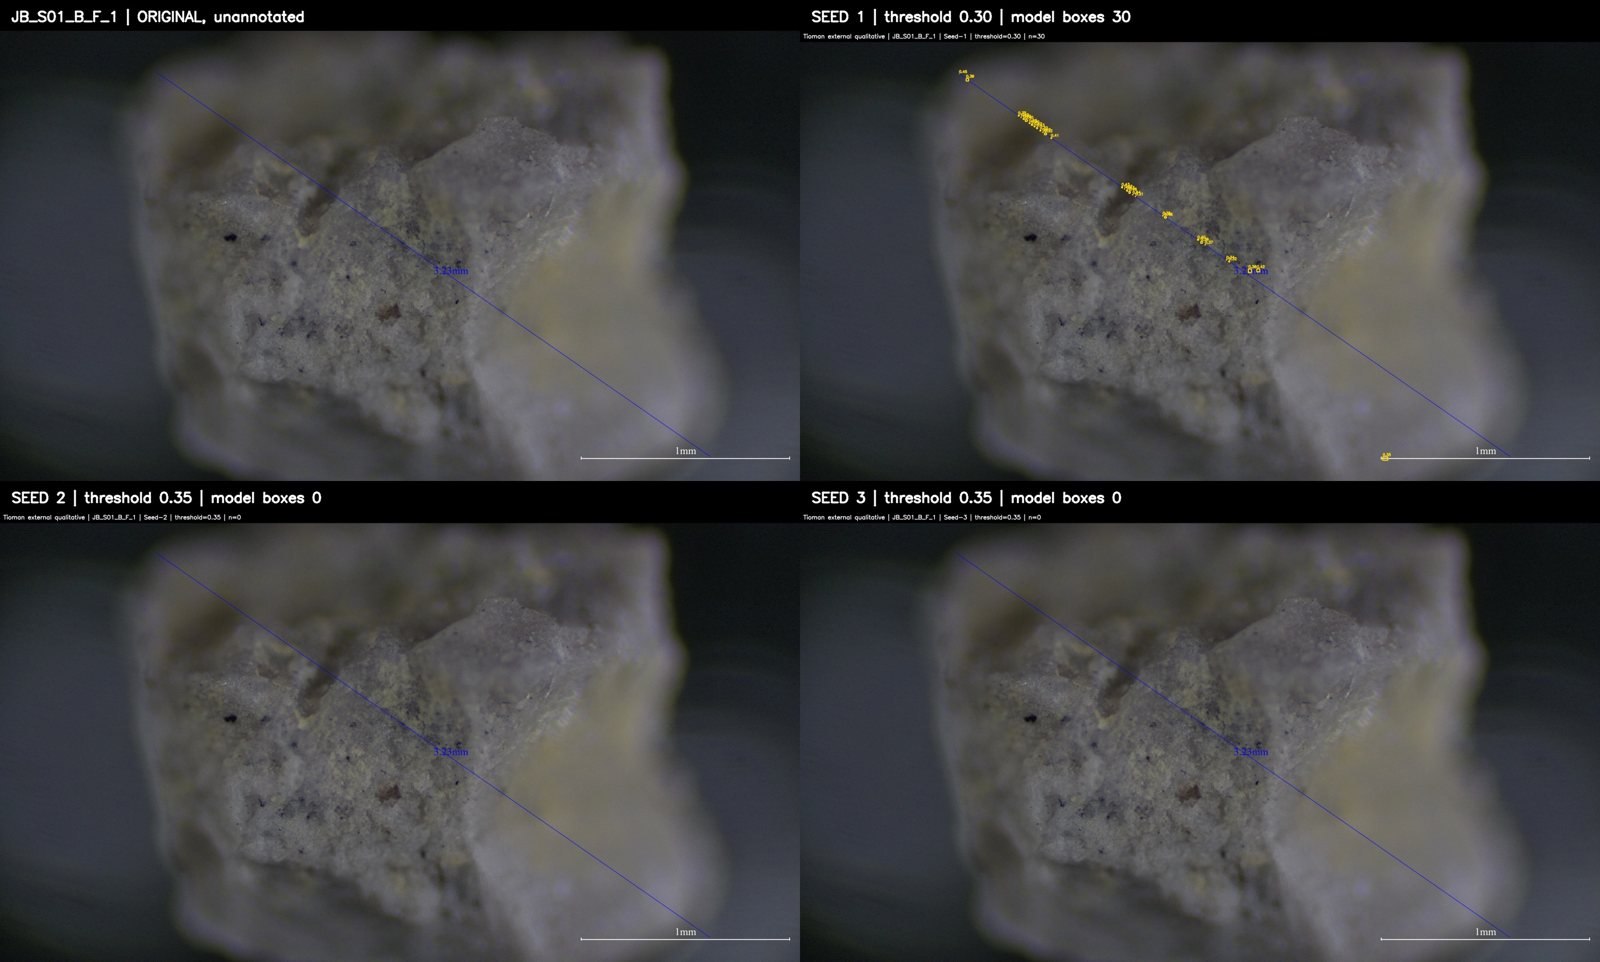

,reviewed_boxes,graphic_associations,other_image_features
sample_code,,,
JB_S01_B_F_1,30,30,0
JB_S02_A_M_1,9,6,3
SLB_S01_A_M_1,15,1,14
SLB_S02_A_F_1,2,0,2
TB_S01_A_F_1,14,1,13
TB_S01_A_F_2,4,2,2


The review is ChatGPT-assisted; not independently expert-validated.
Historical Tioman FTIR matches are SAMPLE-linked, not box-linked chemical ground truth.
FINAL IMPLEMENTATION DEMO STATUS: PASS_FINAL_IMPLEMENTATION_EVIDENCE_REPLAY_DEMO_v1
FROZEN BOX RECORDS: 499 + 58 + 135 = 692
FULL DATASET: 35 images x 3 checkpoints = 105 image-seed records
NEW ML FORWARDS EXECUTED: 0
DEMO REPORT: /kaggle/working/dasonet_final_readonly_implementation_demo_v1/DASONET_FINAL_IMPLEMENTATION_EVIDENCE_REPLAY_DEMO_v1.json
DEMO REPORT SHA256: 1ea9b3651de0ec691a326551ed097ec9cc7926420931eaef95e423967613437e
PER-IMAGE COUNT CSV: /kaggle/working/dasonet_final_readonly_implementation_demo_v1/DASONET_FROZEN_105_IMAGE_SEED_BOX_COUNTS_DEMO_v1.csv
INPUTS UNCHANGED; no Tioman GT metrics or chemical classifications.


In [5]:
# DASO-Net — archived scientific evidence replay demonstration v1
# This is the concatenation of notebook code cells for users who prefer
# one large Kaggle/Python cell. The .ipynb has scientific explanations.
# No model loading, inference, training, calibration or threshold changes.

# ========================================================================
from pathlib import Path, PurePosixPath
from datetime import datetime, timezone
from io import BytesIO
from collections import Counter
import csv
import hashlib
import json
import math
import zipfile

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from IPython.display import display, Markdown

EOD_ROOT = Path('/kaggle/input/datasets/abinavprabhuv/dasonet-eod-evidence-2026-10-15')
AUDITED = EOD_ROOT / 'DASO_Net_Tioman_Audited_Results_Evidence_v1'
NATIVE = EOD_ROOT / 'TIOMAN_NATIVE_RESOLUTION_REVIEW_EVIDENCE_v1'
FAILURES = EOD_ROOT / 'DASONET_TODAY_FAILED_RUNS_AND_AUDIT_TRAIL_v1'
TIOMAN_ROOT = Path('/kaggle/input/datasets/abinavprabhuv/dasonet-tioman-source-v1')

# This is the fresh output from the preceding scientific-freeze Kaggle cell.
# For a later session, supply either the mounted original ZIP path or its
# Kaggle-auto-extracted root through one of these two override variables.
REVIEW_ZIP_PATH_OVERRIDE = None
REVIEW_EXTRACTED_ROOT_OVERRIDE = None
CURRENT_REVIEW_ZIP = Path(
    '/kaggle/working/dasonet_tioman_qualitative_review_scientific_freeze_v1/'
    'DASONET_TIOMAN_QUALITATIVE_SCIENTIFIC_REVIEW_FREEZE_v1.zip'
)
EXPECTED_REVIEW_ZIP_SHA256 = '82bf2136dc5c72f7aa78c432edfbdb3590c308700df680fd9dc4f0bcc57047b3'
EXPECTED_REVIEW_VERIFICATION_SHA256 = 'e077302a043f8a11a54b7874c8fdaa2daf2ee4199662c5d8a89410b045b80c92'

PINS = {
    'protocol':'75b81b88550d7f76f6e7cecf27c4e805a281e350a99159ebba8c4447daaae563',
    'run_state':'d6ffb0c2ecdd418872ea4f5e44fe0c65856a10e74c0b348b7d5c1a5ac5315a05',
    'independent_audit':'580c41a77312a616ec94b5b7e32a61e284a47c925e30a16595e7f882a685247f',
    'model_definition':'1ac6f92e1683c6939ff5783ac0cae065dab20e366dd49a9b72ac89007e5eaa40',
    'frozen_decoder':'9799eb1be568e3d6e0ce82b7c99df7a0ed05d271cd44ff24b612526cc18537d1',
    'phase5c_eval':'9c6221b081121f34c0008c1ff49205758d5e551c01641b52de7643e5cf7e4e14',
}
SEEDS = [
    (1,1782656963,0.30,499,34,'e4c4b79ad4b8c6e18ba2b1e3d6cbe796c9cc301bd6fcc7c596fc290ad3a7e81d'),
    (2,901395089,0.35, 58,17,'19cdb834a46240916b2c8023e8c3afe5738d9c7cd5d8f818c62ad1e289df1ad2'),
    (3,252916394,0.35,135,25,'be7b7941f2f62179e15074aa973bf6da0eb9018ec9133486512bd1f87153f447'),
]
SIX = ('JB_S01_B_F_1','JB_S02_A_M_1','SLB_S01_A_M_1',
       'SLB_S02_A_F_1','TB_S01_A_F_1','TB_S01_A_F_2')


def require(condition, message):
    if not condition:
        raise RuntimeError(message)


def sha256_file(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(4 * 1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()


def safe_archive_name(name):
    require(isinstance(name, str) and name and '\\' not in name, 'Unsafe archive name')
    path = PurePosixPath(name)
    require(not path.is_absolute() and path.as_posix() == name and
            all(p not in ('','.','..') for p in name.split('/')),
            'Untrusted archive member: ' + repr(name))
    return name


def verify_digest(path, expected, description):
    path = Path(path)
    require(path.is_file() and not path.is_symlink(), f'Missing {description}: {path}')
    actual = sha256_file(path)
    require(actual == expected, f'{description}: SHA mismatch {actual} != {expected}')
    return path


def fresh_output(base):
    for index in range(100):
        candidate = base if index == 0 else Path(str(base) + f'_resume{index:02d}')
        if not candidate.exists():
            candidate.mkdir(parents=True, exist_ok=False)
            return candidate
    raise RuntimeError('All new demo output names are occupied; preserve prior runs')

print('Environment ready. No model libraries or weights have been loaded.')

# ========================================================================
def verify_expanded_evidence(root, manifest_name, expected_count, name_key, size_key):
    require(root.is_dir(), 'Required evidence input not mounted: ' + str(root))
    entries = list(root.rglob('*'))
    require(not any(p.is_symlink() for p in entries), 'Symlink in evidence folder: ' + str(root))
    files = {p.relative_to(root).as_posix():p for p in entries if p.is_file()}
    require(len(files) == expected_count,
            f'{root.name} file count {len(files)} != expected {expected_count}')
    require(manifest_name in files, 'Missing original manifest: ' + manifest_name)
    manifest = json.loads(files[manifest_name].read_text(encoding='utf-8'))
    records = manifest['files']
    require(len(records) == expected_count - 1,
            'Manifest does not describe exactly the extracted scientific files')
    names = [safe_archive_name(item[name_key]) for item in records]
    require(len(set(names)) == len(names) and set(names) == set(files) - {manifest_name},
            'Evidence manifest inventory and extracted files disagree')
    for item in records:
        filename = item[name_key]
        file = files[filename]
        require(file.stat().st_size == int(item[size_key]), 'Size mismatch: ' + filename)
        verify_digest(file, item['sha256'], filename)
    return files

sources = verify_expanded_evidence(
    AUDITED,'TIOMAN_AUDITED_RESULTS_PACKAGE_CONTENT_MANIFEST_v1.json',
    139,'archive_path','size_bytes')
native_files = verify_expanded_evidence(
    NATIVE,'TIOMAN_NATIVE_REVIEW_SOURCE_FILE_MANIFEST_v1.json',
    22,'path','bytes')
failure_files = verify_expanded_evidence(
    FAILURES,'MANIFEST_SHA256_v1.json',
    13,'zip_path','size_bytes')

frozen_paths = {
    'protocol':sources['protocol/TIOMAN_QUALITATIVE_TILING_PROTOCOL_FREEZE_v1.json'],
    'run_state':sources['run/TIOMAN_THREE_SEED_RUN_STATE_v1.json'],
    'independent_audit':sources['audit/TIOMAN_THREE_SEED_RESULTS_INTEGRITY_AUDIT_v1.json'],
    'model_definition':sources['frozen_reference/model_definition__dasonet.py'],
    'frozen_decoder':sources['frozen_reference/decoder__decoding.py'],
    'phase5c_eval':sources['frozen_reference/phase5c_evaluator__evaluate_phase5c.py'],
}
for key, path in frozen_paths.items():
    verify_digest(path,PINS[key],key)

protocol=json.loads(frozen_paths['protocol'].read_text(encoding='utf-8'))
run_state=json.loads(frozen_paths['run_state'].read_text(encoding='utf-8'))
ind_audit=json.loads(frozen_paths['independent_audit'].read_text(encoding='utf-8'))
require(run_state['status']=='COMPLETE_1260_TILE_FORWARDS_ALL_THREE_FROZEN_SEEDS' and
        run_state['completed_tile_forwards']==1260 and
        run_state['completed_images']==105,'Original completed run changed')
require(ind_audit['status']=='PASS_ALL_THREE_SEED_OUTPUTS_INDEPENDENTLY_RECONCILED',
        'Original scientific integrity audit is not PASS')
require(tuple(protocol['reported_outputs']['predeclared_example_codes'])==SIX,
        'Six examples differ from the pre-inference frozen protocol')

print('PASS: 139 audited inference + 22 native review + 13 failed-trial files SHA-verified')
print('PASS: model source/decoder/evaluator identities, complete run, independent audit')

# ========================================================================
review_zip = (Path(REVIEW_ZIP_PATH_OVERRIDE) if REVIEW_ZIP_PATH_OVERRIDE
              else CURRENT_REVIEW_ZIP)
review_root = (Path(REVIEW_EXTRACTED_ROOT_OVERRIDE)
               if REVIEW_EXTRACTED_ROOT_OVERRIDE else None)
REVIEW_MANIFEST = 'TIOMAN_QUALITATIVE_VISUAL_REVIEW_CONTENT_SHA256_MANIFEST_v1.json'

if review_zip.is_file():
    verify_digest(review_zip, EXPECTED_REVIEW_ZIP_SHA256, '32-member review freeze')
    with zipfile.ZipFile(review_zip) as z:
        require(z.testzip() is None, 'Review freeze ZIP CRC failed')
        names=z.namelist()
        require(len(names)==len(set(names))==32, 'Review ZIP must have exactly 32 unique members')
        require(REVIEW_MANIFEST in names, 'Review content SHA manifest absent')
        meta=json.loads(z.read(REVIEW_MANIFEST))
        manifest_rows=meta['files']
        require(len(manifest_rows)==31 and
                set(item['archive_path'] for item in manifest_rows)==set(names)-{REVIEW_MANIFEST},
                'Review ZIP manifest incomplete')
        for item in manifest_rows:
            name=safe_archive_name(item['archive_path'])
            blob=z.read(name)
            require(len(blob)==int(item['size_bytes']) and
                    hashlib.sha256(blob).hexdigest()==item['sha256'],
                    'Review ZIP member hash/size mismatch: '+name)
        review_data={name:z.read(name) for name in names}
    REVIEW_SOURCE_KIND = 'ORIGINAL_KAGGLE_ZIP_SHA_RECOMPUTED_AND_ALL_MEMBERS_VERIFIED'
else:
    require(review_root is not None and review_root.is_dir(),
        'Review ZIP not found. Set REVIEW_ZIP_PATH_OVERRIDE to your mounted '
        'DASONET_TIOMAN_QUALITATIVE_SCIENTIFIC_REVIEW_FREEZE_v1.zip, '
        'or REVIEW_EXTRACTED_ROOT_OVERRIDE to its auto-extracted folder. '
        'Do not recreate or change the scientific review.')
    seen={p.relative_to(review_root).as_posix():p for p in review_root.rglob('*') if p.is_file()}
    require(len(seen)==32 and REVIEW_MANIFEST in seen,
            'Extracted review freeze must contain exactly 32 original members')
    meta=json.loads(seen[REVIEW_MANIFEST].read_text(encoding='utf-8'))
    manifest_rows=meta['files']
    require(len(manifest_rows)==31 and
            set(i['archive_path'] for i in manifest_rows)==set(seen)-{REVIEW_MANIFEST},
            'Extracted review content SHA manifest incomplete')
    for item in manifest_rows:
        filename=safe_archive_name(item['archive_path'])
        file=seen[filename]
        require(not file.is_symlink() and file.stat().st_size==int(item['size_bytes']),
                'Unsafe or size-mismatched review evidence: '+filename)
        verify_digest(file,item['sha256'],filename)
    review_data={name:file.read_bytes() for name,file in seen.items()}
    REVIEW_SOURCE_KIND = 'EXTRACTED_REVIEW_MEMBERS_VERIFIED_ZIP_SHA_REFERENCE_ONLY'

review_rows=list(csv.DictReader(review_data[
    'review/TIOMAN_PREDECLARED_NATIVE_VISUAL_REVIEW_74_ROWS_v1.csv'
].decode('utf-8-sig').splitlines()))
require(len(review_rows)==74 and
        all(row['ground_truth_correctness']=='NOT_ASSESSED' and
            row['chemical_identity']=='NOT_ASSESSED' for row in review_rows),
        'Review rows mislabeled, missing or incorrectly assert GT/polymer identity')
association_count=Counter(row['visible_association_class'] for row in review_rows)
require(dict(association_count)=={
    'blue_measurement_line':30,'blue_measurement_text':5,
    'white_scale_bar':5,'other_image_feature':34,
}, 'Review classification totals differ')

# Independent linkage: every (image, seed, box ID) matches the original
# 74-box native crop index; no new or substituted detections allowed.
index=json.loads(native_files['TIOMAN_NATIVE_PREDICTION_CROP_INDEX_v1.json'].read_text())
expected_ids={
    (r['sample_code'],int(r['seed_index']),f"box{int(r['box_index_in_image_seed']):03d}")
    for r in index['index']
}
review_ids=[(r['sample_code'],int(r['seed_index']),r['box_id']) for r in review_rows]
require(len(expected_ids)==74 and len(set(review_ids))==74 and
        set(review_ids)==expected_ids,
        'Review IDs differ from the 74 frozen native crop index records')

current_verification=(review_zip.parent /
    'TIOMAN_QUALITATIVE_SCIENTIFIC_REVIEW_FREEZE_VERIFICATION_v1.json')
if current_verification.is_file() and review_root is None:
    verify_digest(current_verification,EXPECTED_REVIEW_VERIFICATION_SHA256,
                  'review freeze verification JSON')

print('PASS: 32-member qualitative scientific review freeze:', REVIEW_SOURCE_KIND)
print('PASS: 74/74 native crop IDs linked; graphic classes =', dict(association_count))

# ========================================================================
seed_predictions={}
per_image=[]
for idx,seed,threshold,expected_boxes,positive_images,ck_sha in SEEDS:
    key=f'seed{idx:02d}_s{seed}'
    path=sources[f'run/{key}/image_operating_predictions.jsonl']
    rows=[json.loads(line) for line in path.read_text(encoding='utf-8').splitlines() if line.strip()]
    require(len(rows)==35 and len({r['sample_code'] for r in rows})==35,
            key+' must have 35 unique original-image predictions')
    require(set(r['sample_code'] for r in rows)==set(p['sample_code'] for p in protocol['images']),
            key+' image population changed')
    require(sum(len(r['boxes']) for r in rows)==expected_boxes and
            sum(bool(r['boxes']) for r in rows)==positive_images,
            key+' frozen prediction count mismatch')
    seed_predictions[idx]={r['sample_code']:r for r in rows}
    for r in rows:
        require(int(r['seed_index'])==idx and int(r['seed'])==seed and
                r['checkpoint_sha256']==ck_sha and
                abs(float(r['frozen_operating_threshold'])-threshold)<1e-10,
                'Frozen checkpoint or threshold differs')
        require(r['original_size_wh']==[3840,2160] and r['tiles_evaluated']==12 and
                int(r['operating_owned_prediction_count'])==len(r['boxes']),
                'Frozen original-image output schema differs')
        for b in r['boxes']:
            box=b['image_box_xyxy']
            require(len(box)==4 and all(math.isfinite(float(v)) for v in box),
                    'Invalid saved image box')
            require(-1e-5<=box[0]<box[2]<=3840+1e-5 and
                    -1e-5<=box[1]<box[3]<=2160+1e-5 and
                    float(b['score'])>=threshold-1e-10 and
                    b['within_frozen_ownership_region'] is True and
                    b['passes_frozen_operating_threshold'] is True,
                    'Saved operating box fails its immutable geometric/score checks')
        per_image.append({'sample_code':r['sample_code'],
            'seed_index':idx,'training_seed':seed,'threshold':threshold,
            'frozen_operating_box_records':len(r['boxes']),
            'image_sha256':r['image_sha256'],
            'checkpoint_sha256':ck_sha})

df=pd.DataFrame(per_image).sort_values(['sample_code','seed_index']).reset_index(drop=True)
display(df.groupby('seed_index',sort=True)['frozen_operating_box_records']
        .agg(['count','sum',lambda x:(x>0).sum()])
        .rename(columns={'count':'images','sum':'seed_specific_boxes',
                         '<lambda_0>':'images_with_predictions'}))
require(len(df)==105 and int(df.frozen_operating_box_records.sum())==692,
        'All-image/seed run summary changed')
print('PASS 105 original-image/seed records, 692 frozen operating detection records')

# ========================================================================
reference_paths = pd.DataFrame([
    {'component':'DASO-Net architecture','verified_source':str(frozen_paths['model_definition']),
     'sha256':PINS['model_definition']},
    {'component':'Frozen decoder','verified_source':str(frozen_paths['frozen_decoder']),
     'sha256':PINS['frozen_decoder']},
    {'component':'Phase5C evaluator / model builder','verified_source':str(frozen_paths['phase5c_eval']),
     'sha256':PINS['phase5c_eval']},
    {'component':'Pre-inference Tioman protocol','verified_source':str(frozen_paths['protocol']),
     'sha256':PINS['protocol']},
])
display(reference_paths)
print('Original checkpoint identities:')
for i,s,t,total,present,h in SEEDS:
    print(f'  Seed {i}: train seed {s}, operating threshold {t:.2f}, '
          f'{total} archived boxes, checkpoint SHA-256 {h}')

# ========================================================================
protocol_images = {r['sample_code']:r for r in protocol['images']}


def show_saved_prediction_demo(sample_code, seed_index=1, max_width_px=1536):
    require(sample_code in protocol_images, 'Unknown frozen image code')
    require(seed_index in (1,2,3), 'Seed index must be 1, 2 or 3')
    info=protocol_images[sample_code]
    original=Path(info['image_path'])
    require(original.is_file(),
        'Original Tioman JPG is missing. Attach dasonet-tioman-source-v1 dataset. '
        'Frozen saved overlays can still be shown with show_archived_overlay().')
    verify_digest(original,info['image_sha256'],'original source JPG for '+sample_code)
    im=Image.open(original).convert('RGB')
    require(im.size==(3840,2160),'Original source geometry differs')
    prediction=seed_predictions[seed_index][sample_code]
    require(prediction['image_sha256']==info['image_sha256'],
            'Prediction references a different original microscopy image')
    operating=prediction['boxes']
    ratio=min(1.,max_width_px/3840.)
    fig,axes=plt.subplots(1,2,figsize=(17,5.2),constrained_layout=True)
    axes[0].imshow(im)
    axes[0].set_title(f'{sample_code}: ORIGINAL RGB (3840×2160)')
    axes[1].imshow(im)
    for record in operating:
        x1,y1,x2,y2=map(float,record['image_box_xyxy'])
        axes[1].add_patch(Rectangle((x1,y1),x2-x1,y2-y1,
            fill=False,linewidth=1.2,edgecolor='orange'))
    axes[1].set_title(
        f'REPLAY of saved Seed {seed_index} boxes | n={len(operating)} '
        f'| frozen threshold={prediction["frozen_operating_threshold"]:.2f}')
    for ax in axes:
        ax.axis('off')
    display(fig)
    plt.close(fig)
    print('SAVED PREDICTION REPLAY ONLY — not new inference, GT or chemical ID.')
    return {'sample_code':sample_code,'seed_index':seed_index,
            'frozen_prediction_count':len(operating),
            'original_image_sha256':info['image_sha256']}


DEMO_SAMPLE='JB_S02_A_M_1'    # change to any of 35 original frozen codes
DEMO_SEED=1                 # change to 1, 2, or 3
DEMO_DISPLAY=show_saved_prediction_demo(DEMO_SAMPLE, DEMO_SEED)

# ========================================================================
def show_archived_overlay(sample_code,seed_index=1):
    require(sample_code in protocol_images and seed_index in (1,2,3),
            'Unknown frozen image/seed selection')
    seed=SEEDS[seed_index-1][1]
    member=f'run/seed{seed_index:02d}_s{seed}/overlays_all35/'
    member+=f'{sample_code}__seed{seed_index:02d}_qualitative.jpg'
    require(member in sources,'Frozen overlay not in verified archive')
    img=Image.open(sources[member]).convert('RGB')
    require(img.size==(3840,2160),'Unexpected original frozen overlay geometry')
    print(f'Original saved overlay: {sample_code} / Seed {seed_index} '
          f'/ n={len(seed_predictions[seed_index][sample_code]["boxes"])}')
    display(img.resize((1440,810)))

show_archived_overlay(DEMO_SAMPLE,DEMO_SEED)

# ========================================================================
pivot=(df.pivot(index='sample_code',columns='seed_index',values='frozen_operating_box_records')
         .sort_index().rename(columns={1:'Seed 1 (.30)',2:'Seed 2 (.35)',3:'Seed 3 (.35)'}))
require(pivot.shape==(35,3),'Frozen count matrix must be 35×3')
display(pivot)
ax=pivot.plot(kind='bar',figsize=(17,5),width=0.83)
ax.set_ylabel('Saved operating-threshold box records (not verified particles)')
ax.set_xlabel('Tioman original-image code')
ax.set_title('External qualitative inference — saved three-seed counts across all 35 images')
plt.xticks(rotation=90,fontsize=7)
plt.tight_layout()
plt.show()

# ========================================================================
reference_metrics=pd.DataFrame([
 {'Evaluation':'Synthetic untouched test','Images':5000,'Metric':'Mask AP50','mean':0.2616,'sd':0.0219},
 {'Evaluation':'Synthetic untouched test','Images':5000,'Metric':'Mask AP50:95','mean':0.0867,'sd':0.0051},
 {'Evaluation':'Synthetic untouched test','Images':5000,'Metric':'Conditional Dice','mean':0.8059,'sd':0.0034},
 {'Evaluation':'Synthetic untouched test','Images':5000,'Metric':'Count MAE','mean':1.1285,'sd':0.0716},
 {'Evaluation':'RSC original external test','Images':250,'Metric':'Box AP50','mean':0.030172,'sd':0.037769},
 {'Evaluation':'RSC original external test','Images':250,'Metric':'Box AP50:95','mean':0.005761,'sd':0.007662},
 {'Evaluation':'RSC original external test','Images':250,'Metric':'Precision','mean':0.081214,'sd':0.123416},
 {'Evaluation':'RSC original external test','Images':250,'Metric':'Recall','mean':0.061224,'sd':0.104441},
 {'Evaluation':'RSC original external test','Images':250,'Metric':'F1','mean':0.067937,'sd':0.114737},
 {'Evaluation':'RSC original external test','Images':250,'Metric':'Count MAE','mean':1.629333,'sd':0.745218},
])
display(reference_metrics)
print('CAUTION: Synthetic MASK AP vs external RSC BOX AP; unequal metrics/domains.')
print('Tioman qualitative microscopy: NO object-level GT, NO valid AP, precision, recall, F1 or Dice.')

# ========================================================================
def show_qualitative_four_panel(sample_code):
    require(sample_code in SIX,'Only six predeclared review images may be displayed here')
    member=('primary_native_evidence/verified_four_panel_previews/'
            f'{sample_code}__original_and_three_frozen_seeds_review.jpg')
    require(member in review_data,'Missing verified predeclared montage')
    image=Image.open(BytesIO(review_data[member])).convert('RGB')
    print('PREDECLARED:',sample_code)
    display(image.resize((min(1600,image.width),int(image.height * min(1600,image.width)/image.width))))

show_qualitative_four_panel('JB_S01_B_F_1')

# ========================================================================
review_df=pd.DataFrame(review_rows)
sample_review=(review_df.assign(
        graphics=review_df['visible_association_class']!='other_image_feature')
        .groupby('sample_code',sort=False)
        .agg(reviewed_boxes=('box_id','size'),
             graphic_associations=('graphics','sum')))
sample_review['other_image_features']=(
    sample_review['reviewed_boxes']-sample_review['graphic_associations'])
require(int(sample_review.reviewed_boxes.sum())==74 and
        int(sample_review.graphic_associations.sum())==40,
        '74-box frozen six-sample review counts changed')
display(sample_review)
print('The review is ChatGPT-assisted; not independently expert-validated.')
print('Historical Tioman FTIR matches are SAMPLE-linked, not box-linked chemical ground truth.')

# ========================================================================
OUT=fresh_output(Path('/kaggle/working/dasonet_final_readonly_implementation_demo_v1'))
count_csv=OUT/'DASONET_FROZEN_105_IMAGE_SEED_BOX_COUNTS_DEMO_v1.csv'
df.to_csv(count_csv,index=False,lineterminator='\n')

reproduction_record={
 'status':'PASS_FINAL_IMPLEMENTATION_EVIDENCE_REPLAY_DEMO_v1',
 'created_utc':datetime.now(timezone.utc).isoformat(),
 'demonstration_mode':'ARCHIVED_INFERENCE_OUTPUT_REPLAY_ONLY_NO_MODEL_FORWARD',
 'source_evidence_files_verified':{'audited':139,'native':22,'failed_run_trail':13},
 'review_freeze_mode':REVIEW_SOURCE_KIND,
 'review_freeze_expected_original_zip_sha256':EXPECTED_REVIEW_ZIP_SHA256,
 'original_zip_sha_recomputed_here':REVIEW_SOURCE_KIND.startswith('ORIGINAL_KAGGLE_ZIP_'),
 'frozen_protocol_sha256':PINS['protocol'],
 'frozen_inference_state_sha256':PINS['run_state'],
 'independent_inference_integrity_audit_sha256':PINS['independent_audit'],
 'frozen_seed_prediction_counts':{str(idx):boxes for idx,_,_,boxes,_,_ in SEEDS},
 'frozen_image_seed_records':105,
 'frozen_tile_forwards_previously_executed':1260,
 'combined_seed_specific_box_records':692,
 'predeclared_six_sample_review_crops':74,
 'visually_graphic_associated_records':40,
 'other_visually_associated_records':34,
 'ground_truth_correctness_or_chemical_identity_assigned':False,
 'new_inference_training_or_tuning_performed':False,
 'interactive_demonstration_example':DEMO_DISPLAY,
 'frozen_counts_csv_sha256':sha256_file(count_csv),
 'scientific_limits':[
    'RGB screening predictions are not polymer identification',
    'Tioman has no object-level GT; no Tioman detection AP can be computed',
    'FTIR library matching is sample-linked, not box-level chemical GT',
    'RSC external BOX AP50 was 0.030172 +/- 0.037769 across frozen checkpoints',
    'Checkpoint and operating-threshold effects cannot be isolated from one another',
    'Historical derived JSON SHA discrepancies and failed runs remain preserved',
 ],
}
record_path=OUT/'DASONET_FINAL_IMPLEMENTATION_EVIDENCE_REPLAY_DEMO_v1.json'
record_path.write_text(json.dumps(reproduction_record,sort_keys=True,indent=2,
                            ensure_ascii=False,allow_nan=False)+'\n',encoding='utf-8')
record_digest=sha256_file(record_path)
(OUT/'DASONET_FINAL_IMPLEMENTATION_EVIDENCE_REPLAY_DEMO_v1.sha256.txt').write_text(
    f'{record_digest}  {record_path.name}\n',encoding='utf-8')
print('='*76)
print('FINAL IMPLEMENTATION DEMO STATUS:',reproduction_record['status'])
print('FROZEN BOX RECORDS: 499 + 58 + 135 = 692')
print('FULL DATASET: 35 images x 3 checkpoints = 105 image-seed records')
print('NEW ML FORWARDS EXECUTED: 0')
print('DEMO REPORT:',record_path)
print('DEMO REPORT SHA256:',record_digest)
print('PER-IMAGE COUNT CSV:',count_csv)
print('INPUTS UNCHANGED; no Tioman GT metrics or chemical classifications.')
print('='*76)



In [6]:
# ============================================================================
# DASO-Net — FINAL READ-ONLY REPRODUCIBILITY AUDIT v1
# Complete standalone Kaggle cell, for the notebook whose demo already passed.
# No model import/loading, forward, training, tuning, chemical labeling, or GT eval.
# ============================================================================
from pathlib import Path, PurePosixPath
from collections import Counter
from datetime import datetime, timezone
import csv
import hashlib
import json
import traceback
import zipfile

INPUT = Path('/kaggle/input/datasets/abinavprabhuv/dasonet-eod-evidence-2026-10-15')
AUDITED = INPUT / 'DASO_Net_Tioman_Audited_Results_Evidence_v1'
NATIVE = INPUT / 'TIOMAN_NATIVE_RESOLUTION_REVIEW_EVIDENCE_v1'
FAILURES = INPUT / 'DASONET_TODAY_FAILED_RUNS_AND_AUDIT_TRAIL_v1'
DEMO_DIR = Path('/kaggle/working/dasonet_final_readonly_implementation_demo_v1')
REVIEW_DIR = Path('/kaggle/working/dasonet_tioman_qualitative_review_scientific_freeze_v1')
OUT_BASE = Path('/kaggle/working/dasonet_final_reproducibility_audit_v1')

DEMO_SHA = '1ea9b3651de0ec691a326551ed097ec9cc7926420931eaef95e423967613437e'
REVIEW_SHA = '82bf2136dc5c72f7aa78c432edfbdb3590c308700df680fd9dc4f0bcc57047b3'
REVIEW_VERIFICATION_SHA = 'e077302a043f8a11a54b7874c8fdaa2daf2ee4199662c5d8a89410b045b80c92'
RESTART_SHA = '352ca54ed52de645050f06c6bcafaf5734c7c53f90520000dcd69b7406de6ded'
PINNED = {
    'protocol': '75b81b88550d7f76f6e7cecf27c4e805a281e350a99159ebba8c4447daaae563',
    'run': 'd6ffb0c2ecdd418872ea4f5e44fe0c65856a10e74c0b348b7d5c1a5ac5315a05',
    'audit': '580c41a77312a616ec94b5b7e32a61e284a47c925e30a16595e7f882a685247f',
    'model': '1ac6f92e1683c6939ff5783ac0cae065dab20e366dd49a9b72ac89007e5eaa40',
    'decoder': '9799eb1be568e3d6e0ce82b7c99df7a0ed05d271cd44ff24b612526cc18537d1',
    'evaluator': '9c6221b081121f34c0008c1ff49205758d5e551c01641b52de7643e5cf7e4e14',
}
SEEDS = [
    (1, 1782656963, .30, 499, 34, 'e4c4b79ad4b8c6e18ba2b1e3d6cbe796c9cc301bd6fcc7c596fc290ad3a7e81d'),
    (2, 901395089, .35, 58, 17, '19cdb834a46240916b2c8023e8c3afe5738d9c7cd5d8f818c62ad1e289df1ad2'),
    (3, 252916394, .35, 135, 25, 'be7b7941f2f62179e15074aa973bf6da0eb9018ec9133486512bd1f87153f447'),
]
SIX = ('JB_S01_B_F_1', 'JB_S02_A_M_1', 'SLB_S01_A_M_1',
       'SLB_S02_A_F_1', 'TB_S01_A_F_1', 'TB_S01_A_F_2')
CLASSES = {'blue_measurement_line':30, 'blue_measurement_text':5,
           'white_scale_bar':5, 'other_image_feature':34}


def need(value, reason):
    if not value:
        raise RuntimeError(reason)


def hash_file(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(4 * 1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()


def verify(path, expected, label):
    path = Path(path)
    need(path.is_file() and not path.is_symlink(), f'Missing/unsafe {label}: {path}')
    actual = hash_file(path)
    need(actual == expected, f'SHA256 differs ({label}): {actual} != {expected}')
    return path


def json_file(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))


def json_bytes(obj):
    return (json.dumps(obj, sort_keys=True, indent=2, ensure_ascii=False,
                       allow_nan=False) + '\n').encode('utf-8')


def valid_member(name):
    need(isinstance(name, str) and name and '\\' not in name,
         'Invalid archive name: ' + repr(name))
    path = PurePosixPath(name)
    need(not path.is_absolute() and path.as_posix() == name
         and all(segment not in ('', '.', '..') for segment in name.split('/')),
         'Unsafe/noncanonical archive path: ' + name)
    return name


def expanded(root, manifest_name, count, key, size_key):
    need(root.is_dir(), f'Evidence dataset not mounted: {root}')
    entries = list(root.rglob('*'))
    need(not any(p.is_symlink() for p in entries), f'Symlink in evidence: {root}')
    found = {p.relative_to(root).as_posix():p for p in entries if p.is_file()}
    need(len(found) == count, f'{root.name}: expected {count} files, found {len(found)}')
    need(manifest_name in found, 'Missing embedded content manifest: ' + manifest_name)
    manifest = json_file(found[manifest_name])
    rows = manifest['files']
    need(len(rows) == count - 1, 'Unexpected manifest row count in ' + str(root))
    names = [valid_member(row[key]) for row in rows]
    need(len(set(names)) == len(names) and set(names) == set(found) - {manifest_name},
         'Manifest/member population differs: ' + str(root))
    for row in rows:
        path = found[row[key]]
        need(path.stat().st_size == int(row[size_key]), 'Size differs: ' + row[key])
        verify(path, row['sha256'], row[key])
    return found


def sidecar_matches(sidecar, sha):
    need(sidecar.is_file(), 'Missing hash sidecar: ' + str(sidecar))
    need(sidecar.read_text(encoding='utf-8').split()[0] == sha,
         'SHA sidecar differs: ' + str(sidecar))


def new_dir():
    for i in range(100):
        path = OUT_BASE if i == 0 else Path(str(OUT_BASE) + f'_resume{i:02d}')
        if not path.exists():
            path.mkdir(parents=True, exist_ok=False)
            return path
    raise RuntimeError('No unused final-audit directory; previous outputs preserved')


print('=' * 78)
print('DASO-Net — FINAL READ-ONLY REPRODUCIBILITY AUDIT v1')
print('NO model loading / inference / training / tuning / new GT metrics')
print('=' * 78)
OUT = new_dir()
try:
    # A. Independently recheck original archived evidence (auto-extracted by Kaggle).
    archived = expanded(AUDITED,
        'TIOMAN_AUDITED_RESULTS_PACKAGE_CONTENT_MANIFEST_v1.json',
        139, 'archive_path', 'size_bytes')
    native = expanded(NATIVE,
        'TIOMAN_NATIVE_REVIEW_SOURCE_FILE_MANIFEST_v1.json',
        22, 'path', 'bytes')
    failed = expanded(FAILURES, 'MANIFEST_SHA256_v1.json',
                      13, 'zip_path', 'size_bytes')
    pinned_sources = {
        'protocol':'protocol/TIOMAN_QUALITATIVE_TILING_PROTOCOL_FREEZE_v1.json',
        'run':'run/TIOMAN_THREE_SEED_RUN_STATE_v1.json',
        'audit':'audit/TIOMAN_THREE_SEED_RESULTS_INTEGRITY_AUDIT_v1.json',
        'model':'frozen_reference/model_definition__dasonet.py',
        'decoder':'frozen_reference/decoder__decoding.py',
        'evaluator':'frozen_reference/phase5c_evaluator__evaluate_phase5c.py',
    }
    for label, member in pinned_sources.items():
        verify(archived[member], PINNED[label], label)
    protocol = json_file(archived[pinned_sources['protocol']])
    run = json_file(archived[pinned_sources['run']])
    old_audit = json_file(archived[pinned_sources['audit']])
    need(run['status'] == 'COMPLETE_1260_TILE_FORWARDS_ALL_THREE_FROZEN_SEEDS'
         and run['completed_tile_forwards'] == 1260 and run['completed_images'] == 105,
         'Frozen Tioman inference was not complete')
    need(old_audit['status'] == 'PASS_ALL_THREE_SEED_OUTPUTS_INDEPENDENTLY_RECONCILED',
         'Historical independent results audit is not PASS')
    need(old_audit['historical_json_byte_discrepancies_preserved'] is True,
         'Historical Tioman derived-JSON byte discrepancies no longer documented')
    need(tuple(protocol['reported_outputs']['predeclared_example_codes']) == SIX,
         'Predeclared sample identity changed')
    print('PASS source evidence: 139 + 22 + 13 files; protocol, decoder and run pins')

    # B. Independently cross-reference the demo report and 105-row CSV.
    report_path = DEMO_DIR / 'DASONET_FINAL_IMPLEMENTATION_EVIDENCE_REPLAY_DEMO_v1.json'
    report_path = verify(report_path, DEMO_SHA, 'executed final demo report')
    sidecar_matches(report_path.with_name(report_path.name.replace('.json','.sha256.txt')), DEMO_SHA)
    demo = json_file(report_path)
    need(demo['status'] == 'PASS_FINAL_IMPLEMENTATION_EVIDENCE_REPLAY_DEMO_v1'
         and demo['demonstration_mode'] == 'ARCHIVED_INFERENCE_OUTPUT_REPLAY_ONLY_NO_MODEL_FORWARD',
         'Demo did not report saved-inference replay success')
    need(demo['source_evidence_files_verified'] ==
         {'audited':139,'native':22,'failed_run_trail':13},
         'Demo evidence verification summary differs')
    need(demo['combined_seed_specific_box_records'] == 692
         and demo['frozen_image_seed_records'] == 105
         and demo['frozen_tile_forwards_previously_executed'] == 1260
         and demo['predeclared_six_sample_review_crops'] == 74,
         'Demo frozen population/counts differ')
    need(demo['visually_graphic_associated_records'] == 40
         and demo['other_visually_associated_records'] == 34,
         'Demo qualitative-review descriptive totals differ')
    need(demo['new_inference_training_or_tuning_performed'] is False
         and demo['ground_truth_correctness_or_chemical_identity_assigned'] is False,
         'Demo scientific-scope flag differs')
    need(demo['frozen_protocol_sha256'] == PINNED['protocol']
         and demo['frozen_inference_state_sha256'] == PINNED['run']
         and demo['independent_inference_integrity_audit_sha256'] == PINNED['audit'],
         'Demo report references another source run')
    need(demo['review_freeze_expected_original_zip_sha256'] == REVIEW_SHA
         and demo['original_zip_sha_recomputed_here'] is True,
         'Demo did not verify the actual original 32-member review ZIP')
    csv_path = DEMO_DIR / 'DASONET_FROZEN_105_IMAGE_SEED_BOX_COUNTS_DEMO_v1.csv'
    verify(csv_path, demo['frozen_counts_csv_sha256'], '105-row demo count CSV')
    with csv_path.open('r', newline='', encoding='utf-8') as stream:
        demo_csv = list(csv.DictReader(stream))
    need(len(demo_csv) == 105, 'Demo CSV is not 105 rows')
    saved_rows = {}
    for row in demo_csv:
        key = (row['sample_code'], int(row['seed_index']))
        need(key not in saved_rows, 'Duplicate demo image/seed row: ' + str(key))
        saved_rows[key] = row
    print('PASS executed demo report SHA + output CSV SHA and schema')

    # C. Reconstruct 105 image/seed counts from three separate frozen JSONLs,
    #    and cross-check independent earlier audited counts CSV.
    audit_csv = archived['audit/TIOMAN_THREE_SEED_PER_IMAGE_AUDITED_COUNTS_v1.csv']
    with audit_csv.open('r', newline='', encoding='utf-8') as stream:
        old_rows = list(csv.DictReader(stream))
    need(len(old_rows) == 105, 'Historical audited counts != 105')
    old_lookup = {}
    for row in old_rows:
        key = (row['sample_code'], int(row['seed_index']))
        need(key not in old_lookup, 'Duplicate earlier audit image/seed row')
        old_lookup[key] = row

    image_info = {row['sample_code']:row for row in protocol['images']}
    need(len(image_info) == 35, 'Frozen original source population != 35')
    total_boxes = 0
    by_seed = []
    for idx, seed, threshold, expected, positive, cksha in SEEDS:
        name = f'seed{idx:02d}_s{seed}'
        path = archived[f'run/{name}/image_operating_predictions.jsonl']
        predictions = [json.loads(line) for line in path.read_text(encoding='utf-8').splitlines() if line.strip()]
        need(len(predictions) == 35 and len({p['sample_code'] for p in predictions}) == 35,
             'Wrong image population: ' + name)
        have = 0
        nonzero = 0
        for p in predictions:
            code = p['sample_code']
            key = (code, idx)
            need(key in saved_rows and key in old_lookup and code in image_info,
                 'Missing 3-way count linkage: ' + str(key))
            a, b = saved_rows[key], old_lookup[key]
            n = len(p['boxes'])
            need(n == int(p['operating_owned_prediction_count'])
                 and n == int(a['frozen_operating_box_records'])
                 and n == int(b['owned_operating_boxes']),
                 'Demo, audited CSV and saved boxes disagree: ' + str(key))
            need(int(a['training_seed']) == seed
                 and abs(float(a['threshold']) - threshold) < 1e-10
                 and a['image_sha256'] == image_info[code]['image_sha256']
                 and a['checkpoint_sha256'] == cksha,
                 'Demo per-image frozen metadata differs: ' + str(key))
            need(int(b['training_seed']) == seed
                 and abs(float(b['operating_threshold']) - threshold) < 1e-10,
                 'Independent audit frozen threshold differs: ' + str(key))
            need(p['seed_index'] == idx and p['seed'] == seed
                 and p['checkpoint_sha256'] == cksha
                 and p['image_sha256'] == image_info[code]['image_sha256']
                 and abs(float(p['frozen_operating_threshold'])-threshold) < 1e-10,
                 'Prediction metadata differs: ' + str(key))
            have += n
            nonzero += bool(n)
        need(have == expected and nonzero == positive,
             'Seed totals changed: ' + name)
        need(run['seed_results'][name]['owned_operating_box_count'] == expected,
             'Frozen run state differs: ' + name)
        need(demo['frozen_seed_prediction_counts'][str(idx)] == expected,
             'Demo summary differs: ' + name)
        total_boxes += have
        by_seed.append({'seed_index':idx,'training_seed':seed,
                        'operating_threshold':threshold, 'image_count':35,
                        'image_with_predictions':positive,'saved_box_records':have})
    need(total_boxes == 692 and set(saved_rows) == set(old_lookup)
         and len(saved_rows) == 105, 'Unmatched image/seed records')
    print('PASS all 105 rows: demo CSV = independent audited CSV = saved JSONLs')

    # D. Verify all 35 original source JPG hashes from the frozen protocol.
    for code, info in sorted(image_info.items()):
        original = Path(info['image_path'])
        verify(original, info['image_sha256'], 'original Tioman JPG ' + code)
    print('PASS 35/35 original Tioman source JPG SHA256 identities')

    # E. Review scientific freeze, original ZIP, sidecar, membership and labels.
    review_zip = REVIEW_DIR / 'DASONET_TIOMAN_QUALITATIVE_SCIENTIFIC_REVIEW_FREEZE_v1.zip'
    verify(review_zip, REVIEW_SHA, '32-member qualitative review ZIP')
    sidecar_matches(review_zip.with_name(review_zip.name + '.sha256.txt'), REVIEW_SHA)
    verification_path = REVIEW_DIR / 'TIOMAN_QUALITATIVE_SCIENTIFIC_REVIEW_FREEZE_VERIFICATION_v1.json'
    verify(verification_path, REVIEW_VERIFICATION_SHA, 'qualitative freeze verification report')
    verdict = json_file(verification_path)
    need(verdict['status'] == 'PASS_QUALITATIVE_REVIEW_FROZEN_74_ROWS_FULL_READBACK_VERIFIED'
         and verdict['review_zip_sha256'] == REVIEW_SHA,
         'Review freeze was not verified')

    review_manifest_name = 'TIOMAN_QUALITATIVE_VISUAL_REVIEW_CONTENT_SHA256_MANIFEST_v1.json'
    with zipfile.ZipFile(review_zip,'r') as z:
        need(z.testzip() is None, 'Review freeze ZIP CRC check failed')
        members = z.namelist()
        need(len(members) == len(set(members)) == 32 and review_manifest_name in members,
             'Scientific-review ZIP member population differs')
        manifest = json.loads(z.read(review_manifest_name))
        records = manifest['files']
        need(len(records) == 31 and
             {valid_member(r['archive_path']) for r in records} == set(members) - {review_manifest_name},
             'Review ZIP content manifest is incomplete')
        for r in records:
            raw = z.read(r['archive_path'])
            need(len(raw) == r['size_bytes'] and
                 hashlib.sha256(raw).hexdigest() == r['sha256'],
                 'ZIP member digest differs: ' + r['archive_path'])
        review_csv = z.read('review/TIOMAN_PREDECLARED_NATIVE_VISUAL_REVIEW_74_ROWS_v1.csv').decode('utf-8-sig')
        review_rows = list(csv.DictReader(review_csv.splitlines()))
        need(len(review_rows) == 74, 'Review freeze must have 74 rows')
        review_index = json.loads(native['TIOMAN_NATIVE_PREDICTION_CROP_INDEX_v1.json'].read_text())
        ids = {(r['sample_code'], int(r['seed_index']),
                f"box{int(r['box_index_in_image_seed']):03d}") for r in review_index['index']}
        reviewed = [(r['sample_code'], int(r['seed_index']), r['box_id']) for r in review_rows]
        need(len(ids) == len(set(reviewed)) == 74 and set(reviewed) == ids,
             'Qualitative review IDs are not exactly the frozen crop index IDs')
        need(all(r['ground_truth_correctness'] == 'NOT_ASSESSED'
                 and r['chemical_identity'] == 'NOT_ASSESSED' for r in review_rows),
             'Review improperly assigns GT correctness or chemical identities')
        need(dict(Counter(r['visible_association_class'] for r in review_rows)) == CLASSES,
             'Review descriptive association categories differ')
        need(sum(r['sample_code'] == sample for r in review_rows for sample in SIX) == 74
             and set(r['sample_code'] for r in review_rows) == set(SIX),
             'Six predeclared visual sample coverage differs')
    print('PASS 32-member review ZIP and 74/74 frozen crop identities; no GT claims')

    # F. Save new audit ONLY to a fresh /kaggle/working directory.
    result = {
        'status':'PASS_FINAL_KAGGLE_IMPLEMENTATION_REPRODUCIBILITY_AUDIT_v1',
        'created_utc':datetime.now(timezone.utc).isoformat(),
        'scientific_mode':'READ_ONLY_PRESERVED_OUTPUTS_AND_DEMO_AUDIT',
        'verified_original_evidence_files':{'audited':139,'native':22,'failed_trials':13},
        'verified_tioman_original_jpgs':35,
        'frozen_seed_summaries':by_seed,
        'verified_image_seed_records':105,
        'verified_saved_operating_box_records':692,
        'verified_predeclared_review_records':74,
        'visual_review_association_counts':CLASSES,
        'frozen_protocol_sha256':PINNED['protocol'],
        'frozen_run_state_sha256':PINNED['run'],
        'independent_results_integrity_audit_sha256':PINNED['audit'],
        'successful_implementation_demo_report_sha256':DEMO_SHA,
        'implementation_demo_csv_sha256':demo['frozen_counts_csv_sha256'],
        'qualitative_review_freeze_original_zip_sha256_recomputed':REVIEW_SHA,
        'qualitative_review_verification_sha256':REVIEW_VERIFICATION_SHA,
        'previous_restarted_evidence_audit_sha256_reference':RESTART_SHA,
        'original_207MB_and_24MB_zip_sha_not_recomputed':True,
        'original_extracted_file_hash_manifests_independently_verified':True,
        'new_ml_forward_passes':0,
        'model_loaded':False,
        'training_tuning_or_calibration':False,
        'instance_ground_truth_on_tioman':False,
        'ftir_confirmed_identity_of_predicted_boxes':False,
        'review_expert_validated':False,
        'scientific_limits':[
            'The demonstration replays stored boxes; it does not invoke model inference.',
            'Tioman lacks per-object GT; no valid Tioman detection accuracy metrics.',
            'FTIR library matches are sample-linked, not chemically verified box labels.',
            'Qualitative visual classes are ChatGPT-assisted and not expert validated.',
            'Synthetic mask AP and RSC external box AP are different metrics.',
            'RSC mean external box AP50 remains 0.030172 +/- 0.037769.',
            'Historical failed runs and derived-JSON byte mismatches remain on record.',
        ],
    }
    report = OUT/'DASONET_FINAL_KAGGLE_IMPLEMENTATION_REPRODUCIBILITY_AUDIT_v1.json'
    report.write_bytes(json_bytes(result))
    digest = hash_file(report)
    (OUT/(report.stem+'.sha256.txt')).write_text(
        f'{digest}  {report.name}\n', encoding='utf-8')
    print('=' * 78)
    print('FINAL REPRODUCIBILITY STATUS:', result['status'])
    print('FROZEN COUNTS VERIFIED: 499 + 58 + 135 = 692')
    print('ORIGINAL IMAGES VERIFIED: 35/35')
    print('SAVED IMAGE-SEED RECORDS: 105/105')
    print('REVIEW BOX IDs VERIFIED: 74/74')
    print('NEW MODEL FORWARDS: 0')
    print('FINAL AUDIT REPORT:', report)
    print('FINAL AUDIT SHA256:', digest)
    print('NO model training, inference, retuning or Tioman chemical/GT labels.')
    print('Save the report and its hash sidecar to persistent storage.')
    print('=' * 78)
except BaseException as exc:
    failure = OUT/'DASONET_FINAL_REPRODUCIBILITY_FAILED_ATTEMPT_v1.json'
    failure.write_bytes(json_bytes({
        'status':'FAILED_FINAL_REPRODUCIBILITY_AUDIT_ATTEMPT_PRESERVED',
        'error_type':type(exc).__name__,
        'error':str(exc),
        'traceback':traceback.format_exc()[-15000:],
        'frozen_inputs_unchanged':True,
    }))
    print('FINAL AUDIT STOPPED; preserved failure report:', failure)
    raise


DASO-Net — FINAL READ-ONLY REPRODUCIBILITY AUDIT v1
NO model loading / inference / training / tuning / new GT metrics
PASS source evidence: 139 + 22 + 13 files; protocol, decoder and run pins
PASS executed demo report SHA + output CSV SHA and schema
PASS all 105 rows: demo CSV = independent audited CSV = saved JSONLs
PASS 35/35 original Tioman source JPG SHA256 identities
PASS 32-member review ZIP and 74/74 frozen crop identities; no GT claims
FINAL REPRODUCIBILITY STATUS: PASS_FINAL_KAGGLE_IMPLEMENTATION_REPRODUCIBILITY_AUDIT_v1
FROZEN COUNTS VERIFIED: 499 + 58 + 135 = 692
ORIGINAL IMAGES VERIFIED: 35/35
SAVED IMAGE-SEED RECORDS: 105/105
REVIEW BOX IDs VERIFIED: 74/74
NEW MODEL FORWARDS: 0
FINAL AUDIT REPORT: /kaggle/working/dasonet_final_reproducibility_audit_v1/DASONET_FINAL_KAGGLE_IMPLEMENTATION_REPRODUCIBILITY_AUDIT_v1.json
FINAL AUDIT SHA256: b647c9a88dba1189dd8af8dbe8ea52d42839e85c4b1efe69653467c3f4d96ecf
NO model training, inference, retuning or Tioman chemical/GT labels.
Save 

In [8]:
# =============================================================================
# DASO-Net — Stage A: scientific figures and tables, read-only Kaggle cell v1
# =============================================================================
# COPY ALL CONTENTS into one NEW Kaggle cell in the notebook where the final
# implementation demonstration and reproducibility audit have passed.
# This generates publication-oriented figures and CSV tables using existing
# evidence only. No torch/model loading/forwards, training, rethresholding,
# object-GT inference, chemical assignments, or architectural ablations.
# A new unused output directory is chosen; existing results are not overwritten.
# =============================================================================
from pathlib import Path, PurePosixPath
from collections import Counter, defaultdict
from datetime import datetime, timezone
from io import BytesIO, StringIO
import csv
import hashlib
import json
import math
import zipfile

import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image, ImageDraw, ImageFont

EOD = Path('/kaggle/input/datasets/abinavprabhuv/dasonet-eod-evidence-2026-10-15')
AUDITED = EOD / 'DASO_Net_Tioman_Audited_Results_Evidence_v1'
NATIVE = EOD / 'TIOMAN_NATIVE_RESOLUTION_REVIEW_EVIDENCE_v1'
FAIL = EOD / 'DASONET_TODAY_FAILED_RUNS_AND_AUDIT_TRAIL_v1'
REVIEW_ZIP = Path('/kaggle/working/dasonet_tioman_qualitative_review_scientific_freeze_v1/DASONET_TIOMAN_QUALITATIVE_SCIENTIFIC_REVIEW_FREEZE_v1.zip')
DEMO_DIR = Path('/kaggle/working/dasonet_final_readonly_implementation_demo_v1')
AUDIT_JSON = Path('/kaggle/working/dasonet_final_reproducibility_audit_v1/DASONET_FINAL_KAGGLE_IMPLEMENTATION_REPRODUCIBILITY_AUDIT_v1.json')
OUT_BASE = Path('/kaggle/working/dasonet_stage_a_readonly_figures_tables_v1')

PIN = {
 'review_zip': '82bf2136dc5c72f7aa78c432edfbdb3590c308700df680fd9dc4f0bcc57047b3',
 'demo_report': '1ea9b3651de0ec691a326551ed097ec9cc7926420931eaef95e423967613437e',
 'final_audit': 'b647c9a88dba1189dd8af8dbe8ea52d42839e85c4b1efe69653467c3f4d96ecf',
 'protocol': '75b81b88550d7f76f6e7cecf27c4e805a281e350a99159ebba8c4447daaae563',
 'run': 'd6ffb0c2ecdd418872ea4f5e44fe0c65856a10e74c0b348b7d5c1a5ac5315a05',
 'independent_audit': '580c41a77312a616ec94b5b7e32a61e284a47c925e30a16595e7f882a685247f',
 'model': '1ac6f92e1683c6939ff5783ac0cae065dab20e366dd49a9b72ac89007e5eaa40',
 'decoder': '9799eb1be568e3d6e0ce82b7c99df7a0ed05d271cd44ff24b612526cc18537d1',
}
SEEDS = (
 (1,1782656963,.30,499,34,'e4c4b79ad4b8c6e18ba2b1e3d6cbe796c9cc301bd6fcc7c596fc290ad3a7e81d'),
 (2,901395089,.35,58,17,'19cdb834a46240916b2c8023e8c3afe5738d9c7cd5d8f818c62ad1e289df1ad2'),
 (3,252916394,.35,135,25,'be7b7941f2f62179e15074aa973bf6da0eb9018ec9133486512bd1f87153f447'),
)
SIX = ('JB_S01_B_F_1','JB_S02_A_M_1','SLB_S01_A_M_1',
       'SLB_S02_A_F_1','TB_S01_A_F_1','TB_S01_A_F_2')
CLASSES = {'blue_measurement_line':30, 'blue_measurement_text':5,
           'white_scale_bar':5,'other_image_feature':34}
SYN = [
 ('Mask AP50',.2616,.0219),('Mask AP50:95',.0867,.0051),
 ('Conditional Dice',.8059,.0034),('Count MAE',1.1285,.0716),
]
RSC = [
 ('Box AP50',.030172,.037769),('Box AP50:95',.005761,.007662),
 ('Precision',.081214,.123416),('Recall',.061224,.104441),
 ('F1',.067937,.114737),('Count MAE',1.629333,.745218),
]


def need(ok, message):
    if not ok: raise RuntimeError(message)


def digest_file(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda:f.read(4*1024*1024), b''):
            h.update(block)
    return h.hexdigest()


def verify(path, expected, label):
    path=Path(path)
    need(path.is_file() and not path.is_symlink(), f'Missing or unsafe {label}: {path}')
    actual=digest_file(path)
    need(actual==expected,f'{label} SHA mismatch: {actual}')
    return path


def safe_member(name):
    need(isinstance(name,str) and name and '\\' not in name,'Unsafe member')
    p=PurePosixPath(name)
    need(not p.is_absolute() and p.as_posix()==name and all(t not in ('','.','..') for t in name.split('/')),
         'Unsafe member path: '+name)
    return name


def evidence_files(root, manifest_name, n, key, size_key):
    need(root.is_dir(), 'Missing mounted dataset: '+str(root))
    all_paths=list(root.rglob('*'))
    need(not any(p.is_symlink() for p in all_paths),'Symlink in evidence')
    files={p.relative_to(root).as_posix():p for p in all_paths if p.is_file()}
    need(len(files)==n and manifest_name in files, f'Expected {n} files at {root}')
    manifest=json.loads(files[manifest_name].read_text(encoding='utf-8'))
    rows=manifest['files']
    need(len(rows)==n-1,'Manifest row count differs')
    names=[safe_member(r[key]) for r in rows]
    need(len(set(names))==len(names) and set(names)==set(files)-{manifest_name},
         'Evidence inventory differs from manifest')
    for r in rows:
        f=files[r[key]]
        need(f.stat().st_size==int(r[size_key]), 'Evidence byte count differs')
        verify(f,r['sha256'],r[key])
    return files


def read_csv_text(text):
    return list(csv.DictReader(StringIO(text)))


def new_dir(base):
    for i in range(100):
        p=base if i==0 else Path(f'{base}_resume{i:02d}')
        if not p.exists():
            p.mkdir(parents=True,exist_ok=False)
            return p
    raise RuntimeError('No unused output folder: preserve prior attempts')


def write_csv(path, cols, rows):
    with Path(path).open('w',newline='',encoding='utf-8') as f:
        w=csv.DictWriter(f,fieldnames=cols,lineterminator='\n')
        w.writeheader()
        for r in rows: w.writerow({k:r.get(k,'') for k in cols})


def save_fig(fig, fig_dir, stem):
    fig.savefig(fig_dir/(stem+'.png'),dpi=300,bbox_inches='tight',facecolor='white')
    fig.savefig(fig_dir/(stem+'.svg'),bbox_inches='tight',facecolor='white')
    plt.close(fig)


def configure_plot():
    plt.rcParams.update({
        'font.family':'DejaVu Sans','font.size':10,'axes.titlesize':13,
        'axes.labelsize':10,'savefig.pad_inches':.16,'svg.fonttype':'none',
        'axes.spines.top':False,'axes.spines.right':False,
    })


# -----------------------------------------------------------------------------
# Publication figure/table construction — derived from source-pinned evidence.
# -----------------------------------------------------------------------------
import ast
import shutil
import textwrap
from matplotlib import colors
from matplotlib.ticker import MaxNLocator


def png_svg_pdf(fig, directory, stem, dpi=320):
    directory=Path(directory)
    fig.savefig(directory/(stem+'.png'),dpi=dpi,bbox_inches='tight',facecolor='white')
    fig.savefig(directory/(stem+'.pdf'),bbox_inches='tight',facecolor='white')
    fig.savefig(directory/(stem+'.svg'),bbox_inches='tight',facecolor='white')
    plt.close(fig)


def configure_paper():
    plt.rcParams.update({
      'font.family':'DejaVu Sans','font.size':10,'axes.titlesize':12,
      'axes.labelsize':10,'svg.fonttype':'none','pdf.fonttype':42,
      'savefig.pad_inches':0.17,'axes.spines.right':False,
      'axes.spines.top':False,'figure.facecolor':'white'})


def papersafe(s):
    s=str(s)
    return (s.replace('\\','\\textbackslash{}').replace('&','\\&')
             .replace('%','\\%').replace('$','\\$').replace('#','\\#')
             .replace('_','\\_').replace('{','\\{').replace('}','\\}')
             .replace('^','\\textasciicircum{}').replace('~','\\textasciitilde{}'))


def produce_table(root,name,headers,rows,desc,rendered=None):
    rows=[dict(zip(headers,r)) if not isinstance(r,dict) else r for r in rows]
    need(len({len(tuple(r.get(h,'') for h in headers)) for r in rows})<=1,'Table shapes differ')
    tab=Path(root)/'tables'; tab.mkdir(parents=True,exist_ok=True)
    write_csv(tab/(name+'.csv'),headers,rows)
    md='| '+' | '.join(headers)+' |\n|'+'|'.join(['---']*len(headers))+'|\n'
    for r in rows:
        md+='| '+' | '.join(str(r.get(h,'')).replace('|','\\|').replace('\n',' ') for h in headers)+' |\n'
    (tab/(name+'.md')).write_text('# '+name.replace('_',' ')+'\n\n'+desc+'\n\n'+md,encoding='utf-8')
    latex='\\begin{longtable}{' + ('l'*len(headers))+'}\n\\caption{'+papersafe(desc)+'}\\\\\n'
    latex+='\\toprule\n'+' & '.join(papersafe(h) for h in headers)+' \\\\\n\\midrule\n\\endfirsthead\n'
    latex+='\\toprule\n'+' & '.join(papersafe(h) for h in headers)+' \\\\\n\\midrule\n\\endhead\n'
    for row in rows:
        latex+=' & '.join(papersafe(row.get(h,'')) for h in headers)+' \\\\\n'
    latex+='\\bottomrule\n\\end{longtable}\n'
    (tab/(name+'.tex')).write_text('% Requires \\usepackage{booktabs,longtable}\n'+latex,encoding='utf-8')
    if rendered and rows:
        maxr=min(len(rows),int(rendered))
        sample=rows[:maxr]
        # Adapt to column count rather than creating unreadable narrow text.
        width=max(7.5,min(17,2.05*len(headers)))
        fig,ax=plt.subplots(figsize=(width, min(13,1.2+maxr*.45)))
        ax.axis('off')
        if len(rows)>maxr: ax.set_title(name+' — first '+str(maxr)+' of '+str(len(rows))+' rows',loc='left')
        else: ax.set_title(name.replace('_',' '),loc='left',pad=12)
        data=[[str(r.get(h,'')) for h in headers] for r in sample]
        table=ax.table(cellText=data,colLabels=headers,cellLoc='left',colLoc='left',loc='center')
        table.auto_set_font_size(False);table.set_fontsize(max(6.5,9-.18*max(0,len(headers)-5)))
        table.scale(1,1.55)
        for (ri,ci),cell in table.get_celld().items():
            cell.set_linewidth(.3);cell.set_edgecolor('#b8c5ce')
            cell.set_facecolor('#dce9f1' if ri==0 else ('#f3f7f9' if ri%2==0 else '#fff'))
            if ri==0:cell.set_text_props(weight='bold')
        out=Path(root)/'rendered_tables';out.mkdir(exist_ok=True)
        png_svg_pdf(fig,out,name,220)


def source_module_inventory(src_text):
    tree=ast.parse(src_text)
    table=[]
    for node in tree.body:
        if not isinstance(node,ast.ClassDef):continue
        attrs=[]
        for sub in ast.walk(node):
            if isinstance(sub,(ast.Assign,ast.AnnAssign)):
                targets = sub.targets if isinstance(sub,ast.Assign) else [sub.target]
                for target in targets:
                    if isinstance(target,ast.Attribute) and isinstance(target.value,ast.Name) and target.value.id=='self':
                        if target.attr not in attrs:attrs.append(target.attr)
        table.append({'class':node.name,'self_attributes_ast':', '.join(attrs[:16]),
                      'source_line':node.lineno,'note':'AST-inventory, not validated layer wiring'})
    if not table:
        table=[{'class':'NO_TOP_LEVEL_CLASS_DECLARATIONS', 'self_attributes_ast':'Not available',
                'source_line':'', 'note':'AST file inventory only; use frozen model source for topology'}]
    return table


def plot_box(ax,x,y,w,h,title,detail='',fc='#e8eff4',border='#476b82'):
    from matplotlib.patches import FancyBboxPatch
    p=FancyBboxPatch((x,y),w,h,boxstyle='round,pad=0.015,rounding_size=0.026',
                     facecolor=fc,edgecolor=border,lw=1.4)
    ax.add_patch(p)
    # Wrap text inside the actual box footprint: never assume fixed image sizes
    # or place full-width titles beyond a narrow box.
    title_width=max(14,int(w*7.7))
    detail_width=max(17,int(w*10))
    wrapped_title=textwrap.fill(title,width=title_width,break_long_words=False)
    wrapped_detail=textwrap.fill(detail,width=detail_width,break_long_words=False)
    title_lines=wrapped_title.count('\n')+1
    detail_lines=wrapped_detail.count('\n')+1 if detail else 0
    title_font=9.2 if w<3 else 9.7
    detail_font=7.5 if w<3 else 8.2
    if h < 1:
        title_y=y+h*(.66 if title_lines==1 else .66)
        detail_y=y+h*.22
    else:
        title_y=y+h*(.65 if title_lines==1 else .69)
        detail_y=y+h*.23
    ax.text(x+w/2,title_y,wrapped_title,ha='center',va='center',
            size=title_font,weight='bold',color='#213d50',linespacing=1.1)
    if detail:
        ax.text(x+w/2,detail_y,wrapped_detail,ha='center',va='center',
                size=detail_font,color='#344d60',linespacing=1.15)


def visual_architecture(figdir,inventory):
    fig,ax=plt.subplots(figsize=(13.3,4.0));ax.set_xlim(0,14);ax.set_ylim(0,4.1);ax.axis('off')
    plot_box(ax,.15,1.28,2.25,1.3,'Original Tioman RGB','3,840 × 2,160 pixels')
    plot_box(ax,2.88,1.28,2.33,1.3,'Frozen tiling','12 overlapping 1,024² tiles')
    plot_box(ax,5.69,1.28,2.55,1.3,'Frozen DASO-Net','3 checkpoints; 2,750 updates each',fc='#d9e9f3')
    plot_box(ax,8.73,1.28,2.30,1.3,'Frozen decoder','stride 4; top-k 100; NMS 0.5')
    plot_box(ax,11.5,1.28,2.35,1.3,'Ownership + saving','boxes and scores; counts',fc='#e1f0e8')
    for x1,x2 in [(2.42,2.85),(5.23,5.67),(8.26,8.71),(11.05,11.48)]:
        ax.annotate('',xy=(x2,1.93),xytext=(x1,1.93),arrowprops={'arrowstyle':'->','lw':1.7,'color':'#406277'})
    ax.text(7,.52,'Prediction thresholds: Seed 1 = 0.30; Seeds 2 and 3 = 0.35. No extra cross-tile NMS.',
            ha='center',fontsize=9.5,color='#314a5b')
    ax.text(7,3.50,'SOURCE-PINNED SYSTEM PIPELINE (not a layer-by-layer neural-network diagram)',
            ha='center',fontsize=13,weight='bold')
    ax.text(7,3.05,'Network class and AST attribute inventory is supplied separately; no model code is executed.',
            ha='center',fontsize=9.5)
    png_svg_pdf(fig,figdir,'F01_system_architecture_and_inference_pipeline')


def visual_workflow(figdir):
    fig,ax=plt.subplots(figsize=(12.8,4.7));ax.set_xlim(0,13);ax.set_ylim(0,5);ax.axis('off')
    ax.text(6.5,4.65,'Research workflow and evidence boundaries',ha='center',size=13.5,weight='bold')
    for y,name,note,c in [
      (3.23,'Synthetic training / untouched test','5,000 untouched test images; mask metrics','#dcecf4'),
      (2.10,'Original RSC external evaluation','250 images; 539 GT boxes; box metrics','#f5e3dc'),
      (.97,'Tioman microscopy qualitative transfer','35 RGB images × 3 checkpoints; no object GT','#e6eee4')]:
        plot_box(ax,.25,y,4.05,.88,name,note,fc=c)
    plot_box(ax,5.10,1.65,2.8,1.6,'Frozen evaluation evidence','unaltered model/decoder\n+ source integrity checks')
    plot_box(ax,8.77,1.65,3.78,1.6,'Read-only paper assets','plots, summary tables, six visual cases\n74-descriptive-crop review',fc='#e7f3ea')
    for y in (3.7,2.54,1.41):
        ax.annotate('',(5.08,2.46),(4.34,y),arrowprops={'arrowstyle':'->','color':'#657b8a','lw':1.5})
    ax.annotate('',(8.73,2.46),(7.94,2.46),arrowprops={'arrowstyle':'->','lw':1.7})
    ax.text(6.5,.34,'No architecture ablation verified | no Tioman GT metrics | no box-level FTIR identity',
            color='#833f31',ha='center',size=10,weight='bold')
    png_svg_pdf(fig,figdir,'F02_research_and_evidence_workflow')


def visual_tiling(figdir):
    fig,ax=plt.subplots(figsize=(10.6,5.5))
    ax.add_patch(Rectangle((0,0),3840,2160,facecolor='#e9eef2',edgecolor='#2d3741',lw=2))
    for j,y in enumerate((0,568,1136)):
        for i,x in enumerate((0,939,1877,2816)):
            ax.add_patch(Rectangle((x,y),1024,1024,fill=False,edgecolor='#247198',lw=1.5))
            ax.text(x+512,y+512,str(j*4+i+1),ha='center',va='center',fontsize=14,weight='bold',color='#2b6986')
    ax.set_xlim(-100,3940);ax.set_ylim(2260,-100);ax.set_aspect('equal')
    ax.set_title('Frozen Tioman 4 × 3 tiling schedule (not optimized on Tioman)')
    ax.set_xlabel('Original x coordinate [px]');ax.set_ylabel('Original y coordinate [px]')
    ax.text(.5,-.18,'1,024 × 1,024 tiles | x origins: 0, 939, 1877, 2816 | y origins: 0, 568, 1136\n'
             'Ownership determined by predicted-box center; no additional cross-tile NMS',
             transform=ax.transAxes,ha='center',fontsize=9)
    png_svg_pdf(fig,figdir,'F03_frozen_Tioman_tiling_geometry')


def horizontal_metric_figure(figdir,stem,title,records,unitlabel,color,scale=1):
    labs=[r[0] for r in records]; val=np.array([r[1] for r in records]); s=np.array([r[2] for r in records])
    fig,ax=plt.subplots(figsize=(9.5,max(3.25,1.25+len(records)*.65)))
    y=np.arange(len(labs))
    ax.barh(y,val,height=.5,color=color)
    ax.errorbar(val,y,xerr=[np.minimum(s,val),s],fmt='none',ecolor='#263c48',lw=1.1,capsize=3)
    ax.set_yticks(y,labs);ax.invert_yaxis();ax.grid(axis='x',alpha=.17)
    xmax=float((val+s).max()); ax.set_xlim(0,max(scale,xmax*1.65))
    ax.set_xlabel(unitlabel);ax.set_title(title)
    for i,(v,e) in enumerate(zip(val,s)):
        ax.text(v+e+.011*ax.get_xlim()[1],i,f'{v:.4f} ± {e:.4f}',ha='left',va='center',fontsize=9)
    png_svg_pdf(fig,figdir,stem)


def visual_per_sample_heatmap(figdir,samples,C):
    fig,ax=plt.subplots(figsize=(7.5,12.6))
    im=ax.imshow(C,aspect='auto',cmap='YlGnBu',vmin=0,vmax=int(C.max()),interpolation='nearest')
    ax.set_xticks(range(3),['Seed 1\n0.30','Seed 2\n0.35','Seed 3\n0.35'])
    ax.set_yticks(range(35),samples,fontsize=8)
    for r in range(35):
        for c in range(3):
            v=int(C[r,c]);ax.text(c,r,str(v),ha='center',va='center',fontsize=7.8,
                color=('white' if v>int(C.max())*.52 else '#172b38'))
    fig.colorbar(im,ax=ax,shrink=.62,label='Operating box records (not verified particles)')
    ax.set_title('Tioman: 35 original images × 3 frozen checkpoints',pad=13)
    png_svg_pdf(fig,figdir,'F07_Tioman_35x3_raw_count_heatmap')



def visual_source_class_inventory(figdir, inventory):
    # This is a source-level inventory, NOT an invented neural-layer wiring graph.
    rows=inventory[:min(12,len(inventory))]
    fig,ax=plt.subplots(figsize=(12.0,max(3.6,1.75+.43*len(rows))))
    ax.axis('off')
    fields=['Class defined in frozen source','AST-assigned self attributes (truncated)']
    vals=[]
    for r in rows:
        attrs=r['self_attributes_ast'] or 'No self assignments extracted'
        attrs=(attrs[:79]+'…') if len(attrs)>80 else attrs
        vals.append([r['class'],attrs])
    tb=ax.table(cellText=vals,colLabels=fields,colWidths=[.28,.72],cellLoc='left',loc='center')
    tb.auto_set_font_size(False);tb.set_fontsize(8.6);tb.scale(1,1.5)
    for (i,j),cell in tb.get_celld().items():
        cell.set_linewidth(.3);cell.set_edgecolor('#b7c6d1')
        cell.set_facecolor('#dceaf3' if i==0 else '#f4f7f9' if i%2==0 else 'white')
        if i==0:cell.set_text_props(weight='bold')
    ax.set_title('Class/module inventory extracted from SHA-pinned model source (AST only)',
                 pad=13,weight='bold')
    fig.text(.5,.03,'No claim of execution order or complete layer topology; see T12 for all declarations.',
             ha='center',fontsize=9,color='#425a69')
    png_svg_pdf(fig,figdir,'F16_frozen_model_source_class_inventory',240)


def visual_contact_sheet(figdir,montage_bytes):
    # IMPORTANT: no assumed size; each original four-panel file keeps its actual
    # dimensions. Constrained image fitting prevents failures on heterogeneous JPGs.
    cell_w,cell_h=1720,1140
    pad,title_h=32,62
    sheet=Image.new('RGB',(pad+2*(cell_w+pad),pad+3*(cell_h+pad)),(247,249,251))
    draw=ImageDraw.Draw(sheet)
    try:font=ImageFont.truetype('/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf',32)
    except OSError:font=ImageFont.load_default()
    sizes={}
    for j,s in enumerate(SIX):
        with Image.open(BytesIO(montage_bytes[s])) as src:
            sizes[s]=list(src.size)
            im=src.convert('RGB')
        # ImageOps.contain would also work but thumbnail avoids interpolation upscaling.
        im.thumbnail((cell_w,cell_h-title_h-8),Image.Resampling.LANCZOS)
        cx=pad+(j%2)*(cell_w+pad);cy=pad+(j//2)*(cell_h+pad)
        draw.text((cx,cy+5),s,fill='#22394e',font=font)
        xx=cx+(cell_w-im.width)//2
        sheet.paste(im,(xx,cy+title_h))
    dest=figdir/'F13_six_frozen_four_panel_comparisons_contact_sheet.png'
    sheet.save(dest,optimize=True)
    sheet.save(figdir/'F13_six_frozen_four_panel_comparisons_contact_sheet.pdf',resolution=200)
    return sizes


def visual_native_example(figdir,native_pages):
    # Human-friendly montage of FOUR unchanged atlas pages. The 12 full-resolution
    # original pages are separately included in supplementary evidence folder.
    choices=['JB_S01_B_F_1__native_prediction_crops_page01.png',
             'SLB_S01_A_M_1__native_prediction_crops_page01.png',
             'TB_S01_A_F_1__native_prediction_crops_page01.png',
             'TB_S01_A_F_2__native_prediction_crops_page01.png']
    need(all(k in native_pages for k in choices),'Representative native atlases missing')
    fig,axes=plt.subplots(2,2,figsize=(14,13))
    labels=['JB: measurement-line responses','SLB: translucent texture + white scale bar',
            'TB: fibrous features + scale bar','TB: two scale-bar responses']
    for ax,name,label in zip(axes.ravel(),choices,labels):
        with Image.open(BytesIO(native_pages[name])) as im:
            im=im.convert('RGB');im.thumbnail((1400,1400),Image.Resampling.LANCZOS)
            ax.imshow(im)
        ax.set_title(label,fontsize=11);ax.axis('off')
    fig.suptitle('Selected source native-crop atlas pages (full originals supplied separately)',fontsize=13)
    fig.tight_layout()
    png_svg_pdf(fig,figdir,'F14_selected_native_visual_review_atlases',220)


def produce_paper_pack(out,count_records,review_records,montage_bytes,original_pages,source_text,upstream):
    figs=out/'figures';figs.mkdir();configure_paper()
    samples=sorted({r['sample_code'] for r in count_records})
    count_map={}
    for r in count_records:
        k=(r['sample_code'],int(r['seed_index']))
        need(k not in count_map,'Repeated image-seed prediction row')
        count_map[k]=int(r['frozen_operating_box_records'])
    need(len(samples)==35 and len(count_map)==105 and
         set(count_map)=={(s,i) for s in samples for i in (1,2,3)},'Incomplete 35x3 image-seed matrix')
    C=np.array([[count_map[s,i] for i in (1,2,3)] for s in samples],int)
    need((C.sum(0)==[499,58,135]).all() and ((C>0).sum(0)==[34,17,25]).all(),
         'Saved seed totals noncanonical')
    need(len(review_records)==74,'74 native crops required')
    buckets=Counter(r['visible_association_class'] for r in review_records)
    need(dict(buckets)==CLASSES,'Qualitative review classes mismatch')
    need(all(r['ground_truth_correctness']=='NOT_ASSESSED' and r['chemical_identity']=='NOT_ASSESSED'
             for r in review_records),'Unexpected ground truth/chemical assignment')
    by_sample={s:Counter() for s in SIX};ids=set()
    for r in review_records:
        s=r['sample_code'];i=int(r['seed_index']);box=r['box_id']
        need(s in SIX and i in (1,2,3),'Unexpected sample/seed in original qualitative evidence')
        need((s,i,box) not in ids,'Duplicate native review box');ids.add((s,i,box))
        by_sample[s]['total']+=1;by_sample[s]['seed'+str(i)]+=1
        by_sample[s]['graphic' if r['visible_association_class']!='other_image_feature' else 'other']+=1
    need(len(ids)==74 and sum(by_sample[s]['graphic'] for s in SIX)==40,'74-crop review mismatch')
    need(all(by_sample[s]['total']==sum(count_map[s,i] for i in (1,2,3)) for s in SIX),
         'Predeclared review count mismatch')
    need(set(montage_bytes)==set(SIX) and len(original_pages)==12,'Frozen photo and atlas inventory differs')

    ast_rows=source_module_inventory(source_text)
    produce_table(out,'T01_dataset_scope',
        ['dataset','original_images','reference_information','per_object_GT','per_detection_chemical_ID'],[
        ['Synthetic untouched test','5000','Synthetic instance masks','Synthetic GT','Unavailable'],
        ['Original RSC external test','250','539 original reference boxes','Bounding-box GT','Unavailable'],
        ['Tioman original external microscopy','35','35 sample-linked FTIR candidate reports','Unavailable','Unavailable']],
        'Dataset partitions and reference information; sample-linked FTIR is not detection-level identity',rendered=5)
    produce_table(out,'T02_frozen_checkpoints',
        ['seed','training_seed','updates','operating_threshold','box_records','nonzero_images','checkpoint_sha256'],[
        [idx,s,2750,f'{t:.2f}',boxes,pos,h] for idx,s,t,boxes,pos,h in SEEDS],
        'Three original frozen checkpoints; operating thresholds differ (no ablation)',rendered=5)
    produce_table(out,'T03_synthetic_untouched_test',
        ['metric','mean','between_seed_SD','test_images','type'],[
        [n,f'{m:.6f}',f'{d:.6f}',5000,('count' if 'MAE' in n else 'mask')]
        for n,m,d in SYN],'Frozen synthetic performance: three-seed mean and SD; conditional Dice is subset-conditioned',rendered=6)
    produce_table(out,'T04_RSC_external_test',
        ['metric','mean','between_seed_SD','test_images','type'],[
        [n,f'{m:.6f}',f'{d:.6f}',250,('count' if 'MAE' in n else 'box')]
        for n,m,d in RSC],'Frozen original RSC external-domain evaluation; weak generalization',rendered=8)
    produce_table(out,'T05_Tioman_seed_summary',
        ['seed','threshold','images','images_with_1plus_boxes','box_records','fraction_images_with_1plus'],[
        [idx,f'{t:.2f}',35,pos,boxes,f'{pos/35:.4f}'] for idx,s,t,boxes,pos,h in SEEDS],
        'Tioman seed-specific records; counts are not unique particles and thresholds differ',rendered=5)
    produce_table(out,'T06_Tioman_35_image_counts',
        ['sample_code','seed_1_thr_030','seed_2_thr_035','seed_3_thr_035','sum_seed_records','predeclared_example'],[
        [s,*C[j].tolist(),int(C[j].sum()),'Yes' if s in SIX else 'No']
        for j,s in enumerate(samples)],
        'All 35 microscopy samples with archived operating prediction counts',rendered=0)
    produce_table(out,'T07_six_predeclared_visual_cases',
        ['sample_code','seed_1','seed_2','seed_3','reviewed_records','graphic_associations','other_features'],[
        [s,*[by_sample[s]['seed'+str(i)] for i in (1,2,3)],by_sample[s]['total'],
         by_sample[s]['graphic'],by_sample[s]['other']] for s in SIX],
        'Six predeclared native-resolution review cases; descriptive associations only',rendered=7)
    produce_table(out,'T08_visual_association_classes',
        ['description','record_count','scope'],[
        ['Blue measurement line',30,'Six predeclared cases'],
        ['Blue measurement text',5,'Six predeclared cases'],
        ['White scale bar',5,'Six predeclared cases'],
        ['Other image feature',34,'Six predeclared cases']],
        'Visual associations from ChatGPT-assisted review of 74 records; NOT ground truth',rendered=6)
    produce_table(out,'T09_frozen_decoder_and_tiling',
        ['parameter','frozen_value','interpretation'],[
        ['Tioman source image','3840 × 2160','Original microscopy RGB'],
        ['Tiling','4 × 3, 12 tiles/image','Fixed pre-inference protocol'],
        ['Tile dimensions','1024 × 1024','Overlapping'],
        ['X origins','0, 939, 1877, 2816','Original source pixel x'],
        ['Y origins','0, 568, 1136','Original source pixel y'],
        ['Ownership','Box center','Center-in-owner filtering'],
        ['Additional cross-tile NMS','None','As frozen'],
        ['Decoder score floor','0.05','Not equal to seed operating thresholds'],
        ['Output stride','4','Decoder setting'],
        ['Top-k','100','Decoder setting'],
        ['NMS IoU','0.5','Frozen value'],
        ['Mask threshold','0.5','Frozen decoder value'],
        ['Local-peak kernel','3','Frozen decoder setting'],
        ['Seed operating scores','0.30, 0.35, 0.35','Seed 1 / 2 / 3'],
        ],'Protocol and decoder parameters transcribed from previously pinned frozen documentation',rendered=0)
    produce_table(out,'T10_metric_definition_and_validity',
        ['domain','metric_family','reported','reason_or_limitation'],[
        ['Synthetic untouched','Mask AP50, mask AP50:95, conditional Dice','Yes','Synthetic instance reference'],
        ['Synthetic untouched','Count MAE','Yes','Synthetic reference count'],
        ['RSC original external','Box AP50, box AP50:95, P/R/F1','Yes','Original 539 GT boxes'],
        ['RSC original external','Count MAE','Yes','Original evaluated counts'],
        ['Tioman','Object AP, P/R/F1, Dice','NO','No box or mask ground truth'],
        ['Tioman','Polymer identification by detection','NO','FTIR candidate reports are sample linked']],
        'Metric validity: synthetic mask metrics and RSC box metrics must not be directly compared as identical quantities',rendered=8)
    produce_table(out,'T11_ablation_status',
        ['experiment','verified_complete','classification','note'],[
        ['Three frozen training seeds','Yes','Repeatability / variation','NOT an architectural ablation'],
        ['Untouched synthetic evaluation','Yes','Within-domain performance','NOT an architectural ablation'],
        ['Original RSC external','Yes','Domain-transfer evaluation','NOT an architectural ablation'],
        ['Tioman external microscopy','Yes','Qualitative transfer','NOT an architectural ablation'],
        ['Component removal or substitution','No documented run','Ablation unverified','Do not invent table or numeric differences']],
        'Research-study classification. No controlled component-removal ablation is verified',rendered=7)
    produce_table(out,'T12_AST_model_class_inventory',
        ['class','self_attributes_ast','source_line','note'],ast_rows,
        'AST-extracted names from the SHA-verified frozen model definition; NOT a validated network topology diagram',rendered=0)
    produce_table(out,'T13_native_review_74_box_ledger',
        list(review_records[0].keys()),review_records,
        'Unmodified ChatGPT-assisted 74-record qualitative review; correctness and chemical identity NOT assessed',rendered=0)
    produce_table(out,'T14_saved_105_image_seed_ledger',
        list(count_records[0].keys()),count_records,
        'Unmodified 105-row saved inference replay counts, independently audited',rendered=0)
    produce_table(out,'T15_provenance_checksums',
        ['source','original_sha256','status'],[
        [k,v,'Verified from mounted evidence before generation'] for k,v in sorted(upstream.items())],
        'Original scientific provenance identities; not newly calculated experiments',rendered=0)

    visual_architecture(figs,ast_rows)
    visual_workflow(figs)
    visual_tiling(figs)
    visual_source_class_inventory(figs,ast_rows)
    horizontal_metric_figure(figs,'F04_synthetic_mask_metrics',
         'Synthetic untouched test (5,000 images): frozen three-seed summary',SYN[:3],
         'Mean ± between-seed SD (dimensionless; not cross-domain)', '#2f7195',1)
    horizontal_metric_figure(figs,'F05_RSC_external_box_metrics',
         'Original RSC external test (250 images): weak transfer',RSC[:5],
         'Mean ± between-seed SD (boxes; not synthetic mask AP)','#b65e4b',.28)
    fig,ax=plt.subplots(figsize=(8,3.5));Y=[SYN[-1][1],RSC[-1][1]];D=[SYN[-1][2],RSC[-1][2]]
    bars=ax.barh([0,1],Y,xerr=D,color=['#2f7195','#b65e4b'],height=.53,capsize=3)
    ax.set_yticks([0,1],['Synthetic untouched (5k)','RSC external (250)']);ax.invert_yaxis()
    ax.set_xlim(0,3);ax.set_xlabel('Count MAE ± between-seed SD (different domains)')
    ax.set_title('Frozen counting errors across separate evaluation protocols')
    for y,(m,d) in enumerate(zip(Y,D)):ax.text(m+d+.05,y,f'{m:.4f} ± {d:.4f}',va='center')
    ax.grid(axis='x',alpha=.18)
    png_svg_pdf(fig,figs,'F06_count_MAE_two_domains')
    visual_per_sample_heatmap(figs,samples,C)
    fig,axes=plt.subplots(1,2,figsize=(10,3.8),constrained_layout=True)
    labels=['S1 (.30)','S2 (.35)','S3 (.35)'];cols=['#2b6986','#7194a5','#ba6654']
    for ax,val,title,yl,maxi in zip(axes,[[499,58,135],[34,17,25]],
                 ['Total operating box records','Images with ≥1 record'],['Box records','Images (of 35)'],[550,39]):
        bars=ax.bar(labels,val,color=cols,width=.60);ax.bar_label(bars,padding=3)
        ax.set_ylim(0,maxi);ax.set_ylabel(yl);ax.set_title(title);ax.grid(axis='y',alpha=.16)
    fig.suptitle('Tioman: three frozen operating thresholds (not directly calibrated)',fontsize=12)
    png_svg_pdf(fig,figs,'F08_Tioman_seed_totals_and_coverage')
    fig,ax=plt.subplots(figsize=(8.4,4.1))
    bp=ax.boxplot([C[:,i] for i in range(3)],positions=(1,2,3),patch_artist=True,showfliers=True)
    for b,c in zip(bp['boxes'],cols):b.set_facecolor(c);b.set_alpha(.68)
    for j in range(3):
        # Deterministic jitter: no alteration of raw data.
        offsets=(np.arange(35)%7-3)*.031
        ax.scatter(j+1+offsets,C[:,j],s=13,alpha=.48,color='#293e4a')
    ax.set_xticks((1,2,3),labels);ax.set_ylabel('Saved operating boxes per original image')
    ax.set_title('Tioman: distribution of raw per-image count records (35 images/seed)')
    ax.grid(axis='y',alpha=.16)
    png_svg_pdf(fig,figs,'F09_Tioman_per_image_record_distribution')
    fig,axes=plt.subplots(1,2,figsize=(10.3,4.0),constrained_layout=True)
    for ax,j,label,col in [(axes[0],1,'Seed 2 (.35)',cols[1]),(axes[1],2,'Seed 3 (.35)',cols[2])]:
        ax.scatter(C[:,0],C[:,j],alpha=.75,color=col,s=31,edgecolors='white',linewidths=.3)
        ax.set_xlabel('Seed 1 boxes (.30)');ax.set_ylabel(label+' boxes');ax.grid(alpha=.15)
        ax.set_title('Descriptive per-image records')
    fig.suptitle('Tioman: cross-checkpoint count comparison (thresholds differ)')
    png_svg_pdf(fig,figs,'F10_Tioman_cross_seed_per_image_scatter')
    y=np.arange(6)
    gg=np.array([by_sample[s]['graphic'] for s in SIX]);oo=np.array([by_sample[s]['other'] for s in SIX])
    fig,ax=plt.subplots(figsize=(10.4,4.2))
    ax.barh(y,gg,label='Measurement graphics',color='#b65e4b')
    ax.barh(y,oo,left=gg,label='Other visible feature',color='#2f7195')
    for j in range(6):
        if gg[j]:ax.text(gg[j]/2,j,str(gg[j]),ha='center',va='center',color='white',fontsize=9)
        if oo[j]:ax.text(gg[j]+oo[j]/2,j,str(oo[j]),ha='center',va='center',color='white',fontsize=9)
    ax.set_yticks(y,SIX);ax.invert_yaxis();ax.set_xlim(0,35)
    ax.set_xlabel('Reviewed box records; 6 predeclared examples ONLY')
    ax.set_title('Qualitative visible associations (not TP/FP classification)')
    ax.legend(loc='lower right',frameon=False,fontsize=9)
    ax.grid(axis='x',alpha=.12)
    png_svg_pdf(fig,figs,'F11_six_case_visual_review_graphic_vs_other')
    fig,ax=plt.subplots(figsize=(9.4,3.7))
    lbl=['Blue measurement line','Blue measurement text','White scale bar','Other image feature']
    val=[30,5,5,34]
    bars=ax.barh(lbl,val,color=['#b65e4b','#d99886','#e6b6a4','#2f7195'],height=.56)
    ax.bar_label(bars,padding=5);ax.invert_yaxis();ax.set_xlim(0,42)
    ax.set_xlabel('ChatGPT-assisted visual associations (n = 74 records; 6 examples)')
    ax.set_title('Native-resolution evidence: category distribution, NOT a false-positive rate')
    ax.grid(axis='x',alpha=.13)
    png_svg_pdf(fig,figs,'F12_native_review_association_composition')
    montage_sizes=visual_contact_sheet(figs,montage_bytes)
    visual_native_example(figs,original_pages)
    fig,ax=plt.subplots(figsize=(7.8,3.7))
    Rs=np.array([[count_map[s,i] for i in (1,2,3)] for s in SIX])
    im=ax.imshow(Rs,aspect='auto',cmap='Blues',vmin=0,vmax=int(Rs.max()))
    ax.set_yticks(range(6),SIX);ax.set_xticks(range(3),labels)
    for i in range(6):
        for j in range(3):
            v=int(Rs[i,j]);ax.text(j,i,str(v),ha='center',va='center',color='white' if v>=17 else '#1b2b39')
    fig.colorbar(im,ax=ax,shrink=.72,label='Raw operating box records')
    ax.set_title('Six predeclared qualitative images: original three-seed count matrix')
    png_svg_pdf(fig,figs,'F15_six_predeclared_case_seed_heatmap')

    # Original media are byte-for-byte copies, not reconstructed or retouched.
    ev=out/'supplementary_original_frozen_visual_evidence';(ev/'atlases').mkdir(parents=True)
    (ev/'four_panel_previews').mkdir()
    for s,content in montage_bytes.items():
        (ev/'four_panel_previews'/(s+'__original_and_three_frozen_seeds_review.jpg')).write_bytes(content)
    for name,content in sorted(original_pages.items()):
        (ev/'atlases'/name).write_bytes(content)

    lines=['# Final DASO-Net paper-asset figure captions',
      '', '**All quantities are frozen values or visualizations of frozen records, not new experiments.**','']
    entries=[
     ('F01','Source-pinned system pipeline for the existing DASO-Net Tioman inference: tiled original RGB, frozen checkpoint, decoder, and archived boxes/scores. High-level process schematic only; actual AST model-class inventory appears in T12, not an asserted layer-by-layer topology.'),
     ('F02','Research evidence workflow separating untouched synthetic mask-based evaluation (5,000 images), original RSC box-based evaluation (250 images), and Tioman qualitative inference (35 images). No Tioman object GT or chemical identification is implied.'),
     ('F03','Frozen Tioman 4 × 3 tile schedule for 3,840 × 2,160 RGB images. Tile size 1,024² pixels; x origins 0,939,1877,2816; y origins 0,568,1136; center ownership filtering and no additional cross-tile NMS.'),
     ('F04','Untouched synthetic test results over three frozen training seeds: Mask AP50, Mask AP50:95 and conditional Dice (mean ± between-seed SD). Conditional Dice applies only to its original evaluated subset.'),
     ('F05','Original RSC external-domain performance over 250 images: box AP, precision, recall and F1, reported mean ± between-seed SD. Poor external generalization. The error bars are SD, not uncertainty bounds or confidence intervals.'),
     ('F06','Frozen mean ± SD count MAE in synthetic and RSC evaluations. Separate evaluation domains and protocols; do not infer equivalent difficulty or direct comparability of synthetic mask AP with RSC box AP.'),
     ('F07','Complete Tioman per-image raw operating box-record counts (35 samples × three seeds). Seed 1 uses score threshold .30; Seeds 2–3 use .35; records do not correspond to unique chemically verified particles.'),
     ('F08','Seed-specific Tioman record totals 499, 58 and 135; numbers of images with ≥1 record 34, 17, and 25 (out of 35). Seed and threshold contributions cannot be isolated from these totals.'),
     ('F09','Descriptive per-image distribution of saved Tioman operating box-record counts by frozen checkpoint, with all 35 images per group. No inferential statistical claim.'),
     ('F10','Per-image scatter comparisons of seed-specific Tioman box-record counts. The different thresholds and absent ground-truth matching preclude interpreting these scatterplots as ensemble accuracy.'),
     ('F11','Six predeclared Tioman examples: counts of graphical-annotation-associated versus other visible-feature-associated detections, based on 74 ChatGPT-assisted native crops. Not expert-validated, not a false-positive rate.'),
     ('F12','Breakdown of all 74 predeclared visual associations: 30 blue measurement-line, five blue measurement-text, five white scale-bar, 34 other image-feature responses. Not Tioman-wide prevalence.'),
     ('F13','Contact sheet of the six original frozen four-panel RGB comparison montages, preserving original images without redrawing predictions. Layout fit is aspect-ratio preserving; individually original files supplied in the supplementary folder.'),
     ('F14','Four selected original native-crop atlas pages illustrating original RGB crops beside corresponding recorded boxes. All 12 full original atlases are packaged as primary visual evidence; not independently expert-adjudicated ground truth.'),
     ('F15','Frozen operating box-record counts for the six predeclared Tioman examples by seed. Records are not GT objects or FTIR-confirmed individual plastic particles.'),
     ('F16','AST-extracted class and self-attribute inventory from the SHA-pinned frozen DASO-Net model definition. This is a source inspection diagram, not proof of layer connectivity or forward execution order.')]
    for k,v in entries: lines.extend(['**'+k+'.** '+v,''])
    lines.extend(['## Publication limitations','',
       '- The original RSC box AP50 three-seed mean is 0.030172; weak external transfer must be reported.',
       '- Synthetic mask AP and external RSC box AP are not the same metric.',
       '- Tioman has 35 sample-matched FTIR candidate reports, not chemical verification of any individual RGB box.',
       '- No object-level Tioman boxes/masks exist, so no Tioman AP, precision, recall, F1, or Dice.',
       '- The 74-crop review concerns only six predeclared examples and is ChatGPT-assisted, not independent expert GT.',
       '- Training seeds and different operating thresholds are confounded for Tioman raw-count comparisons.',
       '- No verified component-removal ablation experiments; omit numerical ablation claims.',
       '- Archived failed attempts and the two historical derived-JSON byte-hash discrepancies are preserved.',''])
    (out/'CAPTIONS_AND_SCIENTIFIC_LIMITATIONS.md').write_text('\n'.join(lines),encoding='utf-8')
    index=['# DASO-Net complete paper figure and table package','',
      'Read-only paper asset freeze based on previously verified frozen evidence.','',
      '## Deliverable inventory','',
      '- 16 principal figures: vector SVG/PDF and 320-dpi raster PNG where applicable. F13 contact sheet PNG/PDF.',
      '- 15 editable scientific tables: CSV + Markdown + LaTeX longtable.',
      '- Rendered table previews for main compact tables, original 12 native atlases and six original comparison montages.',
      '- 74-row reviewed box ledger, 105-row archived per-image/seed ledger and complete 35 × 3 count table.',
      '- Figure captions, restrictions, provenance JSON, member SHA-256 manifest and verified ZIP.','',
      '## Figure-to-paper mapping','',
      '| Section | Recommended figures | Recommended tables |','|---|---|---|',
      '| Methods / system | F01, F02, F03 | T01, T02, T09, T12 |',
      '| Results: synthetic | F04, F06 | T03, T10 |',
      '| Results: RSC external | F05, F06 | T04, T10 |',
      '| Results: Tioman transfer | F07–F10, F15 | T05, T06 |',
      '| Qualitative evidence | F11–F14 | T07, T08 |',
      '| Appendix / reproducibility | supplementary images | T11–T15 |',
      '', '## Scientific scope','','This pack is not a new ML evaluation, chemical assay, or GT annotation. The architecture schematic is a high-level process diagram; use T12 + the frozen model source when describing internal layers.','',
      'The known ablation gap remains; this package cannot scientifically create missing ablation experiments.','',
      'The originals are referenced by SHA-verified source files. No additional scores, chemical identities, GT object labels, or model outputs were produced.','',
      '## Technical requirements for paper insertion','',
      'Use the vector PDF/SVG for diagrams and numerical plots. Use unchanged JPG atlases or the PNG contact sheet for microscopy. Do not treat the native-review bar breakdown as an FP rate. Place complete supplementary ledgers in appendices rather than in the main article.','']
    (out/'PAPER_ASSET_INDEX_AND_METHOD_SCOPE.md').write_text('\n'.join(index),encoding='utf-8')
    report={'input_samples':35,'image_seed_records':105,'frozen_box_records':692,
      'frozen_74_box_review':74,'graphic_associations':40,'other_image_features':34,
      'figure_numbers':16,'table_numbers':15,'original_atlas_pages':12,
      'original_four_panel_previews':6,'original_four_panel_pixel_sizes':montage_sizes,
      'source_model_ast_classes':[r['class'] for r in ast_rows],
      'upstream_verified_sha256':upstream,
      'new_ml_forwards':0,'metrics_recomputed':False,
      'new_ground_truth':False,'new_chemical_identifications':False,
      'architectural_ablation_verified':False,'previous_failed_stage_a_attempt_replaced':False}
    return report
# -----------------------------------------------------------------------------
# Strict input verification, packaging, byte-level re-read, and completion marker.
# -----------------------------------------------------------------------------
def main():
    print('='*88)
    print('DASO-Net — COMPLETE PAPER FIGURES, TABLES, DIAGRAMS AND VISUAL EVIDENCE v2')
    print('Single Kaggle cell | FROZEN READ-ONLY INPUTS | NO training/inference/new labels')
    print('='*88)
    source=evidence_files(AUDITED,'TIOMAN_AUDITED_RESULTS_PACKAGE_CONTENT_MANIFEST_v1.json',
                          139,'archive_path','size_bytes')
    native=evidence_files(NATIVE,'TIOMAN_NATIVE_REVIEW_SOURCE_FILE_MANIFEST_v1.json',
                          22,'path','bytes')
    failure=evidence_files(FAIL,'MANIFEST_SHA256_v1.json',13,'zip_path','size_bytes')
    for name,where in [('protocol','protocol/TIOMAN_QUALITATIVE_TILING_PROTOCOL_FREEZE_v1.json'),
                       ('run','run/TIOMAN_THREE_SEED_RUN_STATE_v1.json'),
                       ('independent_audit','audit/TIOMAN_THREE_SEED_RESULTS_INTEGRITY_AUDIT_v1.json'),
                       ('model','frozen_reference/model_definition__dasonet.py'),
                       ('decoder','frozen_reference/decoder__decoding.py')]:
        verify(source[where],PIN[name],name)
    run=json.loads(source['run/TIOMAN_THREE_SEED_RUN_STATE_v1.json'].read_text(encoding='utf-8'))
    need(run['status']=='COMPLETE_1260_TILE_FORWARDS_ALL_THREE_FROZEN_SEEDS' and
         run['completed_tile_forwards']==1260 and run['completed_images']==105,'Frozen run completeness changed')
    protocol=json.loads(source['protocol/TIOMAN_QUALITATIVE_TILING_PROTOCOL_FREEZE_v1.json'].read_text(encoding='utf-8'))
    need(tuple(protocol['reported_outputs']['predeclared_example_codes'])==SIX,'Predeclared example population changed')
    audit=json.loads(source['audit/TIOMAN_THREE_SEED_RESULTS_INTEGRITY_AUDIT_v1.json'].read_text(encoding='utf-8'))
    need(audit['status']=='PASS_ALL_THREE_SEED_OUTPUTS_INDEPENDENTLY_RECONCILED','Original audit no longer PASS')
    verify(DEMO_DIR/'DASONET_FINAL_IMPLEMENTATION_EVIDENCE_REPLAY_DEMO_v1.json',
           PIN['demo_report'],'verified Kaggle demonstration')
    demo=json.loads((DEMO_DIR/'DASONET_FINAL_IMPLEMENTATION_EVIDENCE_REPLAY_DEMO_v1.json').read_text(encoding='utf-8'))
    need(demo['status']=='PASS_FINAL_IMPLEMENTATION_EVIDENCE_REPLAY_DEMO_v1' and
         demo['new_inference_training_or_tuning_performed'] is False,'Demo scope changed')
    verify(AUDIT_JSON,PIN['final_audit'],'final independent reproducibility report')
    final=json.loads(AUDIT_JSON.read_text(encoding='utf-8'))
    need(final['status']=='PASS_FINAL_KAGGLE_IMPLEMENTATION_REPRODUCIBILITY_AUDIT_v1' and
         final['new_ml_forward_passes']==0,'Prior reproducibility check is not passed')
    print('PASS frozen inference, 139+22+13 extracted evidence members, and independent audit')

    # 32-member primary qualitative freeze is separately read back and checked.
    verify(REVIEW_ZIP,PIN['review_zip'],'original reviewed scientific freeze ZIP')
    with zipfile.ZipFile(REVIEW_ZIP) as z:
        need(z.testzip() is None,'Frozen qualitative ZIP CRC failed')
        names=z.namelist()
        need(len(names)==len(set(names))==32,'Frozen review ZIP must contain 32 unique members')
        manifest_name='TIOMAN_QUALITATIVE_VISUAL_REVIEW_CONTENT_SHA256_MANIFEST_v1.json'
        need(manifest_name in names,'Frozen review manifest missing')
        manifest=json.loads(z.read(manifest_name))
        rows=manifest['files']
        need(len(rows)==31 and {x['archive_path'] for x in rows}==set(names)-{manifest_name},
             'Review archive member listing changed')
        for r in rows:
            raw=z.read(safe_member(r['archive_path']))
            need(len(raw)==int(r['size_bytes']) and
                 hashlib.sha256(raw).hexdigest()==r['sha256'],
                 'Frozen review member SHA mismatch: '+r['archive_path'])
        review=read_csv_text(z.read('review/TIOMAN_PREDECLARED_NATIVE_VISUAL_REVIEW_74_ROWS_v1.csv')
                             .decode('utf-8-sig'))
        montage={s:z.read('primary_native_evidence/verified_four_panel_previews/'
                          +s+'__original_and_three_frozen_seeds_review.jpg') for s in SIX}
        for s,raw in montage.items():
            with Image.open(BytesIO(raw)) as im:
                im.verify()
    crop_index=json.loads(native['TIOMAN_NATIVE_PREDICTION_CROP_INDEX_v1.json'].read_text(encoding='utf-8'))
    keys={(r['sample_code'],int(r['seed_index']),f"box{int(r['box_index_in_image_seed']):03d}")
          for r in crop_index['index']}
    rv={(r['sample_code'],int(r['seed_index']),r['box_id']) for r in review}
    need(len(keys)==len(rv)==74 and keys==rv,'Review IDs disagree with original native crop index')
    pages={}
    for p in sorted(native):
        if p.startswith('native_crop_atlas_pages/') and p.endswith('.png'):
            raw=native[p].read_bytes()
            original_member='primary_native_evidence/'+p
            # Fail if the original reviewed atlas differs from the frozen native evidence.
            with zipfile.ZipFile(REVIEW_ZIP) as z:
                need(original_member in z.namelist() and z.read(original_member)==raw,
                     'Native atlas is not the one in the verified scientific-review archive')
            with Image.open(BytesIO(raw)) as im:im.verify()
            pages[Path(p).name]=raw
    need(len(pages)==12,'12 predeclared native atlas pages required')
    print('PASS 32-member primary review ZIP, all 74 box IDs, 12 native atlas pages, six montages')

    # Link all 105 rows against original JSONLs and independent audited CSV.
    demo_csv=DEMO_DIR/'DASONET_FROZEN_105_IMAGE_SEED_BOX_COUNTS_DEMO_v1.csv'
    verify(demo_csv,demo['frozen_counts_csv_sha256'],'audited 105-row demo CSV')
    counts=read_csv_text(demo_csv.read_text(encoding='utf-8'))
    need(len(counts)==105,'105 rows not found')
    got={}
    for r in counts:
        k=(r['sample_code'],int(r['seed_index']))
        need(k not in got,'Repeated count key')
        got[k]=int(r['frozen_operating_box_records'])
    ind=read_csv_text(source['audit/TIOMAN_THREE_SEED_PER_IMAGE_AUDITED_COUNTS_v1.csv'].read_text(encoding='utf-8'))
    need(len(ind)==105,'Independent count CSV differs')
    expected={}
    for r in ind:
        k=(r['sample_code'],int(r['seed_index']))
        need(k not in expected,'Repeated independent audit key')
        expected[k]=int(r['owned_operating_boxes'])
    need(expected==got,'105-row independent audited CSV mismatches demo count CSV')
    for idx,seed,thr,b,positive,ck in SEEDS:
        original=source[f'run/seed{idx:02d}_s{seed}/image_operating_predictions.jsonl']
        lines=[json.loads(t) for t in original.read_text(encoding='utf-8').splitlines() if t.strip()]
        need(len(lines)==35 and sum(len(r['boxes']) for r in lines)==b and
             sum(bool(r['boxes']) for r in lines)==positive,'Frozen JSONL totals changed')
        for r in lines:
            k=r['sample_code'],idx
            need(k in got and len(r['boxes'])==got[k] and r['checkpoint_sha256']==ck and
                 abs(float(r['frozen_operating_threshold'])-thr)<1e-10,
                 'Saved JSONL and independent count record disagree')
    print('PASS 105/105 count records: original JSONL = independent audit = demo CSV')

    output_base=Path('/kaggle/working/DASONET_COMPLETE_PAPER_ASSETS_FIGURES_TABLES_v2')
    out=new_dir(output_base)  # Never clobber failed prior runs.
    model_text=source['frozen_reference/model_definition__dasonet.py'].read_text(encoding='utf-8')
    upstream={
      'review_freeze_zip':PIN['review_zip'],
      'implementation_replay_demo_report':PIN['demo_report'],
      'final_independent_reproducibility_audit':PIN['final_audit'],
      'original_inference_run_state':PIN['run'],
      'original_independent_Tioman_result_audit':PIN['independent_audit'],
      'preinference_tiling_protocol':PIN['protocol'],
      'frozen_model_definition':PIN['model'],
      'frozen_instance_decoder':PIN['decoder'],
      'original_phase5c_evaluator':'9c6221b081121f34c0008c1ff49205758d5e551c01641b52de7643e5cf7e4e14'}
    verify(source['frozen_reference/phase5c_evaluator__evaluate_phase5c.py'],
           upstream['original_phase5c_evaluator'],'original model-builder/evaluator')
    summary=produce_paper_pack(out,counts,review,montage,pages,model_text,upstream)
    summary.update({'status':'PASS_COMPLETE_PAPER_FIGURES_TABLES_READONLY_v2',
        'generated_utc':datetime.now(timezone.utc).isoformat(),
        'failed_previous_stage_a_run':'PRESERVED_EXTERNALLY_NOT_OVERWRITTEN',
        'scope':'Pre-paper figure/table rendering of already-frozen scientific evidence',
        'no_new_training_inference_rethresholding_ground_truth_ablation':True})
    reportpath=out/'COMPLETE_PAPER_ASSETS_VERIFICATION_REPORT_v2.json'
    reportpath.write_text(json.dumps(summary,indent=2,sort_keys=True,ensure_ascii=True)+'\n',encoding='utf-8')

    # Verify that every declared figure/table exists, non-empty, and can be reopened.
    fdir=out/'figures';tdir=out/'tables'
    expected_stems=[
       'F01_system_architecture_and_inference_pipeline',
       'F02_research_and_evidence_workflow','F03_frozen_Tioman_tiling_geometry',
       'F04_synthetic_mask_metrics','F05_RSC_external_box_metrics','F06_count_MAE_two_domains',
       'F07_Tioman_35x3_raw_count_heatmap','F08_Tioman_seed_totals_and_coverage',
       'F09_Tioman_per_image_record_distribution','F10_Tioman_cross_seed_per_image_scatter',
       'F11_six_case_visual_review_graphic_vs_other',
       'F12_native_review_association_composition',
       'F13_six_frozen_four_panel_comparisons_contact_sheet',
       'F14_selected_native_visual_review_atlases',
       'F15_six_predeclared_case_seed_heatmap',
       'F16_frozen_model_source_class_inventory']
    for stem in expected_stems:
        for ext in (('.png','.pdf') if stem.startswith('F13') else ('.png','.pdf','.svg')):
            path=fdir/(stem+ext)
            need(path.is_file() and path.stat().st_size>700,'Missing/empty paper figure: '+str(path))
        with Image.open(fdir/(stem+'.png')) as im:
            im.verify()
    need(len(list(tdir.glob('*.csv')))==15 and len(list(tdir.glob('*.md')))==15 and
         len(list(tdir.glob('*.tex')))==15,'All 15 triplicate table formats not present')
    for r in list(tdir.glob('*.csv')):
        need(r.stat().st_size>25,'Empty tabular dataset: '+str(r))
    need(len(list((out/'supplementary_original_frozen_visual_evidence'/'atlases').glob('*.png')))==12,
         'Source full-resolution atlas archive incomplete')
    need(len(list((out/'supplementary_original_frozen_visual_evidence'/'four_panel_previews').glob('*.jpg')))==6,
         'Source four-panel original archive incomplete')
    print('PASS 16 paper figures, 15 CSV+Markdown+LaTeX tables, 18 byte-preserved original visuals')

    # The figure package itself contains an independently hash-checked manifest.
    members=sorted(p for p in out.rglob('*') if p.is_file())
    manifest={'manifest_version':'DASONET_COMPLETE_PAPER_ASSETS_CONTENT_SHA256_v2',
        'included_files':[{'path':p.relative_to(out).as_posix(),'bytes':p.stat().st_size,
                           'sha256':digest_file(p)} for p in members]}
    mp=out/'COMPLETE_PAPER_ASSETS_MEMBER_SHA256_MANIFEST_v2.json'
    mp.write_text(json.dumps(manifest,indent=2,sort_keys=True)+'\n',encoding='utf-8')
    zipped=out/'DASONET_COMPLETE_PAPER_FIGURES_TABLES_AND_VISUAL_EVIDENCE_v2.zip'
    with zipfile.ZipFile(zipped,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=6,
                         allowZip64=True) as z:
        for p in sorted(x for x in out.rglob('*') if x.is_file() and x!=zipped):
            z.write(p,arcname=p.relative_to(out).as_posix())
    with zipfile.ZipFile(zipped) as z:
        need(z.testzip() is None,'Generated complete paper package ZIP CRC failure')
        namelist=z.namelist()
        need(len(namelist)==len(set(namelist)) and
             set(namelist)=={r['path'] for r in manifest['included_files']}|{mp.name},
             'Generated package ZIP membership does not match SHA manifest')
        for r in manifest['included_files']:
            raw=z.read(r['path'])
            need(len(raw)==r['bytes'] and hashlib.sha256(raw).hexdigest()==r['sha256'],
                 'Full ZIP member integrity mismatch: '+r['path'])
    zip_sha=digest_file(zipped)
    (out/(zipped.name+'.sha256.txt')).write_text(zip_sha+'  '+zipped.name+'\n',encoding='utf-8')
    report_sha=digest_file(reportpath)
    (out/(reportpath.name+'.sha256.txt')).write_text(report_sha+'  '+reportpath.name+'\n',encoding='utf-8')
    print('='*88)
    print('PAPER VISUALIZATION STATUS: PASS_COMPLETE_PAPER_FIGURES_TABLES_READONLY_v2')
    print('PAPER FIGURES: 16 (vector formats + PNG; heterogeneous original montages handled)')
    print('PAPER TABLES: 15 (CSV + Markdown + LaTeX)')
    print('ORIGINAL VISUAL SOURCES: 12 native atlases + 6 four-panel images')
    print('COUNT POPULATION: 35 original images, 105 image–seed records, 692 box records')
    print('QUALITATIVE REVIEW: 74 records, 40 graphic-associated, 34 other-feature')
    print('ABLATION STATUS: NOT VERIFIED COMPLETE (no invented ablation results)')
    print('NEW MODEL FORWARDS: 0')
    print('COMPLETE PAPER ZIP:',str(zipped))
    print('COMPLETE PAPER ZIP SHA256:',zip_sha)
    print('PAPER ASSET VERIFICATION REPORT:',str(reportpath))
    print('PAPER ASSET REPORT SHA256:',report_sha)
    print('SAVE ZIP AND HASH SIDECAR TO PERSISTENT STORAGE')
    print('='*88)

if __name__=='__main__':
    main()


DASO-Net — COMPLETE PAPER FIGURES, TABLES, DIAGRAMS AND VISUAL EVIDENCE v2
Single Kaggle cell | FROZEN READ-ONLY INPUTS | NO training/inference/new labels
PASS frozen inference, 139+22+13 extracted evidence members, and independent audit
PASS 32-member primary review ZIP, all 74 box IDs, 12 native atlas pages, six montages
PASS 105/105 count records: original JSONL = independent audit = demo CSV
PASS 16 paper figures, 15 CSV+Markdown+LaTeX tables, 18 byte-preserved original visuals
PAPER VISUALIZATION STATUS: PASS_COMPLETE_PAPER_FIGURES_TABLES_READONLY_v2
PAPER FIGURES: 16 (vector formats + PNG; heterogeneous original montages handled)
PAPER TABLES: 15 (CSV + Markdown + LaTeX)
ORIGINAL VISUAL SOURCES: 12 native atlases + 6 four-panel images
COUNT POPULATION: 35 original images, 105 image–seed records, 692 box records
QUALITATIVE REVIEW: 74 records, 40 graphic-associated, 34 other-feature
ABLATION STATUS: NOT VERIFIED COMPLETE (no invented ablation results)
NEW MODEL FORWARDS: 0
COMPLET

In [9]:
# DASO-Net | ABLATION FEASIBILITY & ORIGINAL-CODE INVENTORY v1
# ONE COMPLETE, STANDALONE KAGGLE PYTHON CELL. NO TRAINING / FORWARDS / TUNING.
# A new audit/bundle is created in /kaggle/working; input datasets are never modified.
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
from hashlib import sha256
from zipfile import ZipFile, ZIP_DEFLATED, ZipInfo
import ast, json, os, re, sys

print('=' * 85)
print('DASO-Net — READ-ONLY ABLATION FEASIBILITY / SOURCE AUDIT v1')
print('NO new experiments; preserved baseline and previous paper assets unchanged')
print('=' * 85)

BASE = Path('/kaggle/input/datasets/abinavprabhuv/dasonet-continuation-checkpoint-v1')
CONT = BASE / 'DASO_NET_CONTINUATION_CHECKPOINT_v1/dasonet_continuation_checkpoint_v1'
CODE = CONT / 'bundle/phase5b_code'
PROJECT = Path('/kaggle/input/datasets/abinavprabhuv/dasonet-project')
OUTBASE = Path('/kaggle/working/dasonet_ablation_feasibility_readonly_v1')
OUT = OUTBASE
n = 0
while OUT.exists():
    n += 1
    OUT = Path(str(OUTBASE) + '__attempt_' + str(n).zfill(2))
OUT.mkdir(parents=True, exist_ok=False)

PIN_MODEL = '1ac6f92e1683c6939ff5783ac0cae065dab20e366dd49a9b72ac89007e5eaa40'
PIN_DECODER = '9799eb1be568e3d6e0ce82b7c99df7a0ed05d271cd44ff24b612526cc18537d1'
PIN_EVALUATOR = '9c6221b081121f34c0008c1ff49205758d5e551c01641b52de7643e5cf7e4e14'

def digest_bytes(blob): return sha256(blob).hexdigest()
def digest_file(p):
    h=sha256()
    with p.open('rb') as f:
        while True:
            b=f.read(1024*1024)
            if not b: break
            h.update(b)
    return h.hexdigest()
def rel(p):
    try: return p.relative_to(CODE).as_posix()
    except ValueError: return str(p)

def fail(msg):
    print('STOPPED (no original data changed): ' + msg)
    raise RuntimeError(msg)

if not CODE.is_dir():
    fail('Frozen phase5b_code input is not mounted at ' + str(CODE) + '. Attach the existing continuation-checkpoint dataset first.')

sources=[]
for p in sorted(CODE.rglob('*')):
    if p.is_file() and p.suffix.lower() in {'.py','.json','.yaml','.yml','.toml','.ini'}:
        if p.stat().st_size <= 3_000_000:
            sources.append(p)
if not sources: fail('No source files found under pinned phase5b_code.')

sha_index={}
for p in sources:
    h=digest_file(p)
    sha_index.setdefault(h,[]).append(p)

model_paths=sha_index.get(PIN_MODEL,[])
decoder_paths=sha_index.get(PIN_DECODER,[])
eval_paths=sha_index.get(PIN_EVALUATOR,[])
if len(model_paths)!=1:
    fail('Expected exactly one SHA-pinned model source; found '+str(len(model_paths))+'. No ablation design should proceed on substituted code.')
if len(decoder_paths)!=1:
    fail('Expected exactly one SHA-pinned decoder source; found '+str(len(decoder_paths))+'.')
if len(eval_paths)!=1:
    fail('Expected exactly one SHA-pinned evaluator source; found '+str(len(eval_paths))+'.')
model_path,decoder_path,evaluator_path = model_paths[0], decoder_paths[0], eval_paths[0]
print('PASS SHA-pinned model source:',rel(model_path))
print('PASS SHA-pinned decoder:',rel(decoder_path))
print('PASS SHA-pinned evaluator:',rel(evaluator_path))

text=model_path.read_text(encoding='utf8', errors='replace')
try:
    tree=ast.parse(text)
except SyntaxError as e: fail('Model source AST could not parse: '+str(e))
classes=[n for n in ast.walk(tree) if isinstance(n,ast.ClassDef)]
model_class=next((x for x in classes if x.name.lower() in ('dasonet','daso_net')),None)
if model_class is None: fail('Could not find a DASONet class in SHA-pinned source.')
init=next((x for x in model_class.body if isinstance(x,(ast.FunctionDef,ast.AsyncFunctionDef)) and x.name=='__init__'),None)
forward=next((x for x in model_class.body if isinstance(x,(ast.FunctionDef,ast.AsyncFunctionDef)) and x.name=='forward'),None)
if init is None or forward is None: fail('DASONet __init__ or forward is missing.')

def self_names(node):
    found=set()
    for x in ast.walk(node):
        if isinstance(x,ast.Attribute) and isinstance(x.value,ast.Name) and x.value.id=='self':
            found.add(x.attr)
    return sorted(found)

init_names=self_names(init)
forward_names=self_names(forward)
attributes=[{'name':name,'defined_or_mentioned_in_init':name in init_names,
             'referenced_in_forward':name in forward_names}
            for name in sorted(set(init_names)|set(forward_names))]

candidate_entries=[]
for p in sources:
    q=rel(p).lower()
    if p.suffix.lower()=='.py' and re.search(r'train|phase5|fit|experiment|run|loss|sampl|generat|render|dataset|model',q):
        candidate_entries.append({'relative_path':rel(p),'sha256':digest_file(p),'bytes':p.stat().st_size})
possible_ablation=[]
for p in sources:
    q=rel(p).lower()
    if 'ablat' in q:
        possible_ablation.append(rel(p))

renderer_sources=[]
extra_paths=[
    PROJECT/'DASO-Net-Phase1A/src/dasonet/synth/renderer.py',
    PROJECT/'DASO-Net-Phase1A/configs/renderer_v3_1.json',
]
for p in extra_paths:
    if p.is_file(): renderer_sources.append({'path':str(p),'sha256':digest_file(p),'bytes':p.stat().st_size})

train_entries=[x for x in candidate_entries if re.search('train|phase5b|fit',x['relative_path'],re.I)]
print('DASONet class has',len(attributes),'distinct self-attributes; forward references',len(forward_names))
print('Training/related source candidates:',len(candidate_entries),'| files named ablation:',len(possible_ablation))
print('Separate Phase1A renderer files visible:',len(renderer_sources),'/ 2')

report={
 'audit_title':'DASONET_ABLATION_FEASIBILITY_SOURCE_AUDIT_v1',
 'status':'PASS_PINNED_ORIGINAL_CODE_INVENTORIED_NO_ABLATION_RUN',
 'scientific_note':'Source-level feasibility only. No component removal has been implemented or scientifically verified. Three training seeds are repeatability, not ablation.',
 'baseline_preservation':'All published/frozen three-seed checkpoints and results unchanged. New ablation variants require separate opt-in, new run directories, prespecified design and retraining.',
 'dataset_code_root':str(CODE),
 'pinned_sources':{
     'model':{'path':str(model_path),'sha256':PIN_MODEL},
     'decoder':{'path':str(decoder_path),'sha256':PIN_DECODER},
     'evaluator':{'path':str(evaluator_path),'sha256':PIN_EVALUATOR},
 },
 'model_class':{'name':model_class.name,'line_start':model_class.lineno,'line_end':model_class.end_lineno,
                'init_line_start':init.lineno,'forward_line_start':forward.lineno,'forward_line_end':forward.end_lineno,
                'attributes':attributes},
 'training_script_candidates':candidate_entries,
 'named_ablation_files':possible_ablation,
 'phase1a_renderer_source_files_if_mounted':renderer_sources,
 'historical_archival_status':'No verified ablation results in the current scientific evidence archive',
 'experiment_design_guardrails':[
    'Do not train or change the original frozen checkpoints and evaluations.',
    'Do not select a Tioman seed, decoder, or threshold by external test performance.',
    'Pre-register one surgical change per ablation and implement shape-compatible alternatives verified from actual forward graph.',
    'Use matching training updates, seeds, fixed synthetic splits, decoder and untouched evaluation protocol.',
    'Never claim a Tioman ground-truth metric or object-level FTIR identity.',
    'Keep all experimental failures and full hashes in separately named run directories.',
 ],
 'observed_only':True,
}
report_path=OUT/'DASONET_ABLATION_FEASIBILITY_SOURCE_AUDIT_v1.json'
report_path.write_text(json.dumps(report,indent=2,sort_keys=True)+'\n',encoding='utf8')

def wraplist(seq,max_lines=90):
    return '\n'.join('- '+str(s) for s in seq[:max_lines]) + ('\n- … further entries in JSON' if len(seq)>max_lines else '')
md='''# DASO-Net frozen-code ablation feasibility audit (read-only)

**Not an ablation experiment.** No new weights, model forwards, loss values, or evaluation metrics have been produced.

## Confirmed source identities

'''
for k,v in report['pinned_sources'].items():
    md+=f"- **{k}** — `{v['path']}` — SHA-256 `{v['sha256']}`\n"
md+='''
## Model attributes (AST only; not an edge-accurate architecture diagram)

| Attribute | In initializer | Used by forward |
|---|---|---|
'''
for a in attributes:
    md+=f"| `{a['name']}` | {'yes' if a['defined_or_mentioned_in_init'] else 'no'} | {'yes' if a['referenced_in_forward'] else 'no'} |\n"
md+='''
## Training-related source candidates

'''+wraplist([x['relative_path'] for x in candidate_entries])+'''\n
## Scope and scientific restrictions

This report helps define controlled variants but is **not evidence of completed ablations**. Inspect model `forward`, the training loop and domain-aware synthetic renderer before defining a component-removal variant. A genuine ablation must be newly approved because the original project experiments are frozen. Tioman has no detection-level ground truth.
'''
md_path=OUT/'DASONET_ABLATION_FEASIBILITY_SOURCE_AUDIT_v1.md'
md_path.write_text(md,encoding='utf8')

# Produce a small, portable code/reference bundle for designing controlled ablations.
# Do not copy any data image, checkpoint, user credentials or dataset.
selected={model_path,decoder_path,evaluator_path}
for entry in candidate_entries:
    p=CODE/entry['relative_path']
    if p.exists() and p.stat().st_size <= 1_500_000: selected.add(p)
selected_extra={p for p in extra_paths if p.is_file() and p.stat().st_size < 1_500_000}
if len(selected)>65:
    mandatory={model_path,decoder_path,evaluator_path}
    selected=set(sorted(selected-mandatory,key=lambda p:rel(p))[:62])|mandatory

manifest=[]
zip_path=OUT/'DASONET_ABLATION_SOURCE_FEASIBILITY_BUNDLE_v1.zip'
with ZipFile(zip_path,'w',compression=ZIP_DEFLATED,compresslevel=7) as z:
    items=[('audit/'+report_path.name,report_path.read_bytes()),('audit/'+md_path.name,md_path.read_bytes())]
    for p in sorted(selected): items.append(('pinned_code/'+rel(p),p.read_bytes()))
    for p in sorted(selected_extra): items.append(('optional_phase1a/'+p.name,p.read_bytes()))
    for name,blob in sorted(items):
        manifest.append({'member':name,'bytes':len(blob),'sha256':digest_bytes(blob)})
        zi=ZipInfo(name,date_time=(2026,10,18,0,0,0))
        zi.compress_type=ZIP_DEFLATED
        z.writestr(zi,blob)
    z.writestr('audit/BUNDLE_MEMBER_MANIFEST_v1.json',json.dumps(manifest,indent=2,sort_keys=True)+'\n')
with ZipFile(zip_path) as z:
    bad=z.testzip()
    if bad: fail('Bundle read-back failed: '+bad)
    for entry in manifest:
        if digest_bytes(z.read(entry['member']))!=entry['sha256']:
            fail('Bundle member hash mismatch: '+entry['member'])
zipsha=digest_file(zip_path)
side=zip_path.with_suffix(zip_path.suffix+'.sha256.txt')
side.write_text(zipsha+'  '+zip_path.name+'\n',encoding='ascii')
rs=digest_file(report_path)
report_side=report_path.with_suffix(report_path.suffix+'.sha256.txt')
report_side.write_text(rs+'  '+report_path.name+'\n',encoding='ascii')
print('='*85)
print('ABLATION READ-ONLY AUDIT STATUS: PASS_PINNED_ORIGINAL_CODE_INVENTORIED_NO_ABLATION_RUN')
print('PINNED MODEL SHA256:',PIN_MODEL)
print('MATCHED FORWARD-USED ATTRIBUTES:',', '.join(a['name'] for a in attributes if a['referenced_in_forward']))
print('TRAINING-RELATED CANDIDATES:',len(candidate_entries))
print('BUNDLE:',zip_path)
print('BUNDLE ZIP SHA256:',zipsha)
print('AUDIT REPORT:',report_path)
print('AUDIT REPORT SHA256:',rs)
print('NEW TRAINING / FORWARDS: 0 / 0')
print('UPLOAD ONLY THE SMALL BUNDLE ZIP AFTER REVIEWING FOR ANY SENSITIVE CODE OR CONFIG.')
print('='*85)


DASO-Net — READ-ONLY ABLATION FEASIBILITY / SOURCE AUDIT v1
NO new experiments; preserved baseline and previous paper assets unchanged
PASS SHA-pinned model source: src/dasonet/model/dasonet.py
PASS SHA-pinned decoder: src/dasonet/model/decoding.py
PASS SHA-pinned evaluator: scripts/evaluate_phase5c.py
DASONet class has 26 distinct self-attributes; forward references 10
Training/related source candidates: 22 | files named ablation: 0
Separate Phase1A renderer files visible: 2 / 2
ABLATION READ-ONLY AUDIT STATUS: PASS_PINNED_ORIGINAL_CODE_INVENTORIED_NO_ABLATION_RUN
PINNED MODEL SHA256: 1ac6f92e1683c6939ff5783ac0cae065dab20e366dd49a9b72ac89007e5eaa40
MATCHED FORWARD-USED ATTRIBUTES: boundary_head, center_head, coeff_head, embedding_from_features, extract_features, mask_tower, offset_head, pred_tower, prototype_head, size_head
TRAINING-RELATED CANDIDATES: 22
BUNDLE: /kaggle/working/dasonet_ablation_feasibility_readonly_v1/DASONET_ABLATION_SOURCE_FEASIBILITY_BUNDLE_v1.zip
BUNDLE ZIP SHA25